# **Практическая работа №5. Сравнительный анализ контролируемой классификации и неконтролируемой кластеризации спутниковых снимков в Google Earth Engine: выявление ошибок пропуска и скрытых пространственных структур**

## **1. Цель работы**

Обучить в Google Earth Engine классификаторы земного покрова по разметке Dynamic World и честно оценить их точность, найти кластеризацией на снимке территории объекты, которых нет в легенде готовых карт, и экспериментально определить, когда кластеризация цветов действительно уменьшает размер изображений.

## **2. Задачи работы**

1.  **Подготовить** летний композит Sentinel-2 и карту Dynamic World для территории своего варианта, рассмотреть снимок в естественных цветах и в инфракрасной комбинации каналов и записать гипотезы о том, что на нём можно найти;
2.  **Обучить** несколько классификаторов GEE на стратифицированной выборке с метками Dynamic World, сравнить случайную и пространственную проверку точности, оценить точность по классам и важность признаков;
3.  **Построить** карту классификации территории и сравнить её с картой Dynamic World;
4.  **Кластеризовать** снимок алгоритмом K-средних на серверах GEE при нескольких значениях $K$, дать кластерам названия, найти малые и необычные группы пикселей и проверить гипотезы;
5.  **Провести** эксперименты по сжатию фотографий, карты и снимка кластеризацией цветов: размер файлов, время, качество, сравнение со встроенным методом квантизации;
6.  **Сформулировать** выводы с конкретными числами.

> **Примечание.** Работа опирается на две лекции:
> - [лекция «Экспорт растровых данных и применение методов машинного обучения в среде Google Earth Engine»](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2) — **Разделы 1–4** (композиты, экспорт, выборки, классификаторы);
> - лекция «Кластеризация спутниковых снимков в среде Google Earth Engine» — **Разделы 2–6** (K-средних, интерпретация кластеров, поиск необычного, сжатие изображений).
>
> Код из лекций можно использовать как образец, но задания этой работы отличаются от лекционных примеров: другая разметка, другая территория, другие проверки.

> 📝 **Как выполнять работу.** Выполняйте ячейки по порядку. В ячейки `# Ваш код` впишите свой код; если в ячейке уже есть заготовка, замените в ней `...`. Ответы на вопросы пишите в ячейки **Ответ:** — двойной щелчок по ячейке, текст ответа, затем Shift+Enter. В ответах приводите числа из своих результатов.

---

## **3. Выбор территории и подготовка данных в Google Earth Engine**

### **3.1. Настройка рабочей среды и аутентификация**

In [ ]:
%%capture
!pip install -U geemap geedim rasterio scikit-learn scikit-image

In [1]:
# Импорт основных библиотек для работы
import os
import time

import ee                        # Google Earth Engine
import geemap                    # Интерактивные карты и экспорт растров из GEE
import numpy as np               # Работа с массивами
import pandas as pd              # Работа с таблицами
import rasterio                  # Чтение экспортированных GeoTIFF
import matplotlib.pyplot as plt  # Построение графиков
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display
from PIL import Image            # Сохранение изображений, в том числе палитровых PNG
from sklearn.cluster import KMeans
from skimage import data as skdata
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

%config InlineBackend.figure_format = 'jpeg'  # рисунки со снимками компактнее в JPEG

Перед началом работы с geemap и Google Earth Engine необходимо:

- **Зарегистрировать аккаунт Google Earth Engine**: Перейдите на [https://code.earthengine.google.com/register](https://code.earthengine.google.com/register) для создания аккаунта GEE. После регистрации нужно настроить проект Google Cloud и активировать API Earth Engine, следуя инструкциям [здесь](https://docs.google.com/document/d/1ZGSmrNm6_baqd8CHt33kIBWOlvkh-HLr46bODgJN1h0/edit?usp=sharing). GEE бесплатен для [некоммерческого и исследовательского использования](https://earthengine.google.com/noncommercial).

- **Проверить аутентификацию API**: Чтобы убедиться в правильности настройки аккаунта Earth Engine, запустите [этот тестовый блокнот](https://colab.research.google.com/github/gee-community/geemap/blob/master/docs/notebooks/geemap_colab.ipynb) в Google Colab.

In [ ]:
ee.Authenticate(auth_mode='notebook', scopes=[
    'https://www.googleapis.com/auth/earthengine.readonly'
])
ee.Initialize(project='germanimageprocessing-514821')


### **3.2. Выбор территории**

Ниже перечислены территории, на которых есть объекты, плохо заметные на снимке в естественных цветах или отсутствующие в легенде готовых карт земного покрова: месторождения полезных ископаемых, нефтепромыслы, лесные гари, солепромыслы. Что именно и где искать, в таблице не сказано — это и предстоит выяснить. Номер варианта назначает преподаватель (если не назначен — номер в списке группы по модулю 7, нулю соответствует вариант 7).

#### **Таблица 1. Варианты территорий**

| **Вариант** | **Территория** | **Широта, долгота центра** | **Природная зона** |
|---|---|---|---|
| 1 | Олимпиадинское золоторудное месторождение, Красноярский край | 59.585, 92.990 | Южная тайга |
| 2 | Норильск: медно-никелевые и платиноидные руды, Красноярский край | 69.350, 88.200 | Лесотундра |
| 3 | Губкин, железные руды Курской магнитной аномалии, Белгородская область | 51.290, 37.700 | Лесостепь |
| 4 | Железногорск, железные руды Курской магнитной аномалии, Курская область | 52.360, 35.400 | Лесостепь |
| 5 | Самотлорское нефтяное месторождение, Ханты-Мансийский АО | 61.130, 76.750 | Средняя тайга, болота |
| 6 | Тайга в Забайкальском крае, район весенних лесных пожаров 2024 года | 54.665, 118.893 | Горная тайга |
| 7 | Озеро Баскунчак, Астраханская область | 48.200, 46.880 | Полупустыня |

Область интереса — квадрат 14×14 км вокруг центра. Все варианты анализируются по снимкам лета 2024 года.

In [2]:
PLACES = {
    1: ('Олимпиадинское золоторудное месторождение', 59.585, 92.990),
    2: ('Норильск', 69.350, 88.200),
    3: ('Губкин, Лебединский ГОК', 51.290, 37.700),
    4: ('Железногорск, Михайловский ГОК', 52.360, 35.400),
    5: ('Самотлорское нефтяное месторождение', 61.130, 76.750),
    6: ('Тайга в Забайкальском крае', 54.665, 118.893),
    7: ('Озеро Баскунчак', 48.200, 46.880),
}
YEAR = 2024

In [ ]:
VARIANT = 20 % 7   # номер в списке — 20
PLACE, LAT, LON = PLACES[VARIANT]
roi = ee.Geometry.Point([LON, LAT]).buffer(7000).bounds()

map_roi = geemap.Map()
map_roi.add_basemap('Esri.WorldImagery')
map_roi.centerObject(roi, 12)
map_roi.addLayer(roi, {'color': 'red'}, 'Область исследования')
print('Вариант:', VARIANT, PLACE)
map_roi


Вариант: 6 Тайга в Забайкальском крае


**Задание 3.2.** Рассмотрите территорию на карте-подложке. Ответьте до начала анализа.

**Вопрос:** Какие типы земного покрова вы видите на подложке? Какие объекты, связанные с названием территории (добыча, промыслы, пожары), вы ожидаете найти и где? Какие из них, по-вашему, не имеют своего класса в легенде Dynamic World (вода, деревья, трава, затопляемая растительность, сельхозкультуры, кустарники, застройка, голая земля, снег и лёд)?

**Ответ:** Вариант 6, потому что мой номер в списке 20: остаток от деления на 7 равен 6. Это участок тайги в Забайкальском крае. Видны лес, открытые участки и извилистая река на севере. Ожидаю найти гари на склонах и сохранившийся лес между ними. В легенде Dynamic World есть деревья, кустарники и голая земля, но отдельного класса «гарь» нет.


### **3.3. Летний композит Sentinel-2 и спектральные индексы**

> 📚 **Подсказка:** [лекция по GEE](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2), **разделы 2.2–2.3** (фильтрация, маска облаков по каналу SCL, медианный композит) и **3.3** (индексы).

**Задание 3.3.** Постройте медианный композит `composite` снимков Sentinel-2 уровня 2A (`COPERNICUS/S2_SR_HARMONIZED`) за 1 июня – 31 августа 2024 года:
- каналы `BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']`, значения отражения переведены в диапазон 0–1 (деление на 10000);
- снимки с облачностью `CLOUDY_PIXEL_PERCENTAGE` < 20%, облака и тени замаскированы по каналу SCL (классы 3, 8, 9, 10);
- к композиту добавлены индексы `NDVI` (B8, B4), `NDWI` (B3, B8) и `NDBI` (B11, B8);
- список всех признаков сохраните в переменную `FEATURES` — он понадобится для обучения классификаторов.

In [ ]:
BANDS = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
FEATURES = BANDS + ['NDVI', 'NDWI', 'NDBI']

def mask_clouds(image):
    scl = image.select('SCL')
    mask = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return image.select(BANDS).updateMask(mask).divide(10000)

collection = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
              .filterBounds(roi)
              .filterDate(f'{YEAR}-06-01', f'{YEAR}-09-01')
              .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
              .map(mask_clouds))
composite = collection.median().clip(roi)
ndvi = composite.normalizedDifference(['B8', 'B4']).rename('NDVI')
ndwi = composite.normalizedDifference(['B3', 'B8']).rename('NDWI')
ndbi = composite.normalizedDifference(['B11', 'B8']).rename('NDBI')
composite = composite.addBands([ndvi, ndwi, ndbi])
print('Снимков в композите:', collection.size().getInfo())
print('Признаки:', FEATURES)


Снимков в композите: 12
Признаки: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI']


### **3.4. Карта Dynamic World**

Dynamic World — карта земного покрова с пикселем 10 м, которую Google строит нейросетью для каждого снимка Sentinel-2. В этой работе она служит **разметкой для обучения**: классификатор будет учиться повторять её классы по спектру пикселей.

**Задание 3.4.** Получите `dynamic_world` — моду канала `label` коллекции `GOOGLE/DYNAMICWORLD/V1` за тот же период (наиболее частый класс в каждом пикселе), обрежьте по `roi` и переименуйте канал в `'class'`.

In [5]:
DW_NAMES = ['Вода', 'Деревья', 'Трава', 'Затопл. растительность', 'Культуры',
            'Кустарники', 'Застройка', 'Голая земля', 'Снег и лед']
DW_COLORS = ['#419bdf', '#397d49', '#88b053', '#7a87c6', '#e49635',
             '#dfc35a', '#c4281b', '#a59b8f', '#b39fe1']

In [ ]:
dynamic_world = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1')
                 .filterBounds(roi)
                 .filterDate(f'{YEAR}-06-01', f'{YEAR}-09-01')
                 .select('label').mode().clip(roi)
                 .rename('class').toInt16())


### **3.5. Экспорт и просмотр растров**

Для анализа на локальной машине нужны шесть основных каналов композита, индексы NDVI и NDWI и карта Dynamic World. Растры экспортируются в проекции UTM с пикселем 10 м и загружаются плитками 256×256 пикселей. Карты классов сохраняются с типом `int16`: при типе `uint8` значение 0 используется как «нет данных» и совпало бы с классом «Вода». **Если экспорт идёт слишком долго, увеличьте `SCALE` до 20 м.**

In [6]:
#@title Готовая функция экспорта
SCALE = 10  # размер пикселя, м

def utm_crs(region):
    """Код EPSG зоны UTM для центра области."""
    lon, lat = region.centroid(maxError=1).coordinates().getInfo()
    return f'EPSG:{(32600 if lat >= 0 else 32700) + int((lon + 180) // 6) + 1}'

def export_georeferenced_raster(image, region, filename, scale=SCALE, dtype='float32', tile_size=256):
    """Экспорт в GeoTIFF в проекции UTM с загрузкой плитками."""
    geemap.download_ee_image(image=image, filename=filename, region=region, scale=scale,
                             crs=utm_crs(region), dtype=dtype, max_tile_dim=tile_size)
    return filename

def read_raster(filename):
    """Массив каналов растра (каналы, строки, столбцы)."""
    with rasterio.open(filename) as src:
        return src.read()

os.makedirs('data', exist_ok=True)

**Задание 3.5.** Экспортируйте каналы `LOCAL_BANDS` композита в `data/sentinel2.tif` (тип `float32`) и `dynamic_world` в `data/dynamic_world.tif` (тип `int16`). Загрузите их в массивы `bands` и `dw`, получите маску пикселей с данными `valid` (все каналы конечны и `dw >= 0`), размеры `H`, `W` и площадь пикселя в гектарах `PIXEL_AREA_HA`.

In [7]:
LOCAL_BANDS = ['B2', 'B3', 'B4', 'B8', 'B11', 'B12', 'NDVI', 'NDWI']

In [ ]:
export_georeferenced_raster(composite.select(LOCAL_BANDS), roi,
                           'data/sentinel2.tif', dtype='float32')
export_georeferenced_raster(dynamic_world, roi,
                           'data/dynamic_world.tif', dtype='int16')

with rasterio.open('data/sentinel2.tif') as src:
    bands = src.read(masked=True).astype('float32').filled(np.nan)
    grid = src.transform
    raster_crs = src.crs
    H, W = src.shape
    PIXEL_AREA_HA = abs(src.transform.a * src.transform.e) / 10000
with rasterio.open('data/dynamic_world.tif') as src:
    assert src.shape == (H, W) and src.transform == grid and src.crs == raster_crs
    dw = src.read(1, masked=True).filled(-1).astype('int16')
from rasterio.features import geometry_mask
from rasterio.warp import transform_geom
roi_geometry = transform_geom('EPSG:4326', raster_crs, roi.getInfo())
roi_mask = geometry_mask([roi_geometry], out_shape=(H, W), transform=grid, invert=True)
roi_mask &= ~np.all(bands == 0, axis=0)
bands[:, ~roi_mask] = np.nan
dw[~roi_mask] = -1
valid = np.isfinite(bands).all(axis=0) & (dw >= 0)
print('Размер растра:', H, '×', W)
print('Размер пикселя:', SCALE, 'м')
print('Площадь с данными:', round(valid.sum() * PIXEL_AREA_HA, 2), 'га')


Размер растра: 1440 × 1435
Размер пикселя: 10 м
Площадь с данными: 19570.03 га


Человеческий глаз видит только видимый диапазон, поэтому многие объекты на снимке в естественных цветах неразличимы. Комбинация **B12 – B8 – B4** (коротковолновый ИК, ближний ИК, красный) отображает здоровую растительность ярко-зелёной (высокое отражение в B8), открытый грунт, горные породы и гари — красно-бурыми и сиреневыми (высокое отражение в B12), воду — почти чёрной. Покажем снимок в обеих комбинациях и карту Dynamic World.

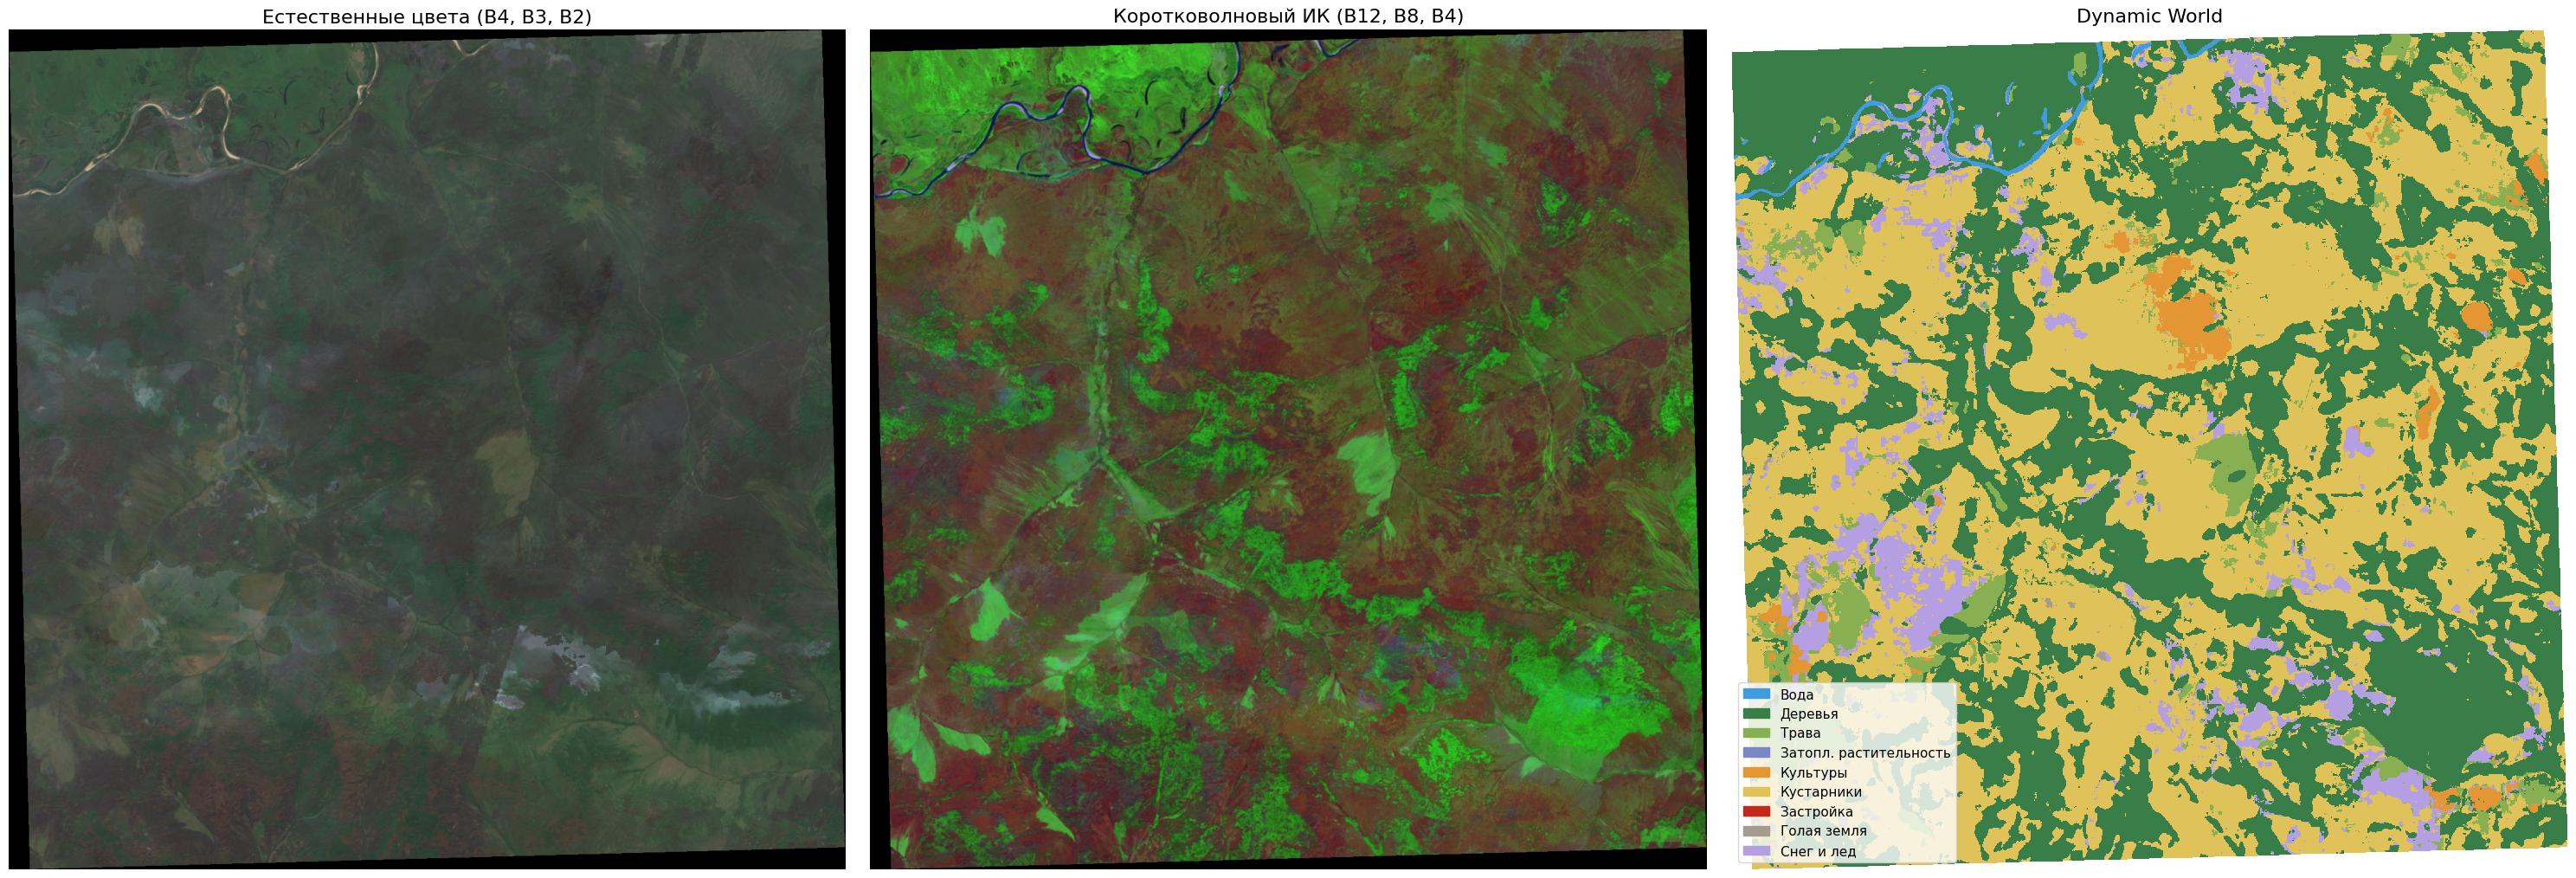

Кустарники                9070.3
Деревья                   8106.6
Снег и лед                1045.9
Трава                      877.6
Культуры                   303.2
Вода                        94.3
Голая земля                 71.3
Затопл. растительность       0.8
Name: Площадь, га, dtype: float64

In [9]:
#@title Готовая функция: снимок в естественных цветах и в комбинации B12-B8-B4
def stretch(x, high):
    """Линейное растяжение значений отражения в диапазон 0-1."""
    return np.clip(np.nan_to_num(x, nan=0, posinf=0, neginf=0) / high, 0, 1)

rgb = stretch(np.dstack([bands[2], bands[1], bands[0]]), 0.3) ** (1 / 1.4)   # B4, B3, B2
swir = np.dstack([stretch(bands[5], 0.4), stretch(bands[3], 0.45), stretch(bands[2], 0.25)])   # B12, B8, B4
dw_cmap = ListedColormap(DW_COLORS)
dw_legend = [Patch(color=col, label=name) for col, name in zip(DW_COLORS, DW_NAMES)]

fig, axes = plt.subplots(1, 3, figsize=(30, 10))
axes[0].imshow(rgb)
axes[0].set_title('Естественные цвета (B4, B3, B2)', fontsize=16)
axes[1].imshow(swir)
axes[1].set_title('Коротковолновый ИК (B12, B8, B4)', fontsize=16)
axes[2].imshow(np.ma.masked_less(dw, 0), cmap=dw_cmap, vmin=-0.5, vmax=8.5, interpolation='nearest')
axes[2].set_title('Dynamic World', fontsize=16)
axes[2].legend(handles=dw_legend, loc='lower left', fontsize=11)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

dw_areas = pd.Series(np.bincount(dw[valid], minlength=9) * PIXEL_AREA_HA, index=DW_NAMES, name='Площадь, га')
dw_areas[dw_areas > 0].sort_values(ascending=False).round(1)

**Задание 3.5 (продолжение).** Сравните три изображения. Запишите гипотезы: какие участки выглядят необычно на комбинации B12–B8–B4, хотя на снимке в естественных цветах не выделяются (или наоборот), и к какому классу Dynamic World их отнёс. Гипотезы проверите в разделе 5.

#### **Таблица 2. Гипотезы до анализа**

| № | Наблюдение (где, как выглядит в естественных цветах и в B12–B8–B4) | Класс Dynamic World | Гипотеза: что это за объект | Как проверить |
|---|---|---|---|---|
| 1 | Тёмно-бурые участки в центре и на юге; в ИК-комбинации красно-коричневые | В основном кустарники, местами другие классы | Гари и повреждённая растительность | Найти группу с низким B8 и NDVI и повышенным B12, посмотреть фрагменты |
| 2 | Зелёные участки среди бурых склонов, особенно на юго-востоке; в ИК ярко-зелёные | Деревья | Сохранившийся густой лес | Проверить высокий B8 и NDVI и совпадение с классом деревьев |
| 3 | Светлые серо-белые пятна юго-восточнее центра, с неровными и местами резкими краями | Смесь деревьев, кустарников, снега и льда | Остатки облаков или дымки в композите | Посмотреть крупные фрагменты и яркость в видимых каналах |


<details>
<summary><b>Пример формулировки</b></summary>

*Условный пример:* «В центре — светлое пятно неправильной формы около 2×3 км, в естественных цветах серо-бежевое, в B12–B8–B4 сиреневое, вокруг ярко-зелёная тайга. Dynamic World относит его к кустарникам и голой земле. Гипотеза: карьер и отвалы пустой породы. Проверка: отдельный кластер со спектром без растительности и высоким отражением в B11–B12».

</details>

**Ответ:** На обычном снимке тёмные участки местами похожи на тени или редкий лес. В комбинации B12–B8–B4 они заметно краснее, а живая растительность выглядит зелёной. Поэтому проверю не только светлые пятна, но и большие тёмные участки. Все три предположения записаны в таблице 2.


---

## **4. Классификация с учителем по разметке Dynamic World**

В лекции классификаторы обучались по карте ESA WorldCover. Здесь разметкой будет Dynamic World: классификатор учится по спектру пикселя предсказывать класс, который поставил бы Dynamic World. Это удобно — разметку не нужно создавать вручную, — но у такого подхода есть пределы: модель повторит и классы, и ошибки разметки. Их мы и увидим.

### **4.1. Стратифицированная обучающая выборка**

Классы на территории занимают очень разную площадь: например, тайга — десятки квадратных километров, застройка — несколько гектаров. Простая случайная выборка (`sample`) почти не содержит точек редких классов, и модель их не выучит. **Стратифицированная выборка** (`stratifiedSample`) берёт заданное число точек из каждого класса: если пикселей класса меньше, берутся все.

**Параметры метода `stratifiedSample`:**
- `numPoints` — число точек на класс
- `classBand` — канал с метками классов
- `region`, `scale` — область и размер пикселя выборки
- `seed` — начальное значение генератора для воспроизводимости
- `tileScale` — дробление вычислений на более мелкие плитки (помогает избежать ошибки нехватки памяти)

К каждой точке сразу добавим номер блока «шахматной доски» со стороной 1 км — он понадобится для пространственной проверки в разделе 4.2.

In [ ]:
# Номер блока шахматной доски 1×1 км: 0 — «чёрные» клетки, 1 — «белые»
BLOCK_SIZE = 1000
blocks = (ee.Image.pixelCoordinates(ee.Projection(utm_crs(roi)))
          .divide(BLOCK_SIZE).floor().reduce('sum').mod(2).toInt().rename('block'))

**Задание 4.1.** Получите выборку `samples`: по 400 точек каждого класса из изображения `composite.addBands(dynamic_world).addBands(blocks)` (`scale=SCALE`, `projection=utm_crs(roi)`, `seed=42`, `tileScale=4`). Проекция UTM обязательна: по умолчанию выборка берётся в географических координатах, где пиксель «10 м» по долготе в высоких широтах вдвое уже, и точки редких классов дублируются. Выведите число точек по классам (`aggregate_histogram('class')`) с названиями классов. Классы, у которых меньше 100 точек, исключите из выборки (`ee.Filter.inList`): по нескольким десяткам точек нельзя ни обучить, ни проверить модель. Список оставшихся кодов классов сохраните в `CLASSES`.

In [ ]:
samples = composite.addBands(dynamic_world).addBands(blocks).stratifiedSample(
    numPoints=400, classBand='class', region=roi, scale=SCALE,
    projection=utm_crs(roi), seed=42, tileScale=4)
histogram = samples.aggregate_histogram('class').getInfo()
sample_counts = pd.DataFrame([
    {'Код': int(k), 'Класс': DW_NAMES[int(k)], 'Точек': int(v),
     'Оставлен': v >= 100}
    for k, v in sorted(histogram.items(), key=lambda item: int(item[0]))
]).set_index('Код')
CLASSES = sample_counts.index[sample_counts['Оставлен']].tolist()
samples = samples.filter(ee.Filter.inList('class', CLASSES))
display(sample_counts)
print('Коды классов:', CLASSES)


Коды классов: [0, 1, 2, 4, 5, 7, 8]


,Класс,Точек,Оставлен
Код,,,
0,Вода,400,True
1,Деревья,400,True
2,Трава,400,True
3,Затопл. растительность,79,False
4,Культуры,400,True
5,Кустарники,400,True
7,Голая земля,400,True
8,Снег и лед,400,True


### **4.2. Случайная и пространственная проверка точности**

В лекции выборка делилась на обучающую и проверочную случайно (70/30). Но соседние пиксели снимка почти одинаковы: если один пиксель поля попал в обучение, а соседний — в проверку, модель «узнаёт» знакомое место, а не применяет выученное правило. Точность на такой проверке завышена. Честнее проверять модель на **других участках** территории: обучать на «чёрных» клетках шахматной доски, а проверять на «белых». Так оценивают, как модель поведёт себя на новом месте.

**Задание 4.2.** Создайте два разбиения выборки:
- случайное: `randomColumn('random', 42)`, обучение — `random < 0.7`, проверка — остальные;
- пространственное: обучение — `block == 0`, проверка — `block == 1`.

Для каждого разбиения обучите `ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42)` на признаках `FEATURES` и рассчитайте общую точность и каппу на проверочной части. Сохраните разбиения в словарь `splits = {'Случайная': (train, test), 'Пространственная': (train, test)}` и выведите таблицу результатов.

> 📚 **Подсказка:** [лекция по GEE](https://colab.research.google.com/drive/1BU-Q4D0XEIy2KiEtzw-3dKISE0lwGLV2), **раздел 4.2** (разделение по `randomColumn`) и **4.3** (`train`, `classify`, `errorMatrix`).

In [ ]:
random_samples = samples.randomColumn('random', 42)
splits = {
    'Случайная': (random_samples.filter(ee.Filter.lt('random', 0.7)),
                  random_samples.filter(ee.Filter.gte('random', 0.7))),
    'Пространственная': (samples.filter(ee.Filter.eq('block', 0)),
                         samples.filter(ee.Filter.eq('block', 1)))
}
rows = []
for name, (train, test) in splits.items():
    model = ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42).train(
        features=train, classProperty='class', inputProperties=FEATURES)
    matrix = test.classify(model).errorMatrix('class', 'classification')
    rows.append({'Проверка': name, 'Обучение': train.size().getInfo(),
                 'Проверочные точки': test.size().getInfo(),
                 'Точность': matrix.accuracy().getInfo(),
                 'Каппа': matrix.kappa().getInfo()})
split_metrics = pd.DataFrame(rows).set_index('Проверка')
display(split_metrics.round(4))


,Обучение,Проверочные точки,Точность,Каппа
Проверка,,,,
Случайная,1958,842,0.6306,0.5691
Пространственная,1427,1373,0.5899,0.5212


**Вопрос:** На сколько различаются точность и каппа случайного леса при случайной и пространственной проверке? Почему? Какой оценке вы бы доверяли, если модель нужно применить к соседнему участку тайги или к другому месторождению?

**Ответ:** При случайной проверке точность Random Forest равна 63,06%, каппа — 0,5691. При пространственной проверке получилось 58,99% и 0,5212. Разница — 4,07 процентного пункта по точности и 0,0479 по каппе. В случайное разбиение могут попасть близкие и похожие пиксели по обе стороны выборки. Для другого участка я бы ориентировался на пространственную проверку, но и она не гарантирует такую же точность в другом районе.


### **4.3. Сравнение классификаторов**

**Задание 4.3.** Выберите не менее трёх классификаторов из лекции (раздел 4.3) и сравните их **на пространственном разбиении**. Наивный байесовский классификатор не берите: он рассчитан на неотрицательные целые признаки (счётчики), а у нас дробные отражения и индексы. Сохраните обученные модели в словарь `models`, матрицы ошибок — в `matrices`, таблицу точности и каппы — в `metrics`, название лучшей модели по каппе — в `best_name`.

In [ ]:
classifiers = {
    'Random Forest': ee.Classifier.smileRandomForest(numberOfTrees=100, seed=42),
    'CART': ee.Classifier.smileCart(),
    'SVM': ee.Classifier.libsvm(kernelType='RBF', gamma=0.5, cost=10)
}
train, test = splits['Пространственная']
models, matrices, rows = {}, {}, []
for name, classifier in classifiers.items():
    models[name] = classifier.train(features=train, classProperty='class',
                                    inputProperties=FEATURES)
    matrices[name] = test.classify(models[name]).errorMatrix('class', 'classification')
    rows.append({'Модель': name, 'Точность': matrices[name].accuracy().getInfo(),
                 'Каппа': matrices[name].kappa().getInfo()})
metrics = pd.DataFrame(rows).set_index('Модель').sort_values('Каппа', ascending=False)
best_name = metrics.index[0]
display(metrics.round(4))
print('Лучшая модель:', best_name)


Лучшая модель: Random Forest


,Точность,Каппа
Модель,,
Random Forest,0.5899,0.5212
SVM,0.5586,0.4844
CART,0.4720,0.3840


### **4.4. Точность по классам**

Общая точность скрывает, какие классы модель путает. Для каждого класса считают две точности:

- **точность производителя** (`producersAccuracy`, она же полнота) — какая доля пикселей класса в разметке распознана моделью правильно; низкое значение означает, что модель **пропускает** класс;
- **точность пользователя** (`consumersAccuracy`, она же точность в смысле precision) — какая доля пикселей, отнесённых моделью к классу, действительно относится к нему; низкое значение означает, что модель **приписывает** классу чужие пиксели.

*Условный пример:* если из 100 пикселей «Застройки» модель нашла 60, точность производителя 0,6; если при этом она назвала «Застройкой» 80 пикселей и 60 из них верны, точность пользователя 0,75.

**Задание 4.4.** Для лучшей модели постройте таблицу `per_class`: название класса, точность производителя и точность пользователя для классов из `CLASSES`. Матрица ошибок GEE индексируется кодами классов, поэтому строка `producersAccuracy()` — это список длиной «максимальный код + 1». Постройте также тепловую карту матрицы ошибок, нормированной по строкам (истинным классам).

,Точность производителя,Точность пользователя
Класс,,
Вода,0.9221,0.8875
Деревья,0.7143,0.7104
Трава,0.5952,0.5682
Культуры,0.6600,0.5500
Кустарники,0.3959,0.3498
Голая земля,0.5183,0.6890
Снег и лед,0.4245,0.4918


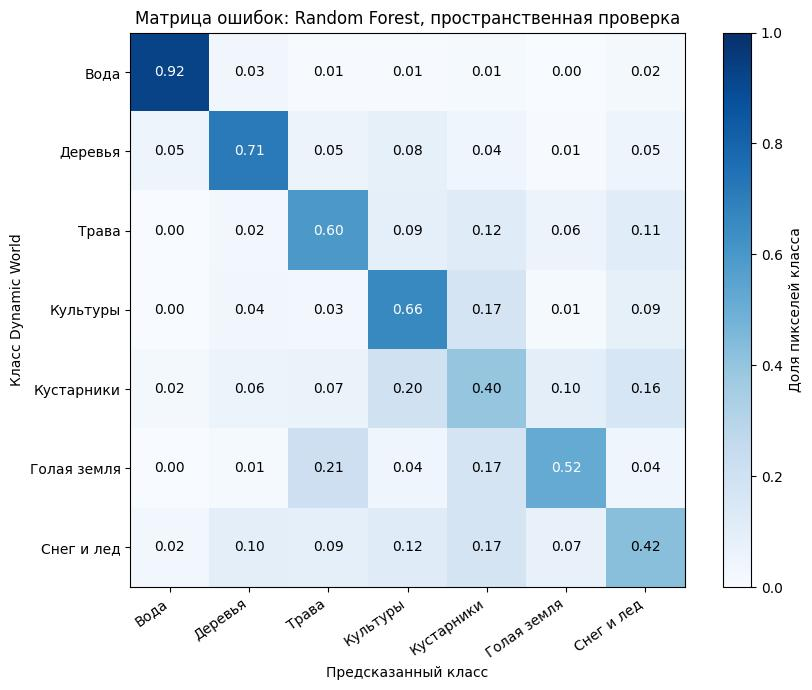

In [ ]:
matrix = matrices[best_name]
producer = np.array(matrix.producersAccuracy().getInfo()).ravel()
consumer = np.array(matrix.consumersAccuracy().getInfo()).ravel()
per_class = pd.DataFrame({
    'Класс': [DW_NAMES[c] for c in CLASSES],
    'Точность производителя': producer[CLASSES],
    'Точность пользователя': consumer[CLASSES]
}).set_index('Класс')
display(per_class.round(4))

cm = np.array(matrix.array().getInfo())[np.ix_(CLASSES, CLASSES)]
normalized = np.divide(cm, cm.sum(axis=1, keepdims=True),
                       out=np.zeros(cm.shape, dtype=float),
                       where=cm.sum(axis=1, keepdims=True) != 0)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(normalized, cmap='Blues', vmin=0, vmax=1)
names = [DW_NAMES[c] for c in CLASSES]
ax.set_xticks(range(len(names)), names, rotation=35, ha='right')
ax.set_yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f'{normalized[i, j]:.2f}', ha='center', va='center',
                color='white' if normalized[i, j] > 0.5 else 'black')
ax.set_xlabel('Предсказанный класс')
ax.set_ylabel('Класс Dynamic World')
ax.set_title(f'Матрица ошибок: {best_name}, пространственная проверка')
plt.colorbar(im, ax=ax, label='Доля пикселей класса')
plt.tight_layout()
plt.show()


**Вопрос:** Какие классы модель распознаёт лучше всего и хуже всего? С какими классами путается самый проблемный класс? Объясните, почему спектрально эти классы похожи.

**Ответ:** Лучше всего распознаётся вода: точность производителя 92,21%, пользователя 88,75%. У деревьев получилось 71,43% и 71,04%. Хуже всего модель находит кустарники: 39,59% и 34,98%. Из 197 проверочных точек кустарников правильно найдены 78; ещё 39 отнесены к культурам, 31 — к снегу и льду, 20 — к голой земле. На редких и повреждённых участках смешиваются грунт, трава и древесная растительность, поэтому спектры близки. Сами метки Dynamic World тоже могут быть ошибочными: снег и сельхозкультуры на такой летней территории требуют проверки по снимку.


### **4.5. Важность признаков**

Случайный лес оценивает, насколько каждый признак помогает разделять классы. В GEE оценки возвращает метод `explain()` обученной модели (ключ `importance`).

**Задание 4.5.** Получите важность признаков модели `models['Random Forest']`, переведите её в доли от суммы и постройте горизонтальную столбчатую диаграмму, отсортированную по убыванию важности.

ИК-каналы и индексы: 54.55 %


,Доля важности
B12,0.0880
B11,0.0848
B5,0.0799
NDBI,0.0787
B3,0.0778
B4,0.0762
B2,0.0754
NDVI,0.0747
B8A,0.0742
NDWI,0.0737


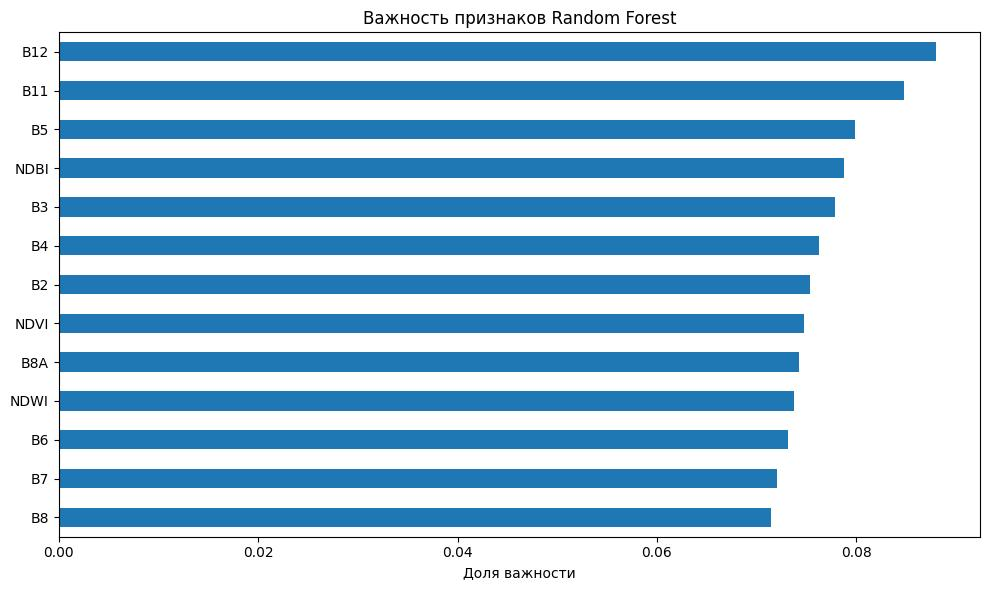

In [ ]:
importance = pd.Series(models['Random Forest'].explain().getInfo()['importance'],
                       name='Доля важности')
importance = (importance / importance.sum()).sort_values(ascending=False)
display(importance.to_frame().round(4))
fig, ax = plt.subplots(figsize=(10, 6))
importance.plot.barh(ax=ax)
ax.invert_yaxis()
ax.set_xlabel('Доля важности')
ax.set_title('Важность признаков Random Forest')
plt.tight_layout()
plt.show()
ir_names = ['B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI']
ir_importance = importance[ir_names].sum()
print('ИК-каналы и индексы:', round(ir_importance * 100, 2), '%')


**Вопрос:** Какие три признака наиболее важны? Какую долю важности дают инфракрасные каналы (B8, B8A, B11, B12) вместе с индексами, использующими их? Что это говорит о пользе каналов за пределами видимого диапазона?

**Ответ:** Три главных признака — B12 (8,80%), B11 (8,48%) и B5 (7,99%). Каналы B8, B8A, B11, B12 и индексы NDVI, NDWI, NDBI вместе дают 54,55% важности. Значит, для разделения этих поверхностей видимых каналов недостаточно. Особенно полезны B11 и B12: по ним повреждённые участки отличаются от живой растительности. Важность показывает вклад в эту модель, а не точность отдельного канала.


### **4.6. Карта классификации и сравнение с Dynamic World**

Для построения итоговой карты обучим лучшую модель заново **на всей выборке** (обучающей и проверочной частях): проверка уже выполнена, и лишние точки сделают модель только точнее.

**Задание 4.6.** Обучите классификатор `best_name` на всей выборке `samples`, классифицируйте `composite.select(FEATURES)`, экспортируйте карту в `data/classification.tif` (тип `int16`) и загрузите её в массив `classification`. Рассчитайте:
- долю пикселей, в которых классификация совпадает с Dynamic World;
- таблицу `areas`: площадь каждого класса по Dynamic World и по своей карте (га);
- маску несовпадений и покажите её на снимке рядом с обеими картами.

Совпадение карт: 53.93 %


,"Dynamic World, га","Своя карта, га","Разница, га"
Вода,94.32,433.93,339.61
Деревья,8106.59,6403.42,-1703.17
Трава,877.58,1157.99,280.41
Затопл. растительность,0.79,0.00,-0.79
Культуры,303.22,2252.74,1949.52
Кустарники,9070.29,4433.33,-4636.96
Застройка,0.00,0.00,0.00
Голая земля,71.34,1713.47,1642.13
Снег и лед,1045.90,3175.15,2129.25


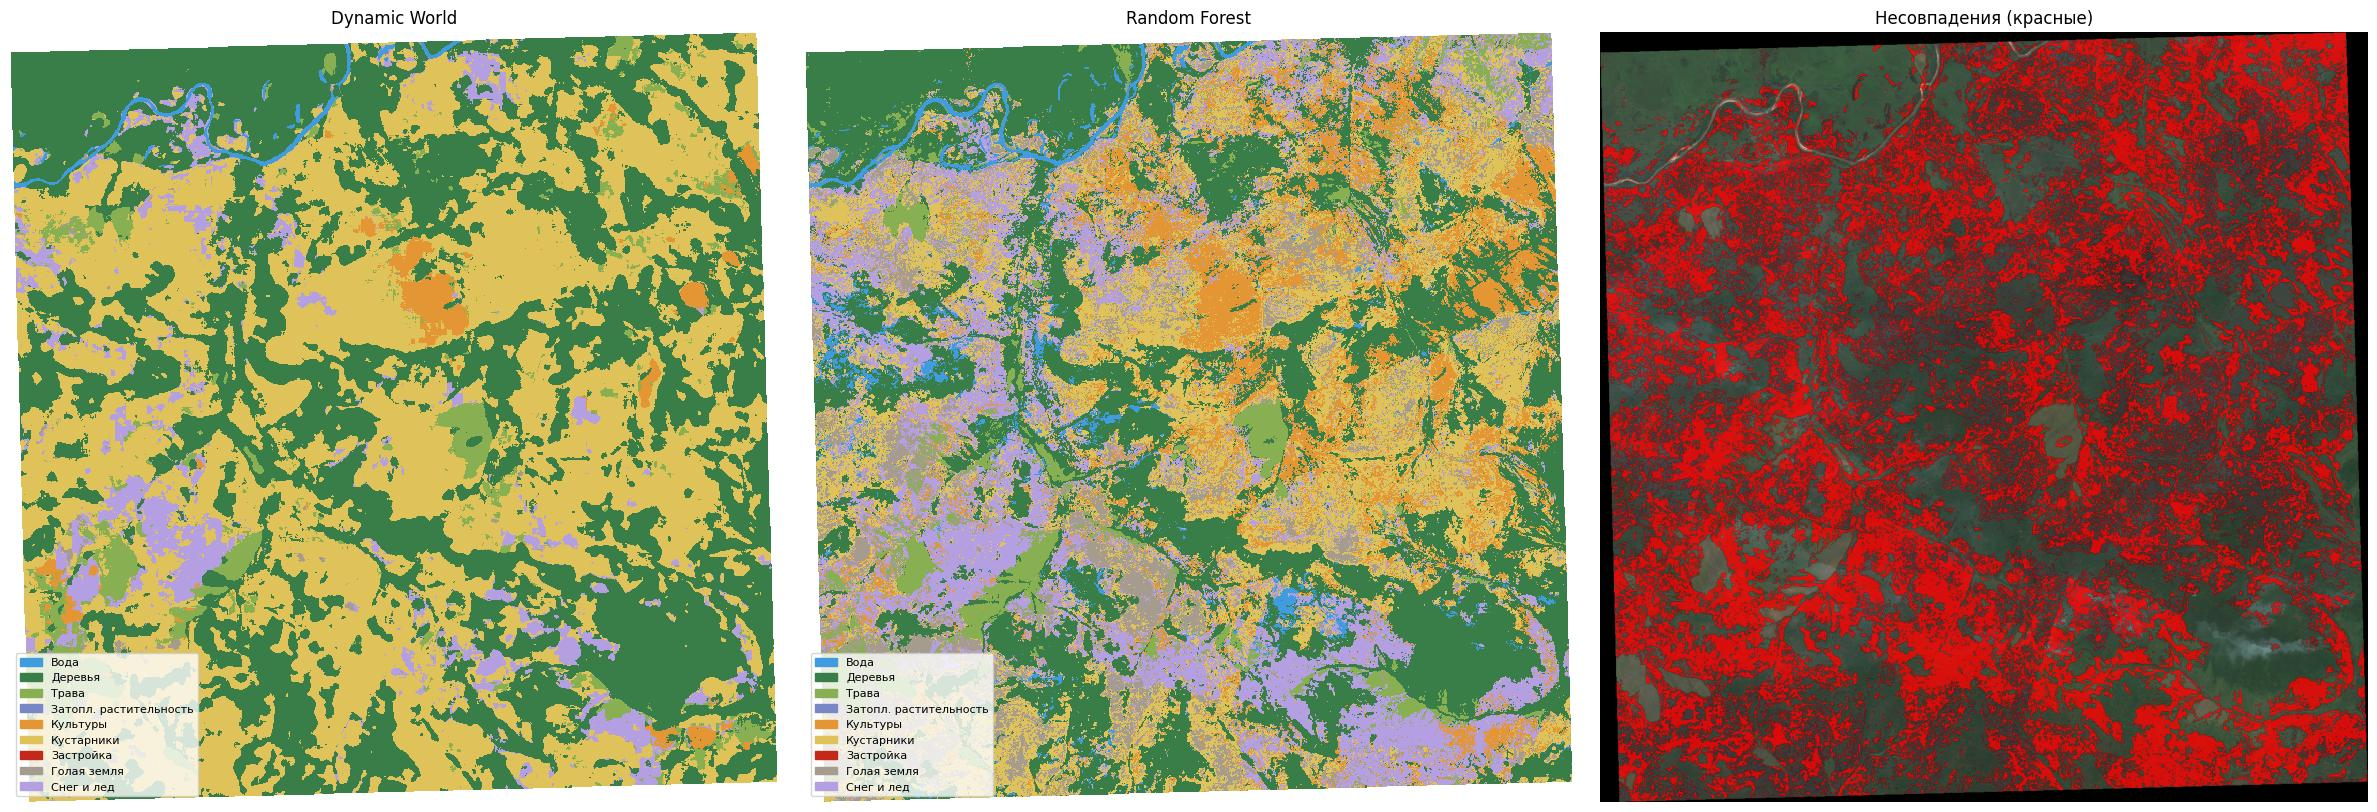

In [ ]:
final_model = classifiers[best_name].train(features=samples,
                classProperty='class', inputProperties=FEATURES)
classified = composite.select(FEATURES).classify(final_model)
export_georeferenced_raster(classified, roi,
                           'data/classification.tif', dtype='int16')
with rasterio.open('data/classification.tif') as src:
    assert src.shape == (H, W) and src.transform == grid and src.crs == raster_crs
    classification = src.read(1, masked=True).filled(-1).astype('int16')
comparison_valid = valid & (classification >= 0)
agreement = np.mean(classification[comparison_valid] == dw[comparison_valid])
areas = pd.DataFrame({
    'Dynamic World, га': np.bincount(dw[comparison_valid], minlength=9) * PIXEL_AREA_HA,
    'Своя карта, га': np.bincount(classification[comparison_valid], minlength=9) * PIXEL_AREA_HA
}, index=DW_NAMES)
areas['Разница, га'] = areas['Своя карта, га'] - areas['Dynamic World, га']
display(areas.round(2))
print('Совпадение карт:', round(agreement * 100, 2), '%')
disagreement = comparison_valid & (classification != dw)
fig, axes = plt.subplots(1, 3, figsize=(24, 8))
for ax, arr, title in zip(axes[:2], [dw, classification], ['Dynamic World', best_name]):
    ax.imshow(np.ma.masked_where(~comparison_valid, arr), cmap=dw_cmap,
              vmin=-0.5, vmax=8.5, interpolation='nearest')
    ax.set_title(title)
    ax.legend(handles=dw_legend, loc='lower left', fontsize=8)
axes[2].imshow(rgb)
axes[2].imshow(np.ma.masked_where(~disagreement, disagreement),
               cmap=ListedColormap(['red']), alpha=0.8)
axes[2].set_title('Несовпадения (красные)')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()


**Вопрос:** Какова доля совпадения карт? Где сосредоточены несовпадения — на границах объектов, в каких-то конкретных типах местности? Площади каких классов различаются сильнее всего?

**Ответ:** Карты совпали в 53,93% пикселей. Несовпадения есть на границах, но занимают и большие участки гарей и смешанной растительности. Самая большая разница — у кустарников: 9070,29 га по Dynamic World и 4433,33 га по своей карте, то есть на 4636,96 га меньше. Модель также получила больше снега и льда на 2129,25 га, культур на 1949,52 га и голой земли на 1642,13 га. Эти прибавки нельзя сразу считать реальными изменениями покрова. Выборка была уравнена по классам, а на всей территории площади классов сильно различаются; кроме того, модель воспроизводит не все метки готовой карты.


**Вопрос:** Рассмотрите объекты, которые вы описали в гипотезах (таблица 2). К каким классам отнесли их Dynamic World и ваша модель? Может ли классификатор, обученный по разметке Dynamic World, выделить такие объекты как отдельный класс? Почему?

**Ответ:** Тёмные участки, похожие на гари, Dynamic World в основном отнёс к кустарникам. Своя модель распределила их между кустарниками, голой землёй и другими классами. Зелёные участки чаще относятся к деревьям. У светлых пятен разметка смешанная. Выделить «гарь» или «остатки облаков» как новый класс классификатор не может: таких названий не было среди обучающих меток. Точные доли для выбранного кластера приведены ниже, в разделе 5.5.


### **4.7. Выводы по разделу 4**

Опишите, насколько точно модель воспроизводит Dynamic World при честной проверке, какие классы и признаки для неё важнее, и в чём главное ограничение обучения по готовой карте.

**Вывод:** Из трёх моделей на пространственной проверке лучше оказался Random Forest: точность 58,99%, каппа 0,5212. У SVM — 55,86% и 0,4844, у CART — 47,20% и 0,3840. Вода определяется лучше кустарников. Два самых важных канала — B12 и B11. Совпадение готовых карт по всей области составило 53,93%, поэтому свою карту нельзя считать точной копией Dynamic World. Главное ограничение — обучение по готовым меткам не добавляет классов и не исправляет автоматически ошибки исходной разметки.


---

## **5. Кластеризация в Google Earth Engine: поиск того, чего нет в легенде**

Классификатор умеет только то, чему его научили: каждому пикселю он присваивает один из классов разметки. Кластеризация не знает никаких классов и группирует пиксели по сходству спектра. Если на территории есть объекты, спектрально непохожие на всё остальное, они могут образовать собственный кластер — даже если в легенде для них нет класса и на снимке в естественных цветах они почти не видны.

### **5.1. Стандартизация признаков в GEE**

Кластеризовать будем по восьми признакам `LOCAL_BANDS`: шести каналам отражения и индексам NDVI и NDWI. Отражение меняется в пределах 0–0,6, а индексы — от −1 до 1, поэтому без масштабирования индексы определяли бы расстояния между пикселями сильнее каналов. Стандартизация приводит каждый признак к среднему 0 и стандартному отклонению 1: $z = (x - \mu) / \sigma$.

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 2.5** (масштабирование признаков); в GEE среднее и стандартное отклонение каналов по области даёт `image.reduceRegion(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True), region, scale=..., bestEffort=True)`, ключи результата — `B2_mean`, `B2_stdDev` и т. д.

**Задание 5.1.** Допишите функцию `standardize(image, region)`: она рассчитывает по области средние и стандартные отклонения всех каналов (`scale=30` — для оценки статистик этого достаточно), возвращает стандартизированное изображение и два списка — средние и стандартные отклонения в порядке каналов. Получите `cluster_input, means, stds`.

In [ ]:
def standardize(image, region):
    """Стандартизация каналов изображения по статистикам области: (x - среднее) / стандартное отклонение."""
    names = image.bandNames().getInfo()
    stats = image.reduceRegion(
        reducer=ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True),
        geometry=region, scale=30, bestEffort=True, maxPixels=100000000).getInfo()
    means = [stats[name + '_mean'] for name in names]
    stds = [max(stats[name + '_stdDev'], 1e-8) for name in names]
    standardized = image.subtract(ee.Image.constant(means)).divide(
        ee.Image.constant(stds)).rename(names)
    return standardized, means, stds

cluster_input, means, stds = standardize(composite.select(LOCAL_BANDS), roi)
display(pd.DataFrame({'Среднее': means, 'Стандартное отклонение': stds},
                     index=LOCAL_BANDS).round(4))


,Среднее,Стандартное отклонение
B2,0.0438,0.0089
B3,0.0533,0.0108
B4,0.0445,0.0099
B8,0.1529,0.0550
B11,0.1656,0.0220
B12,0.1191,0.0244
NDVI,0.5214,0.1336
NDWI,-0.4604,0.1075


### **5.2. K-средних на серверах GEE при разных K**

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 3.5** (`ee.Clusterer.wekaKMeans`, `train`, `cluster`).

Число кластеров заранее неизвестно. При малом $K$ редкие объекты «прилипают» к крупным кластерам, при большом — крупные однородные поверхности дробятся на части. Поэтому построим разбиения сразу для нескольких $K$ и сравним их.

**Задание 5.2.** Получите обучающую выборку `training` из `cluster_input` (10 000 пикселей, `scale=SCALE`, `projection=utm_crs(roi)`, `seed=42`, `tileScale=4`). Для `K_LIST = [6, 12, 18]` обучите `ee.Clusterer.wekaKMeans(nClusters=K, init=1, seed=42)` и кластеризуйте `cluster_input`. Объедините карты в одно изображение `clusters` с каналами `K6`, `K12`, `K18` (`ee.Image.cat`), покажите кластеры при $K = 12$ на интерактивной карте (`randomVisualizer()`) и экспортируйте `clusters` в `data/clusters.tif` (тип `int16`). Загрузите результат в массив `cluster_maps` (каналы — разные $K$).

Карт кластеров: 3


Кластеры K = 12
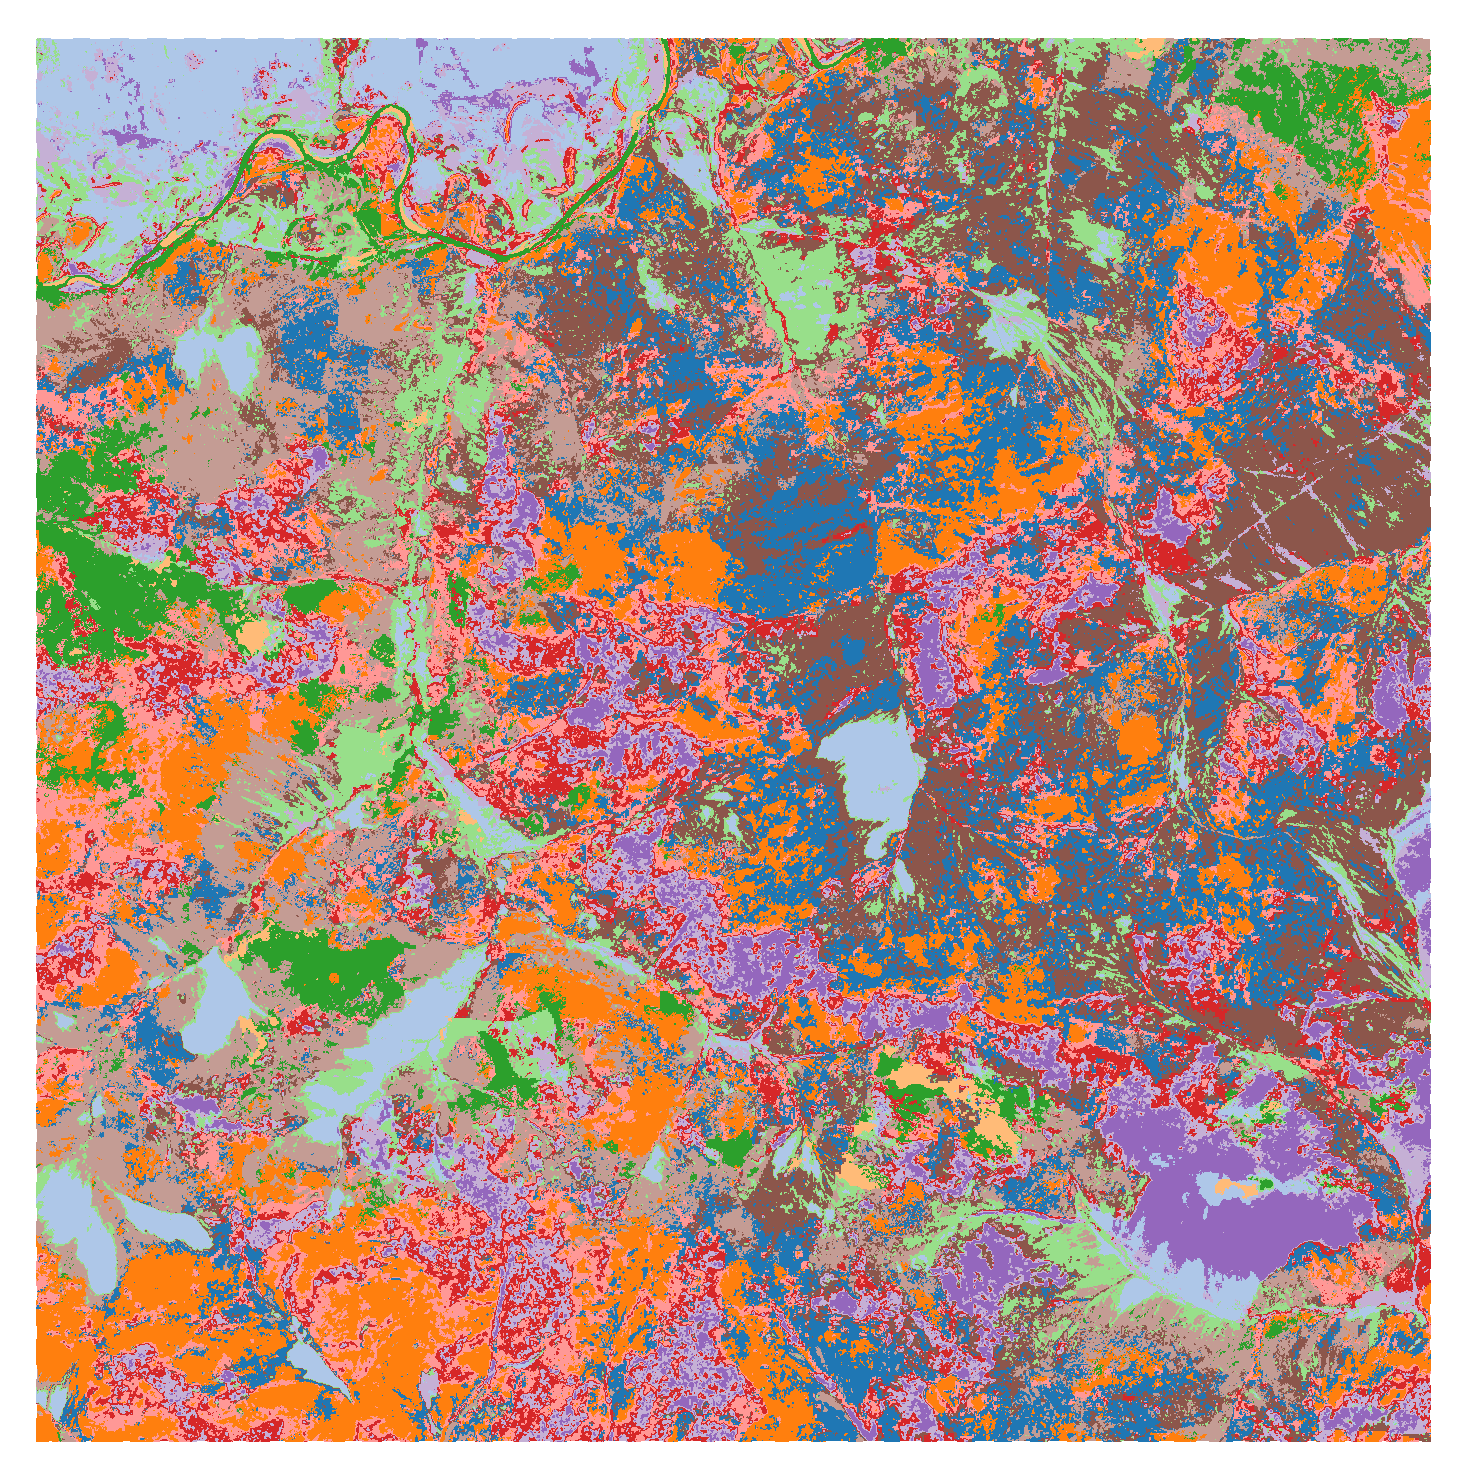

In [ ]:
K_LIST = [6, 12, 18]
training = cluster_input.sample(region=roi, scale=SCALE,
           projection=utm_crs(roi), numPixels=10000, seed=42, tileScale=4)
cluster_images = []
for k in K_LIST:
    clusterer = ee.Clusterer.wekaKMeans(nClusters=k, init=1, seed=42).train(training)
    cluster_images.append(cluster_input.cluster(clusterer).rename(f'K{k}'))
clusters = ee.Image.cat(cluster_images)
map_clusters = geemap.Map()
map_clusters.add_basemap('Esri.WorldImagery')
map_clusters.centerObject(roi, 12)
map_clusters.addLayer(clusters.select('K12').randomVisualizer(), {}, 'Кластеры K = 12')
display(map_clusters)
export_georeferenced_raster(clusters, roi, 'data/clusters.tif', dtype='int16')
with rasterio.open('data/clusters.tif') as src:
    assert src.shape == (H, W) and src.transform == grid and src.crs == raster_crs
    cluster_maps = src.read(masked=True).filled(-1).astype('int16')
valid = valid & comparison_valid & (cluster_maps >= 0).all(axis=0)
print('Карт кластеров:', len(cluster_maps))


### **5.3. Площади и спектральные профили кластеров**

> 📚 **Подсказка:** лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **разделы 3.3–3.4** (спектральные профили, состав кластеров по Dynamic World).

Кроме профилей, оценим **необычность** каждого кластера — расстояние от его центроида до «среднего» пикселя территории в пространстве стандартизированных признаков. После стандартизации средний пиксель находится в начале координат, поэтому необычность — это просто длина вектора центроида: $\lVert c_k
Vert = \sqrt{\sum_j c_{kj}^2}$. Кластеры фоновых поверхностей, занимающих большую часть территории, лежат близко к среднему, а спектрально непохожие на фон группы — далеко от него, независимо от их площади. Центроиды кластеров GEE вычислим сами: это средние стандартизированные признаки пикселей каждого кластера.

**Задание 5.3.** Для разбиения с $K = 12$ (`labels = cluster_maps[1]`):
- стандартизируйте признаки пикселей `pixels` теми же `means` и `stds`, что и в GEE (массив `z`), и рассчитайте центроиды кластеров `centroids` (форма $(K, 8)$);
- постройте таблицу `profiles`: для каждого кластера — площадь (га), доля площади (%), необычность и средние значения восьми признаков `LOCAL_BANDS` (по массиву `bands`); отсортируйте её по площади;
- покажите карту кластеров рядом со снимком и график спектральных профилей шести каналов (по оси X — каналы, по оси Y — среднее отражение, по линии на кластер).

In [18]:
K = 12
labels = cluster_maps[K_LIST.index(K)]
cluster_colors = plt.cm.tab20(np.linspace(0, 1, 20))[:K]
cluster_cmap = ListedColormap(cluster_colors)

,B2,B3,B4,B8,B11,B12,NDVI,NDWI,"Площадь, га","Доля площади, %",Необычность
Кластер,,,,,,,,,,,
3,0.0946,0.1017,0.0932,0.1820,0.1770,0.1299,0.3222,-0.2732,116.44,0.5950,9.1085
4,0.0610,0.0678,0.0578,0.1177,0.1496,0.1191,0.3322,-0.2611,829.62,4.2392,3.7061
8,0.0377,0.0538,0.0313,0.2725,0.1460,0.0693,0.7928,-0.6696,832.19,4.2524,4.4570
1,0.0491,0.0701,0.0523,0.2764,0.2030,0.1068,0.6825,-0.5938,1125.66,5.7520,3.8152
5,0.0499,0.0645,0.0526,0.2014,0.1905,0.1200,0.5863,-0.5142,1340.25,6.8485,2.1800
9,0.0401,0.0537,0.0363,0.2085,0.1503,0.0815,0.7034,-0.5905,1406.67,7.1879,2.8405
6,0.0400,0.0491,0.0387,0.1513,0.1445,0.0917,0.5922,-0.5098,1452.14,7.4202,1.8334
7,0.0414,0.0468,0.0437,0.1132,0.1484,0.1101,0.4418,-0.4146,1925.59,9.8395,1.5007
11,0.0497,0.0599,0.0514,0.1389,0.1769,0.1389,0.4593,-0.3965,2299.11,11.7481,1.6871


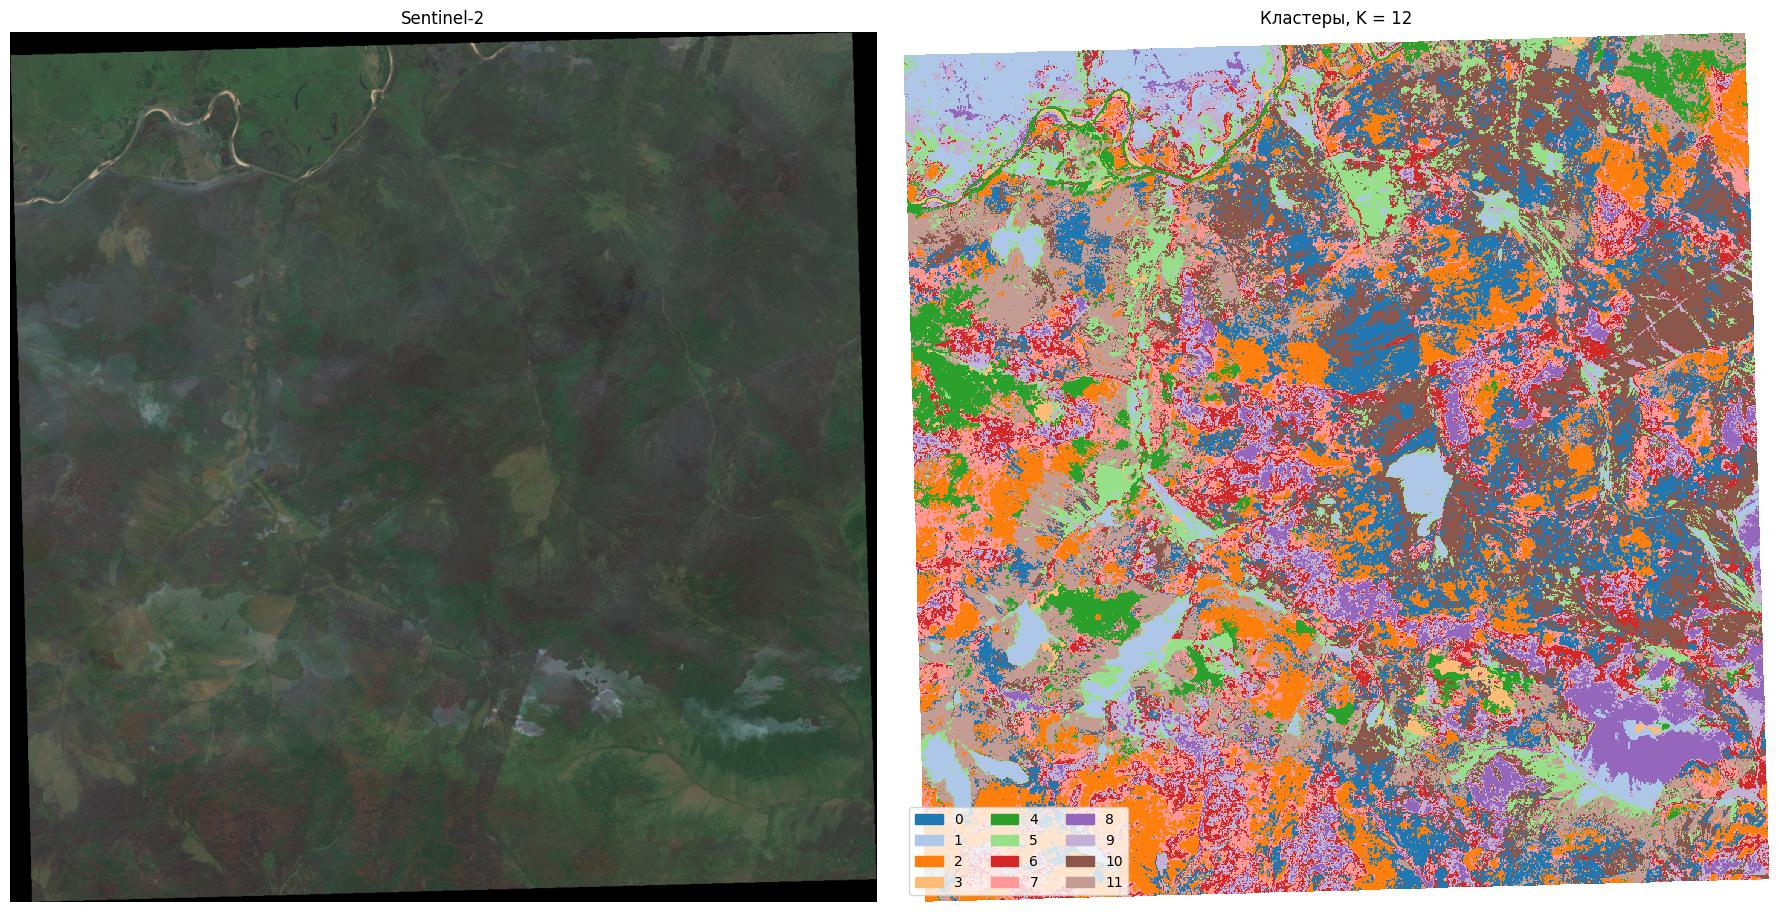

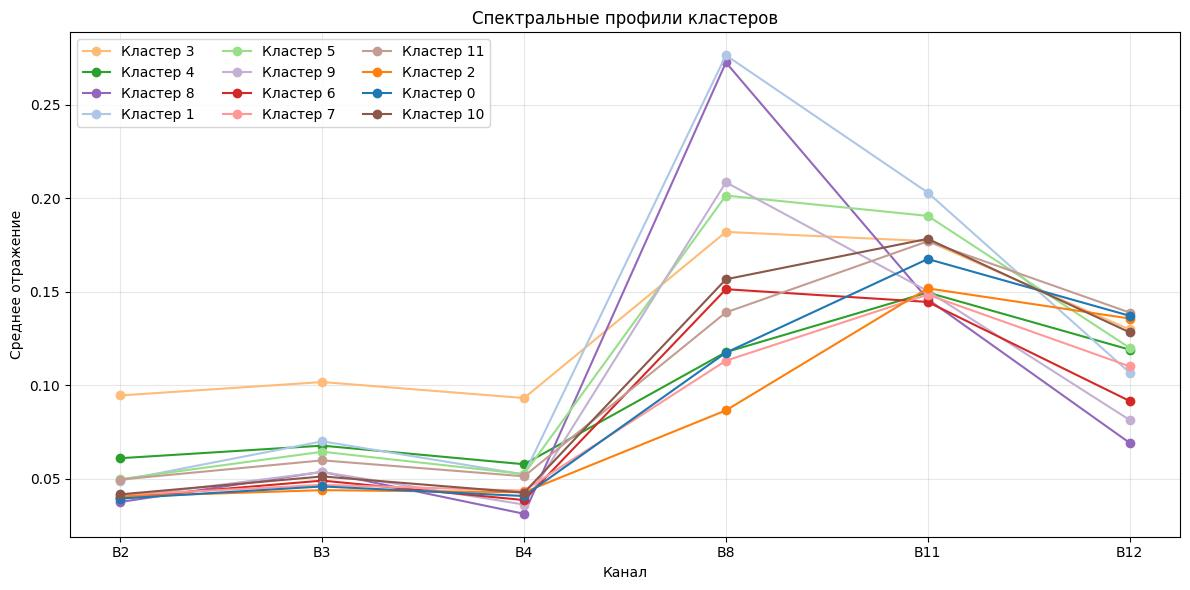

In [19]:
pixels = bands[:, valid].T
z = (pixels - np.array(means)) / np.array(stds)
pixel_labels = labels[valid]
centroids = np.array([z[pixel_labels == k].mean(axis=0) for k in range(K)])
profile_values = np.array([pixels[pixel_labels == k].mean(axis=0) for k in range(K)])
counts = np.bincount(pixel_labels, minlength=K)
profiles = pd.DataFrame(profile_values, columns=LOCAL_BANDS)
profiles['Площадь, га'] = counts * PIXEL_AREA_HA
profiles['Доля площади, %'] = counts / counts.sum() * 100
profiles['Необычность'] = np.linalg.norm(centroids, axis=1)
profiles.index.name = 'Кластер'
profiles = profiles.sort_values('Площадь, га')
display(profiles.round(4))
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
axes[0].imshow(rgb)
axes[0].set_title('Sentinel-2')
axes[1].imshow(np.ma.masked_where(~valid, labels), cmap=cluster_cmap,
               vmin=-0.5, vmax=K-0.5, interpolation='nearest')
axes[1].set_title('Кластеры, K = 12')
axes[1].legend(handles=[Patch(color=cluster_colors[k], label=str(k)) for k in range(K)],
                loc='lower left', ncol=3)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(12, 6))
for k in profiles.index:
    ax.plot(LOCAL_BANDS[:6], profiles.loc[k, LOCAL_BANDS[:6]], 'o-',
            color=cluster_colors[k], label=f'Кластер {k}')
ax.set_xlabel('Канал')
ax.set_ylabel('Среднее отражение')
ax.set_title('Спектральные профили кластеров')
ax.legend(ncol=3)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### **5.4. Состав кластеров по Dynamic World и по своей классификации**

**Задание 5.4.** Постройте две таблицы сопряжённости, нормированные по строкам (%): кластер × класс Dynamic World (`dw`) и кластер × класс вашей классификации (`classification`). Строки упорядочите так же, как в `profiles` (по площади). Выведите их рядом в виде тепловых карт.

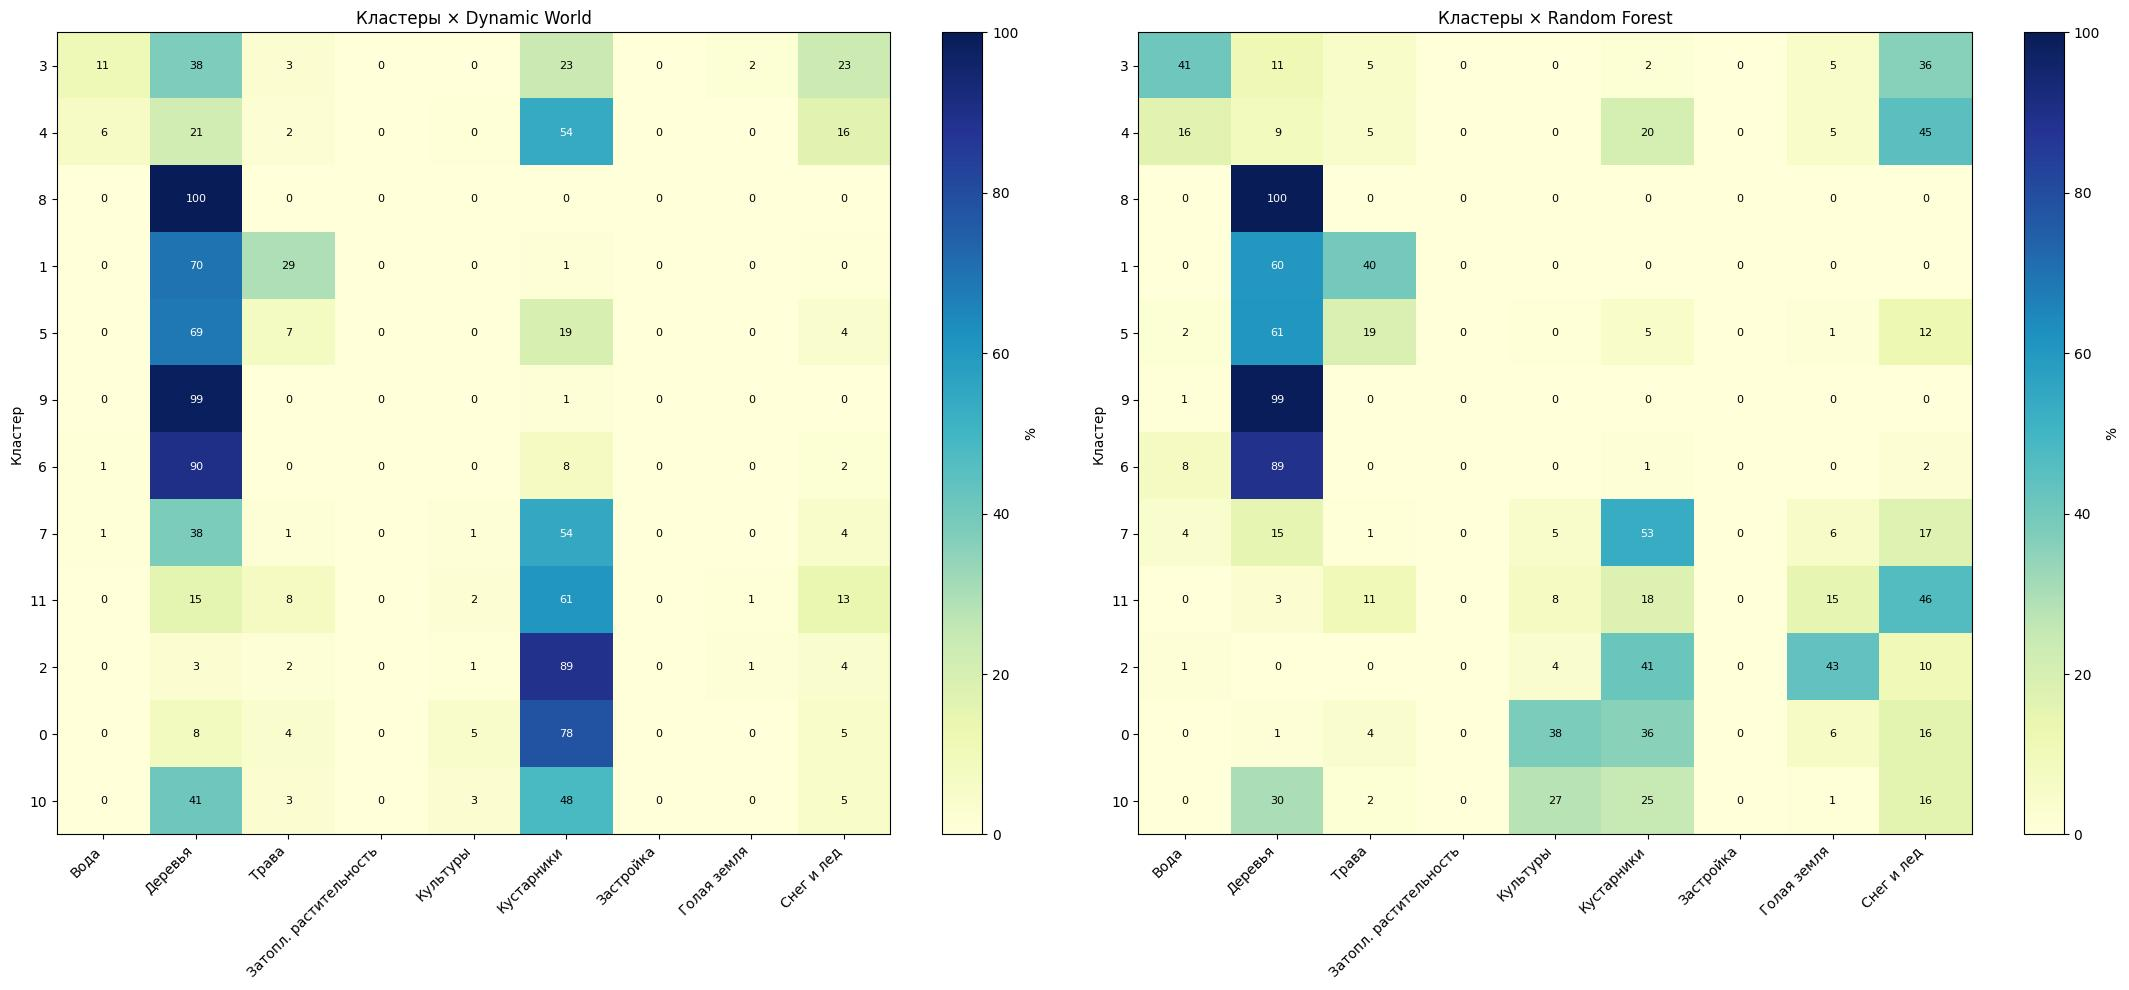

In [20]:
cluster_dw = pd.crosstab(labels[valid], dw[valid], normalize='index') * 100
cluster_class = pd.crosstab(labels[valid], classification[valid], normalize='index') * 100
cluster_dw = cluster_dw.reindex(index=profiles.index, columns=range(9), fill_value=0)
cluster_class = cluster_class.reindex(index=profiles.index, columns=range(9), fill_value=0)
fig, axes = plt.subplots(1, 2, figsize=(22, 10))
for ax, table, title in zip(axes, [cluster_dw, cluster_class],
                           ['Кластеры × Dynamic World', f'Кластеры × {best_name}']):
    im = ax.imshow(table, cmap='YlGnBu', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(9), DW_NAMES, rotation=45, ha='right')
    ax.set_yticks(range(K), table.index)
    for i in range(K):
        for j in range(9):
            ax.text(j, i, f'{table.iloc[i, j]:.0f}', ha='center', va='center',
                    color='white' if table.iloc[i, j] > 50 else 'black', fontsize=8)
    ax.set_ylabel('Кластер')
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label='%')
plt.tight_layout()
plt.show()


**Задание 5.4 (продолжение).** По профилям, составу и виду на карте дайте названия всем кластерам и заполните таблицу. Названия — ваша интерпретация, а не результат алгоритма.

#### **Таблица 3. Интерпретация кластеров (K = 12)**

| Кластер | Площадь, га | Спектральный профиль | Состав по Dynamic World | Название |
|---|---|---|---|---|
| 3 | 116,44 | B8 0,182; B12 0,130; NDVI 0,322 | Деревья 37,7%; Кустарники 23,5% | Остатки облаков и дымка |
| 4 | 829,62 | B8 0,118; B12 0,119; NDVI 0,332 | Кустарники 53,7%; Деревья 21,1% | Светлые смешанные участки с дымкой |
| 8 | 832,19 | B8 0,272; B12 0,069; NDVI 0,793 | Деревья 99,9% | Густая зелёная растительность |
| 1 | 1125,66 | B8 0,276; B12 0,107; NDVI 0,682 | Деревья 69,5%; Трава 29,1% | Зелёная пойменная растительность |
| 5 | 1340,25 | B8 0,201; B12 0,120; NDVI 0,586 | Деревья 68,7%; Кустарники 19,2% | Разреженный лес и кустарники |
| 9 | 1406,67 | B8 0,208; B12 0,082; NDVI 0,703 | Деревья 98,6%; Кустарники 0,9% | Лес с высоким отражением в B8 |
| 6 | 1452,14 | B8 0,151; B12 0,092; NDVI 0,592 | Деревья 89,5%; Кустарники 7,8% | Тёмный таёжный лес |
| 7 | 1925,59 | B8 0,113; B12 0,110; NDVI 0,442 | Кустарники 54,5%; Деревья 38,1% | Переход от леса к повреждённым участкам |
| 11 | 2299,11 | B8 0,139; B12 0,139; NDVI 0,459 | Кустарники 60,8%; Деревья 15,3% | Открытые участки с редкой растительностью |
| 2 | 2385,61 | B8 0,087; B12 0,136; NDVI 0,335 | Кустарники 89,0%; Снег и лед 4,1% | Тёмные участки, похожие на гари |
| 0 | 2712,33 | B8 0,117; B12 0,137; NDVI 0,483 | Кустарники 78,2%; Деревья 8,1% | Повреждённые участки с редкой растительностью |
| 10 | 3144,42 | B8 0,157; B12 0,128; NDVI 0,571 | Кустарники 48,1%; Деревья 41,0% | Смешанная лесная и кустарниковая растительность |


**Таблица 3:** Названия — моя интерпретация по виду участков, профилям и составу кластеров.


### **5.5. Необычные кластеры: «иголка в стоге сена»**

Первые кандидаты на интересные объекты — кластеры, далёкие от фона: алгоритм отвёл им собственный центроид, потому что их спектр не похож на спектр основной части территории. Часто это и самые маленькие кластеры, но не всегда: крупный карьер или большая гарь могут занимать сотни гектаров и всё же резко отличаться от окружающего леса, а несколько маленьких кластеров могут оказаться оттенками фона. Поэтому ориентируемся на необычность, а площадь учитываем при интерпретации.

In [21]:
#@title Готовая функция: фрагменты снимка с подсветкой пикселей маски
def zoom_views(mask, n=3, size=60, color=(1, 0, 0), title=''):
    """n фрагментов с наибольшей плотностью пикселей маски: снимок, B12-B8-B4 и подсветка."""
    step = 2 * size
    density = np.add.reduceat(np.add.reduceat(mask.astype(int), np.arange(0, H, step), axis=0), np.arange(0, W, step), axis=1)
    best = np.dstack(np.unravel_index(np.argsort(density.ravel())[::-1][:n], density.shape))[0]
    fig, axes = plt.subplots(3, n, figsize=(6 * n, 18))
    for j, (r, c) in enumerate(best):
        r = min(max(r * step + size, size), H - size)
        c = min(max(c * step + size, size), W - size)
        window = np.s_[r - size:r + size, c - size:c + size]
        highlight = rgb[window].copy()
        highlight[mask[window]] = color
        for i, img in enumerate([rgb[window], swir[window], highlight]):
            axes[i, j].imshow(img)
            axes[i, j].axis('off')
        axes[0, j].set_title(f'Фрагмент {j + 1}: строка {r}, столбец {c}')
    fig.suptitle(title, fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

**Задание 5.5.** Выведите три кластера с наибольшей необычностью с площадью и двумя главными классами Dynamic World и покажите для каждого карту расположения пикселей на снимке и фрагменты крупным планом (`zoom_views(labels == k, title=...)`). Затем выберите кластеры, которые вы считаете «иголками» — объектами, не имеющими своего класса в Dynamic World, — и запишите их номера в список `NEEDLES`.

,"Площадь, га","Доля площади, %",Необычность,Главные классы DW
Кластер,,,,
3,116.44,0.595,9.108,Деревья: 37.7%; Кустарники: 23.5%
8,832.19,4.252,4.457,Деревья: 99.9%; Снег и лед: 0.0%
1,1125.66,5.752,3.815,Деревья: 69.5%; Трава: 29.1%


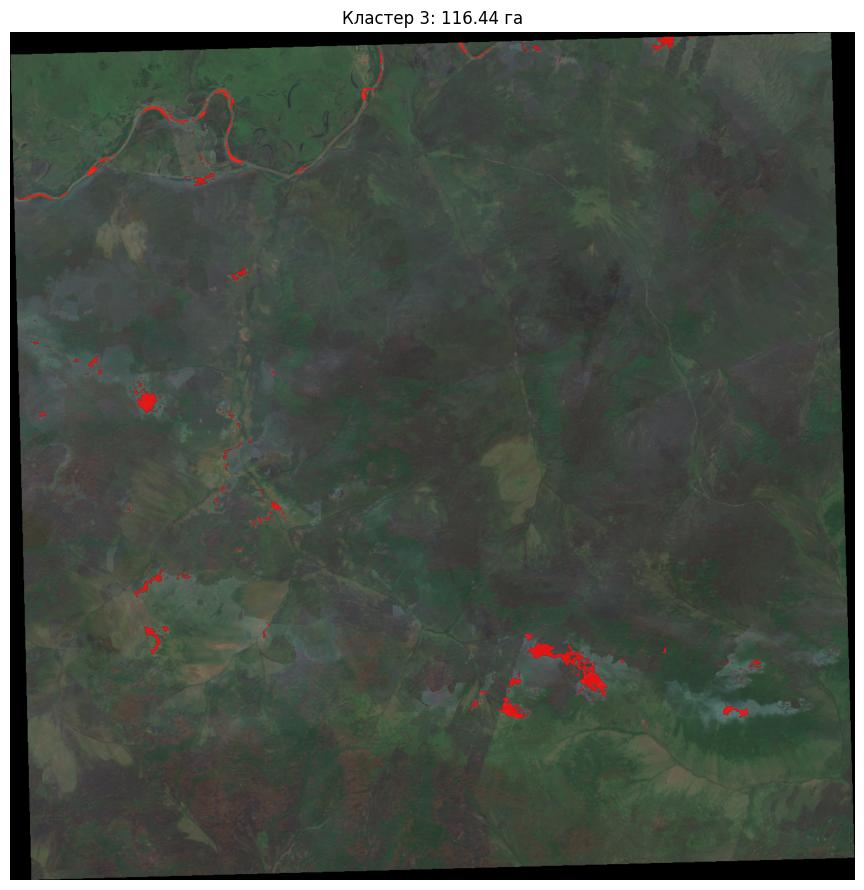

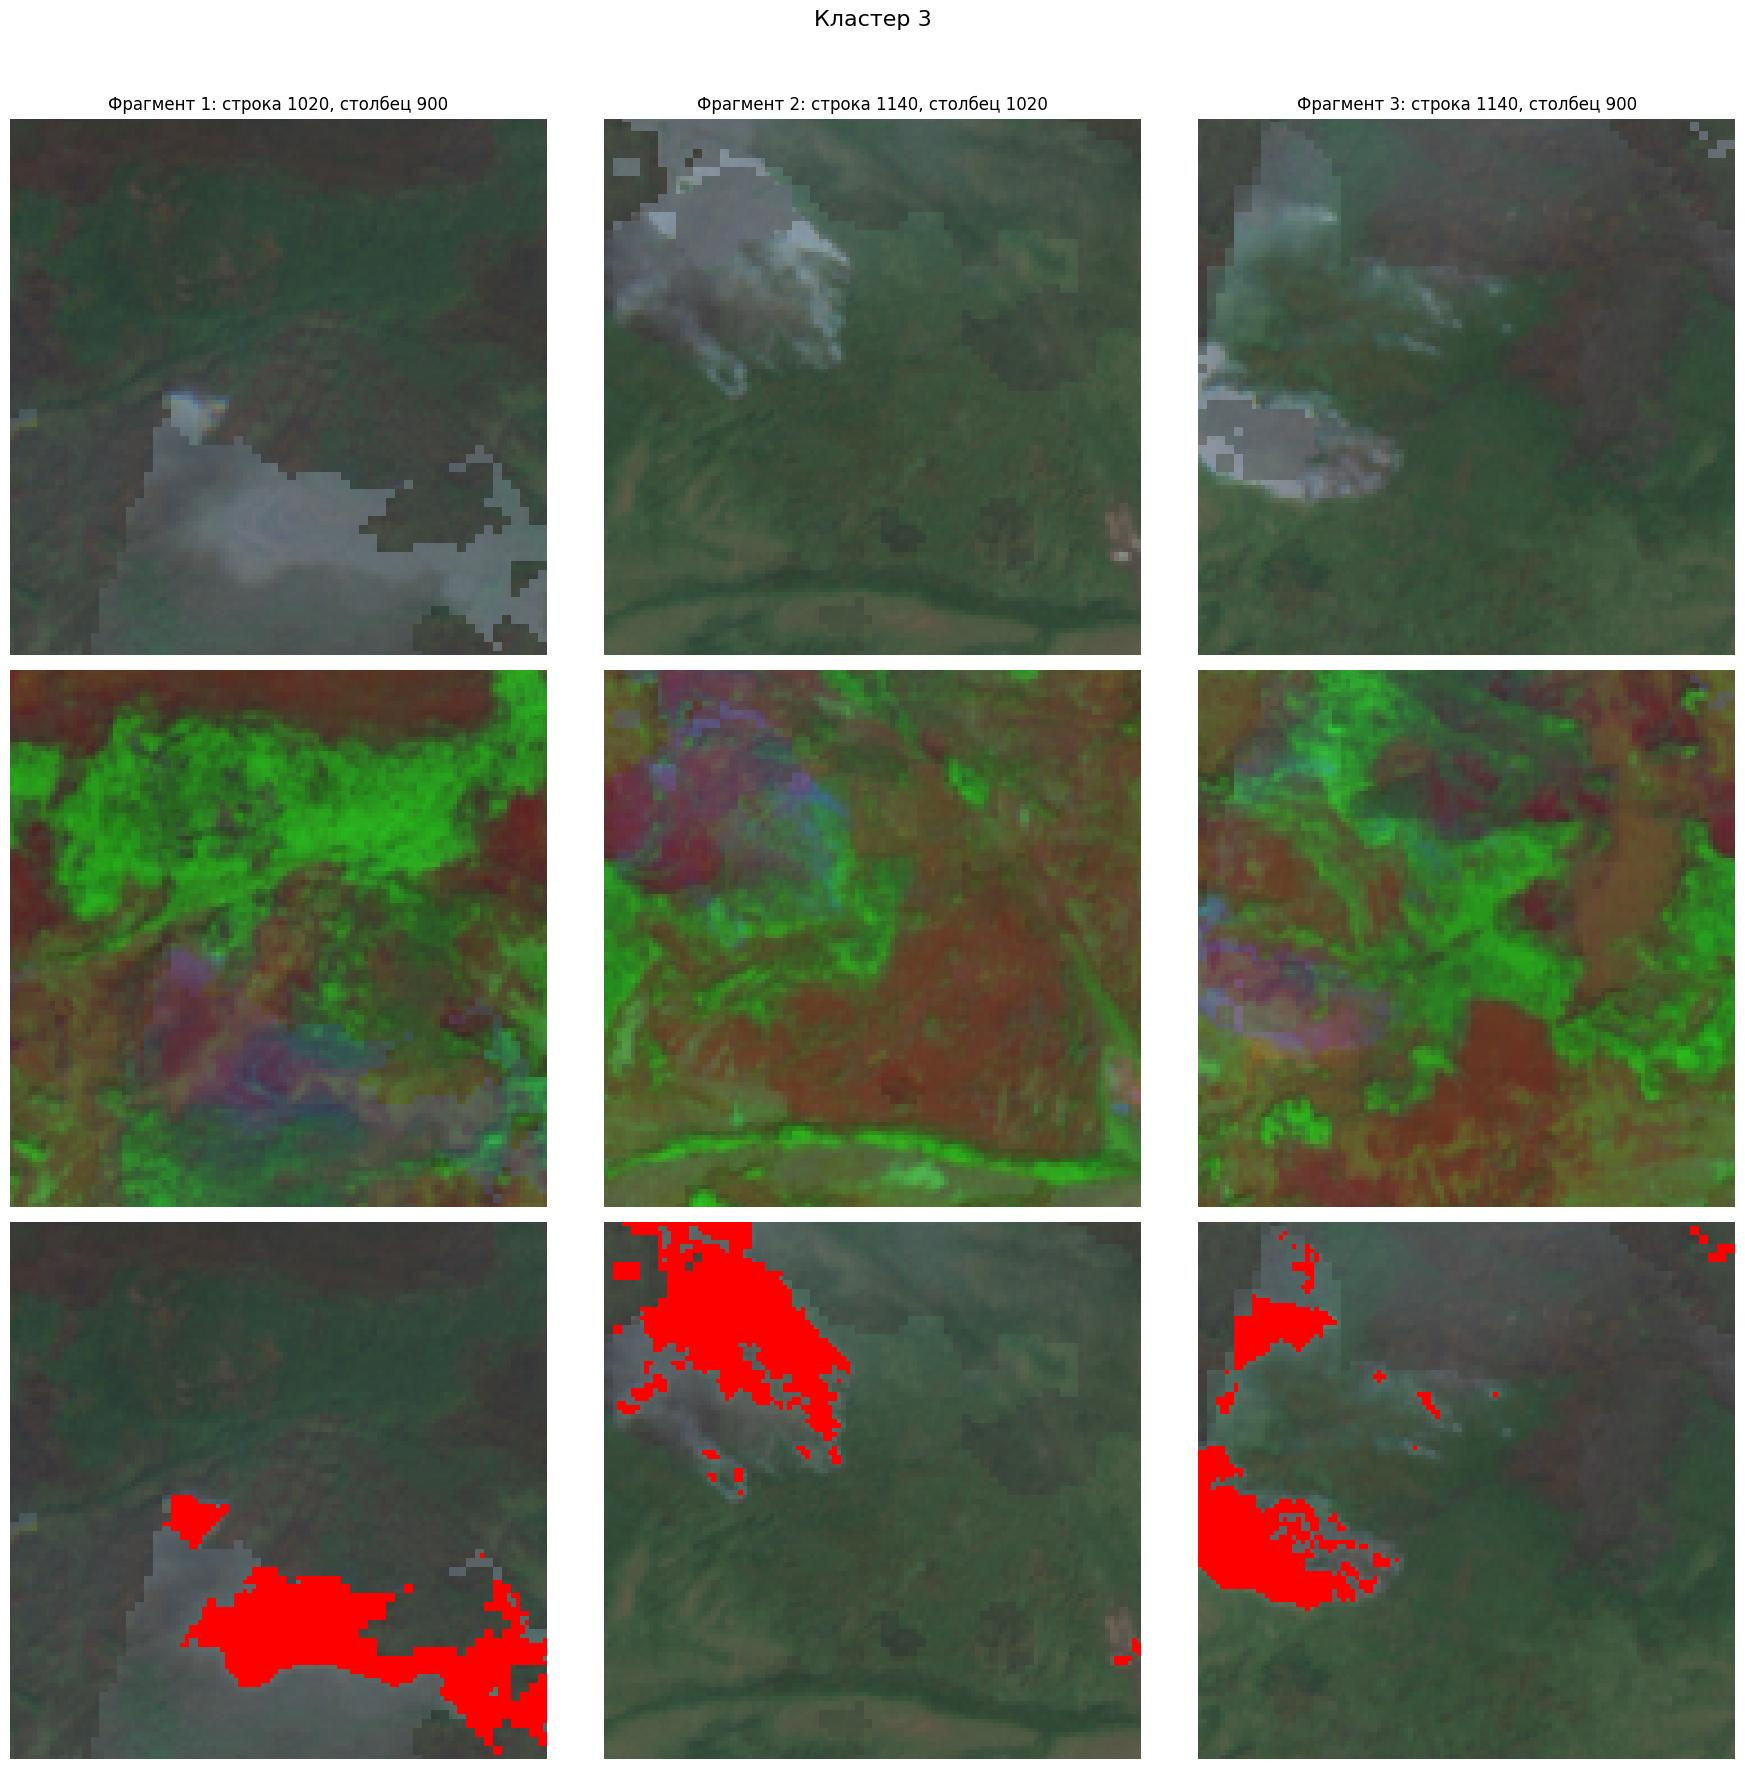

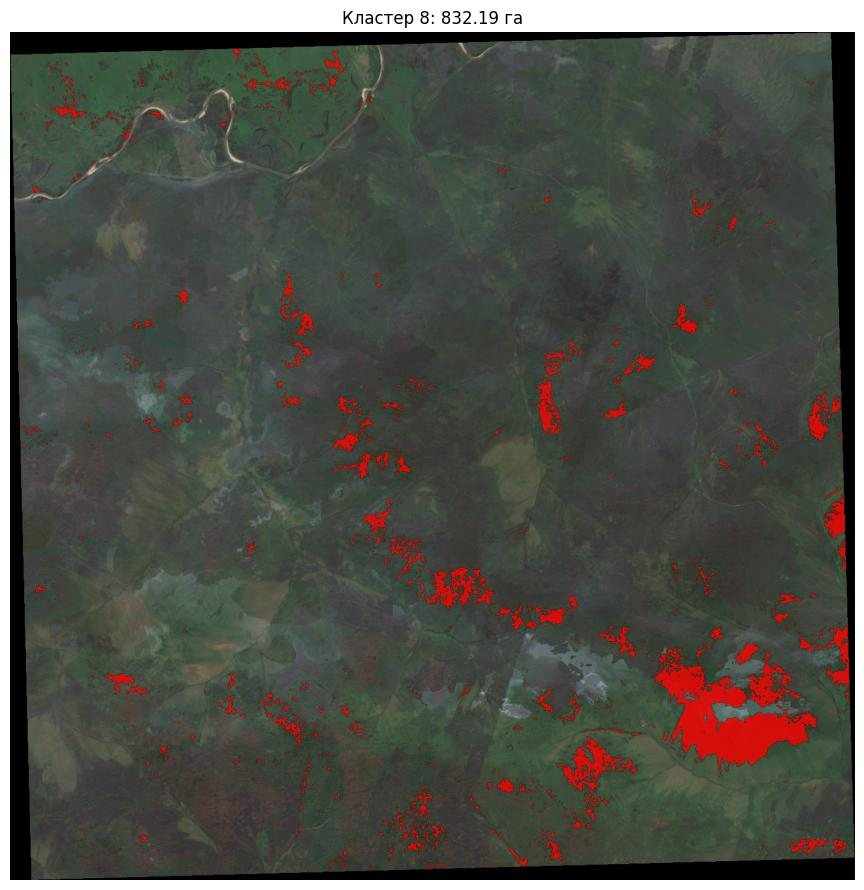

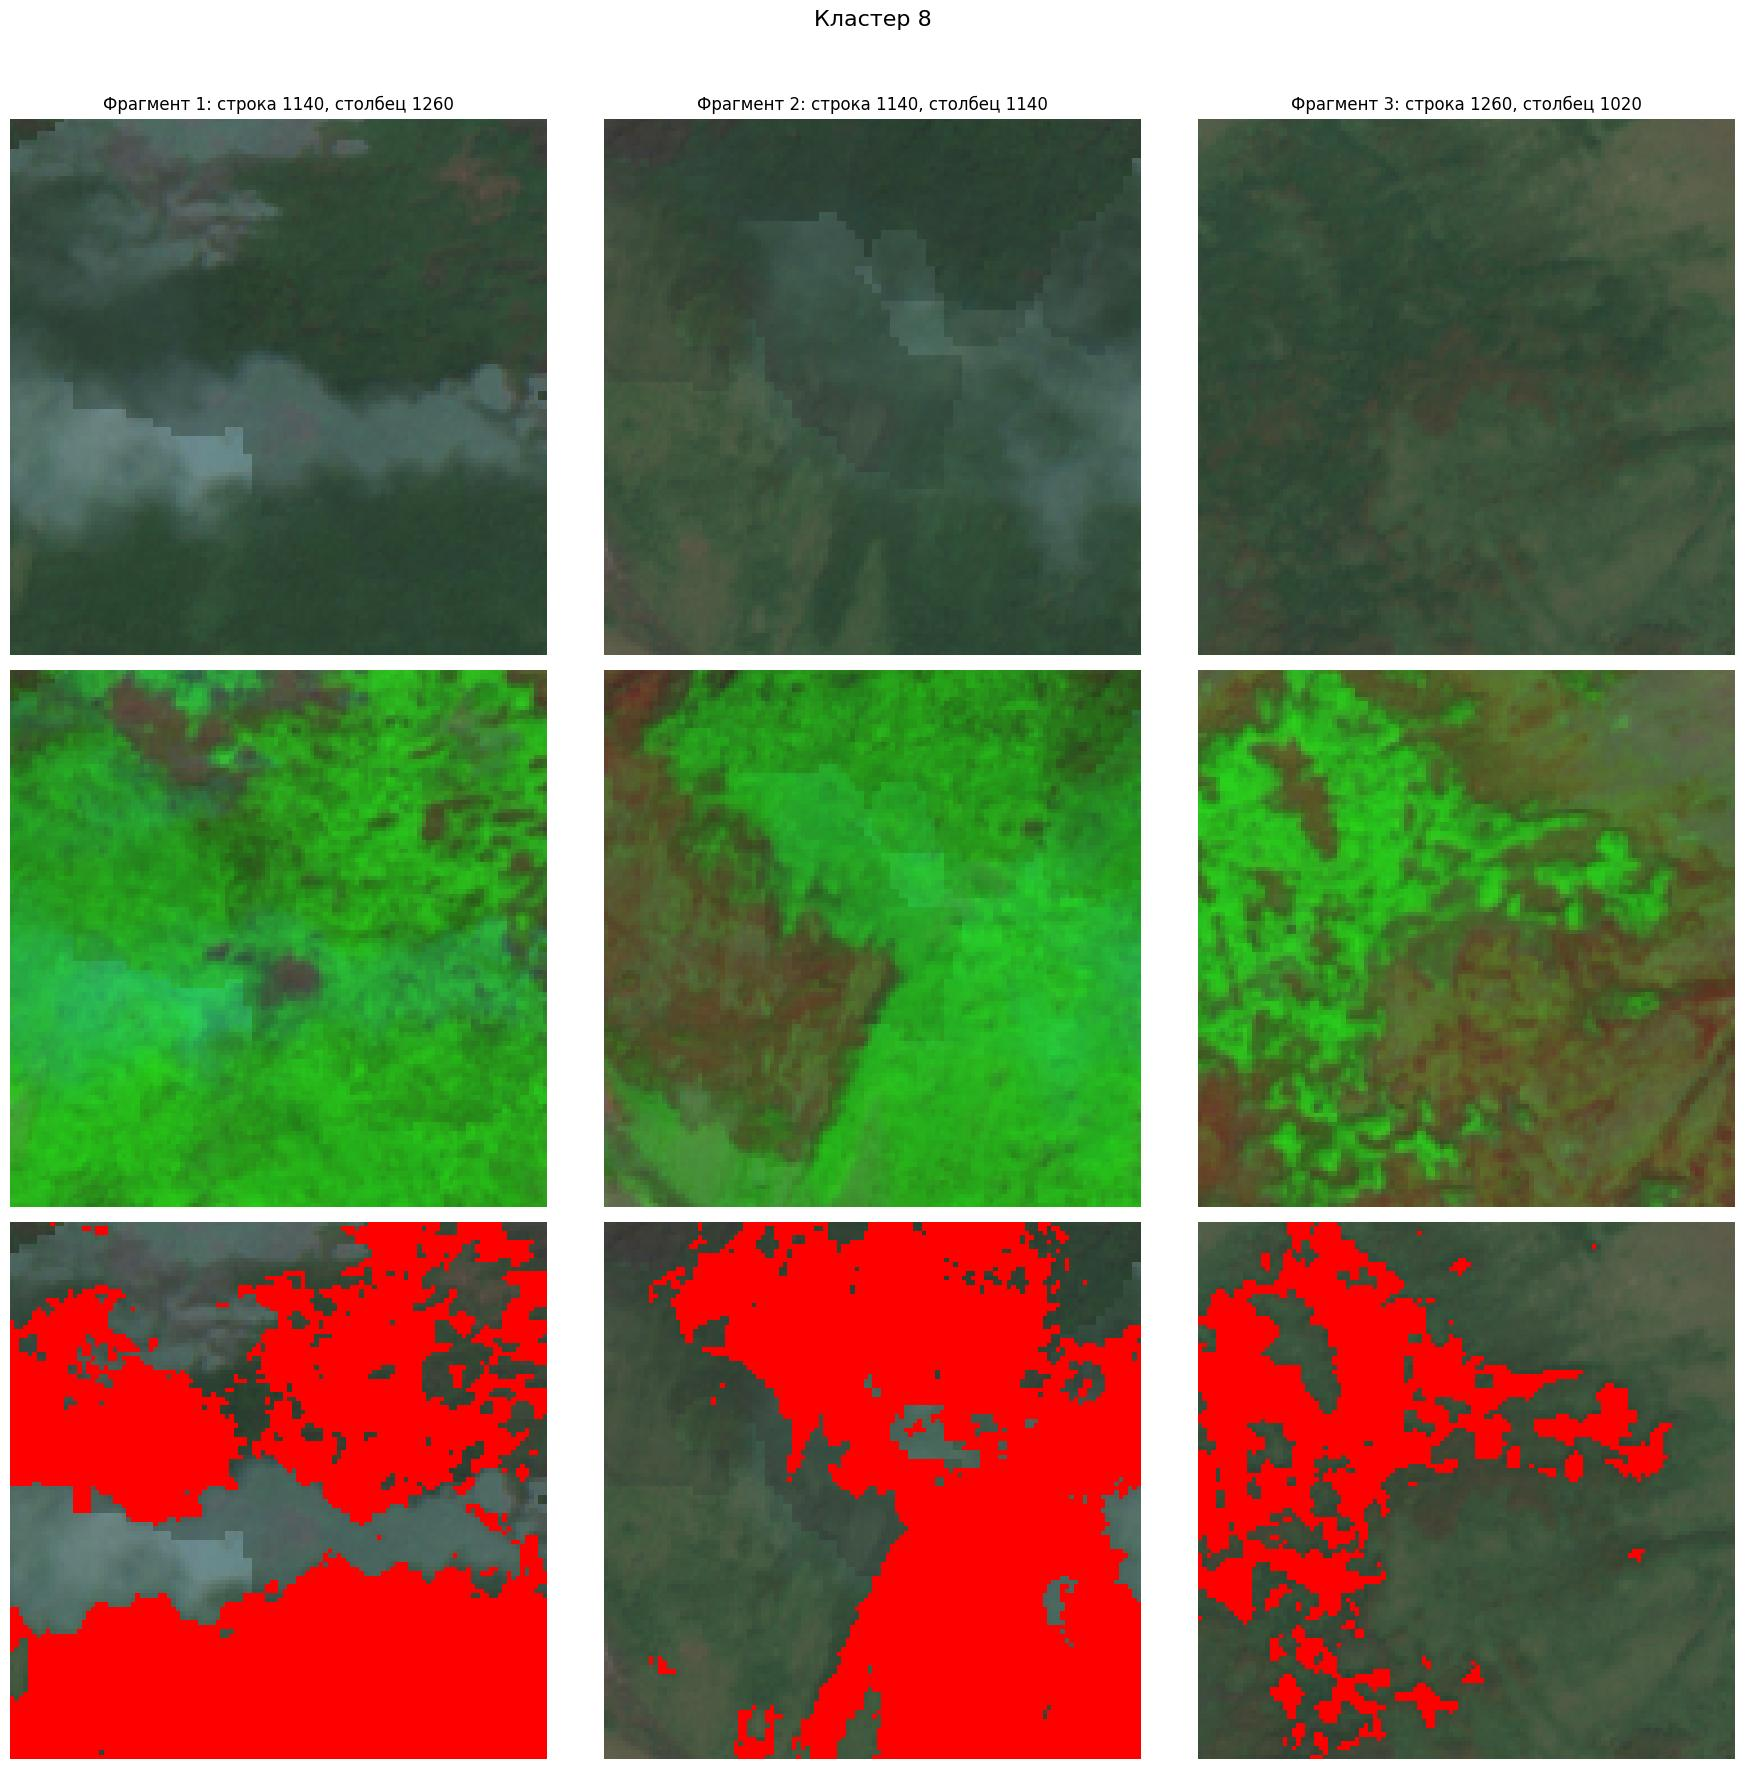

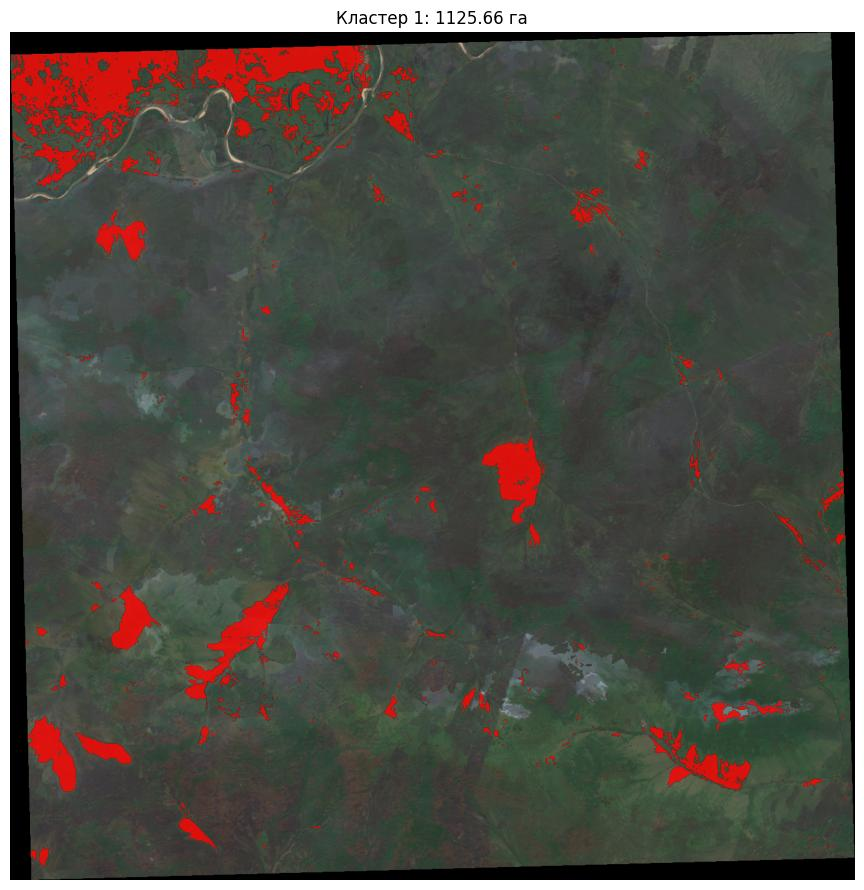

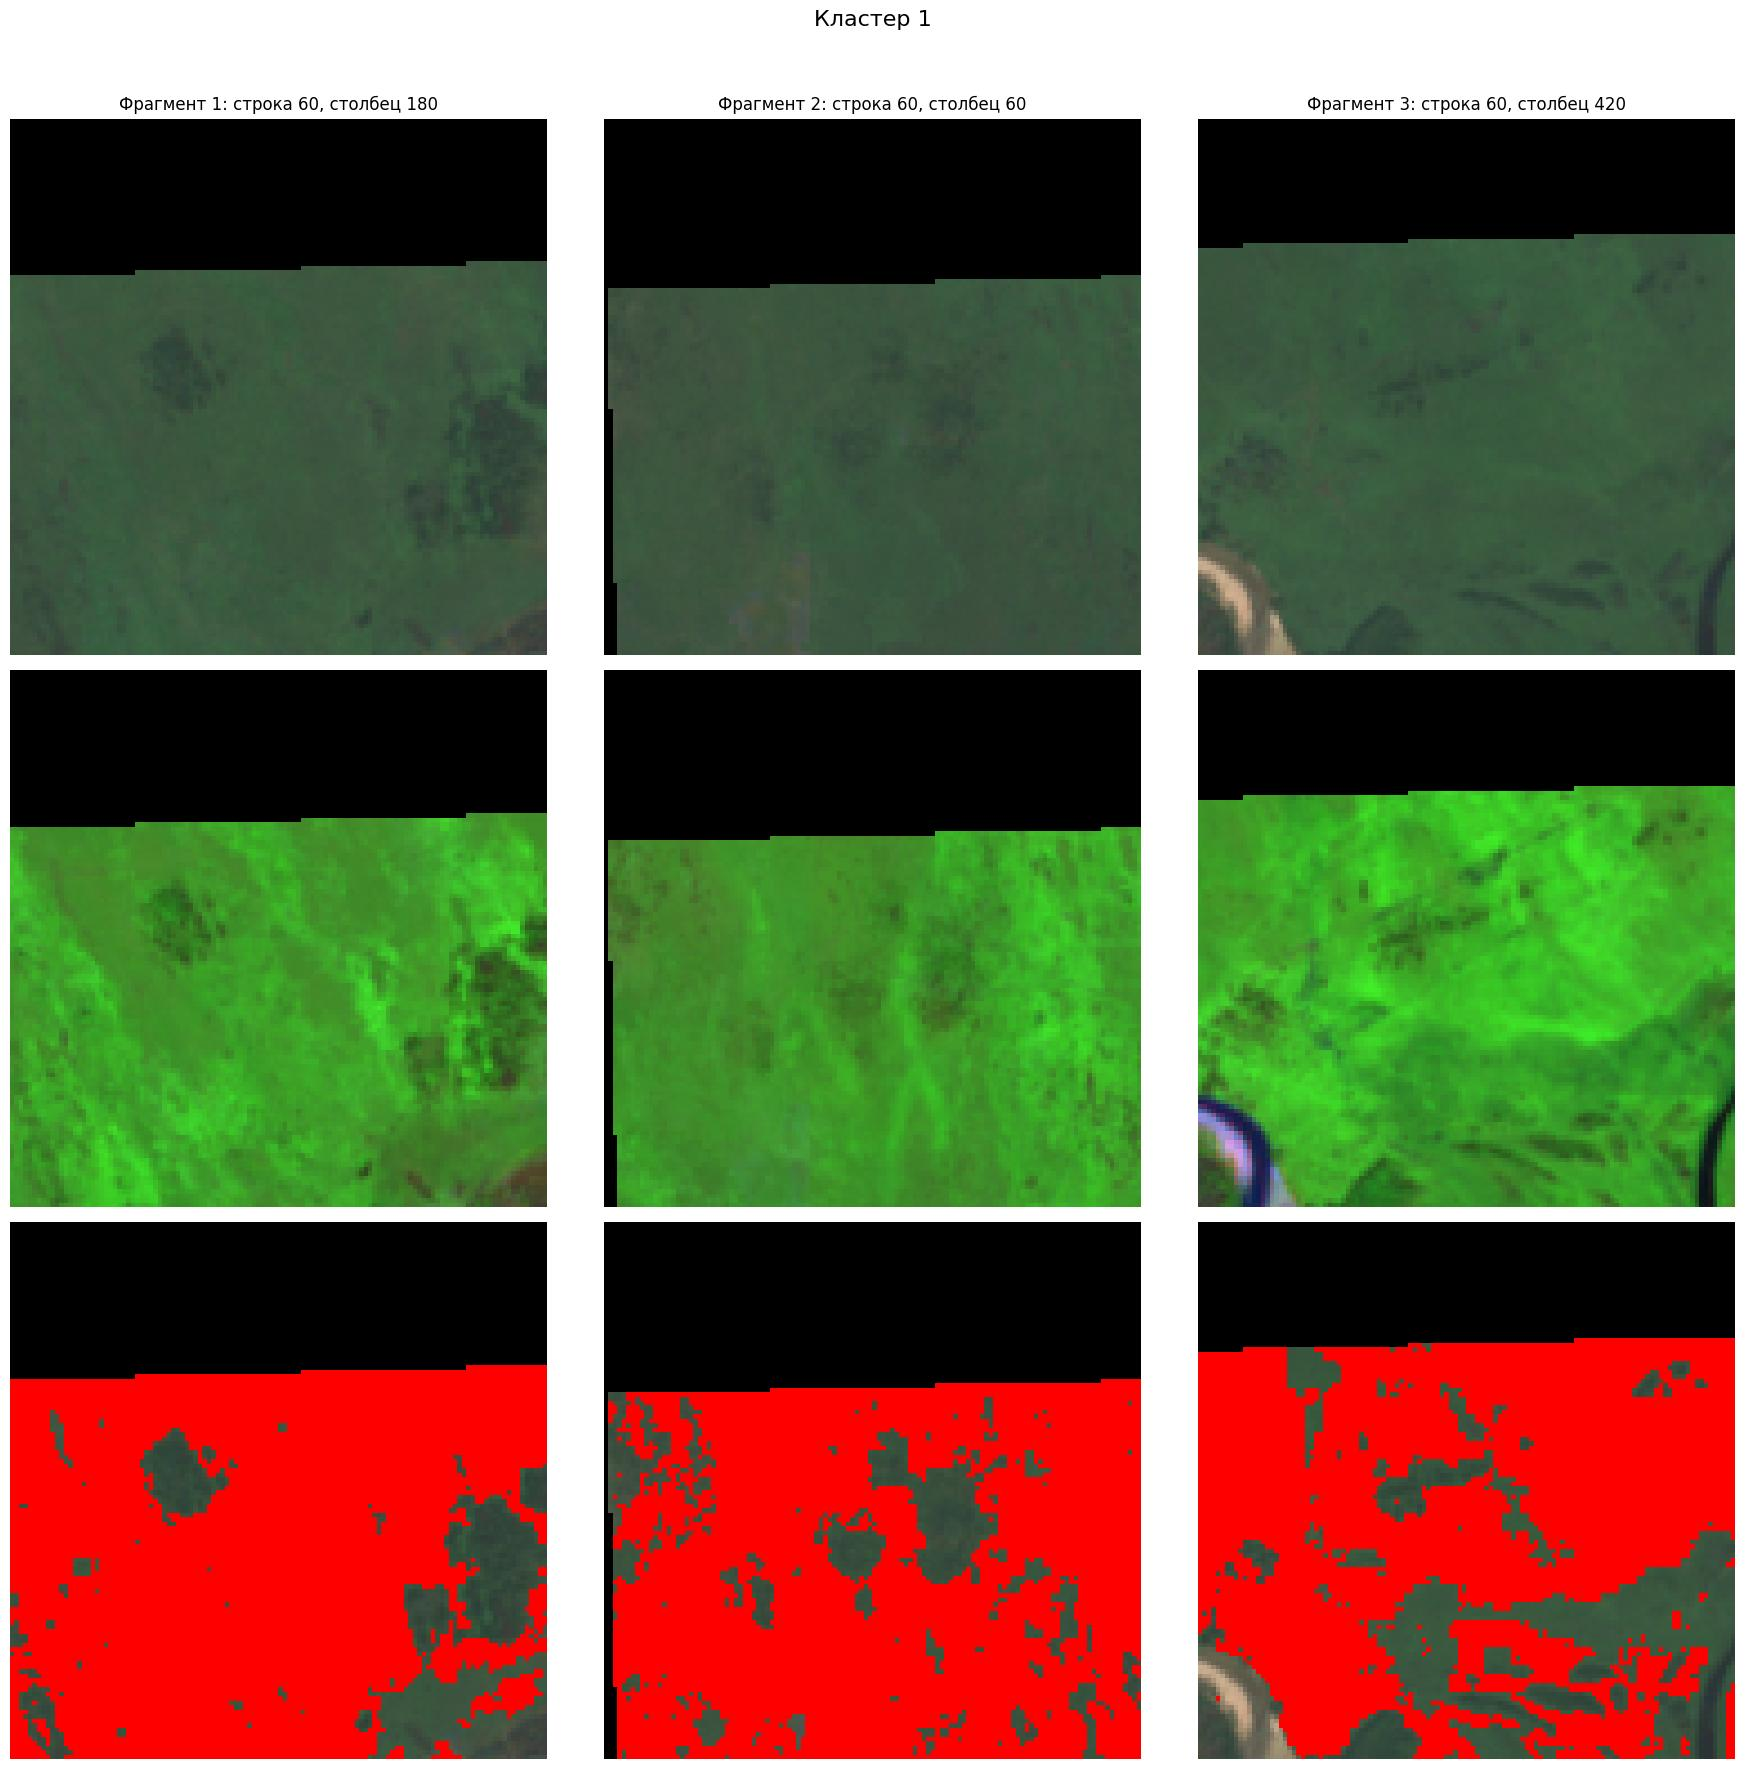

In [22]:
unusual_clusters = profiles.sort_values('Необычность', ascending=False).head(3).copy()
for k in unusual_clusters.index:
    main = cluster_dw.loc[k].sort_values(ascending=False).head(2)
    unusual_clusters.loc[k, 'Главные классы DW'] = '; '.join(
        f'{DW_NAMES[c]}: {v:.1f}%' for c, v in main.items())
display(unusual_clusters[['Площадь, га', 'Доля площади, %', 'Необычность', 'Главные классы DW']].round(3))
for k in unusual_clusters.index:
    mask = (labels == k) & valid
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(rgb)
    ax.imshow(np.ma.masked_where(~mask, mask), cmap=ListedColormap(['red']), alpha=0.8)
    ax.set_title(f'Кластер {k}: {profiles.loc[k, "Площадь, га"]:.2f} га')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
    zoom_views(mask, title=f'Кластер {k}')


Площадь выбранных кластеров: 2385.61 га


,"Dynamic World, %","Своя карта, %"
Вода,0.24,0.98
Деревья,3.03,0.02
Трава,1.50,0.27
Затопл. растительность,0.01,0.00
Культуры,0.71,3.80
Кустарники,89.04,41.47
Застройка,0.00,0.00
Голая земля,1.33,43.11
Снег и лед,4.13,10.36


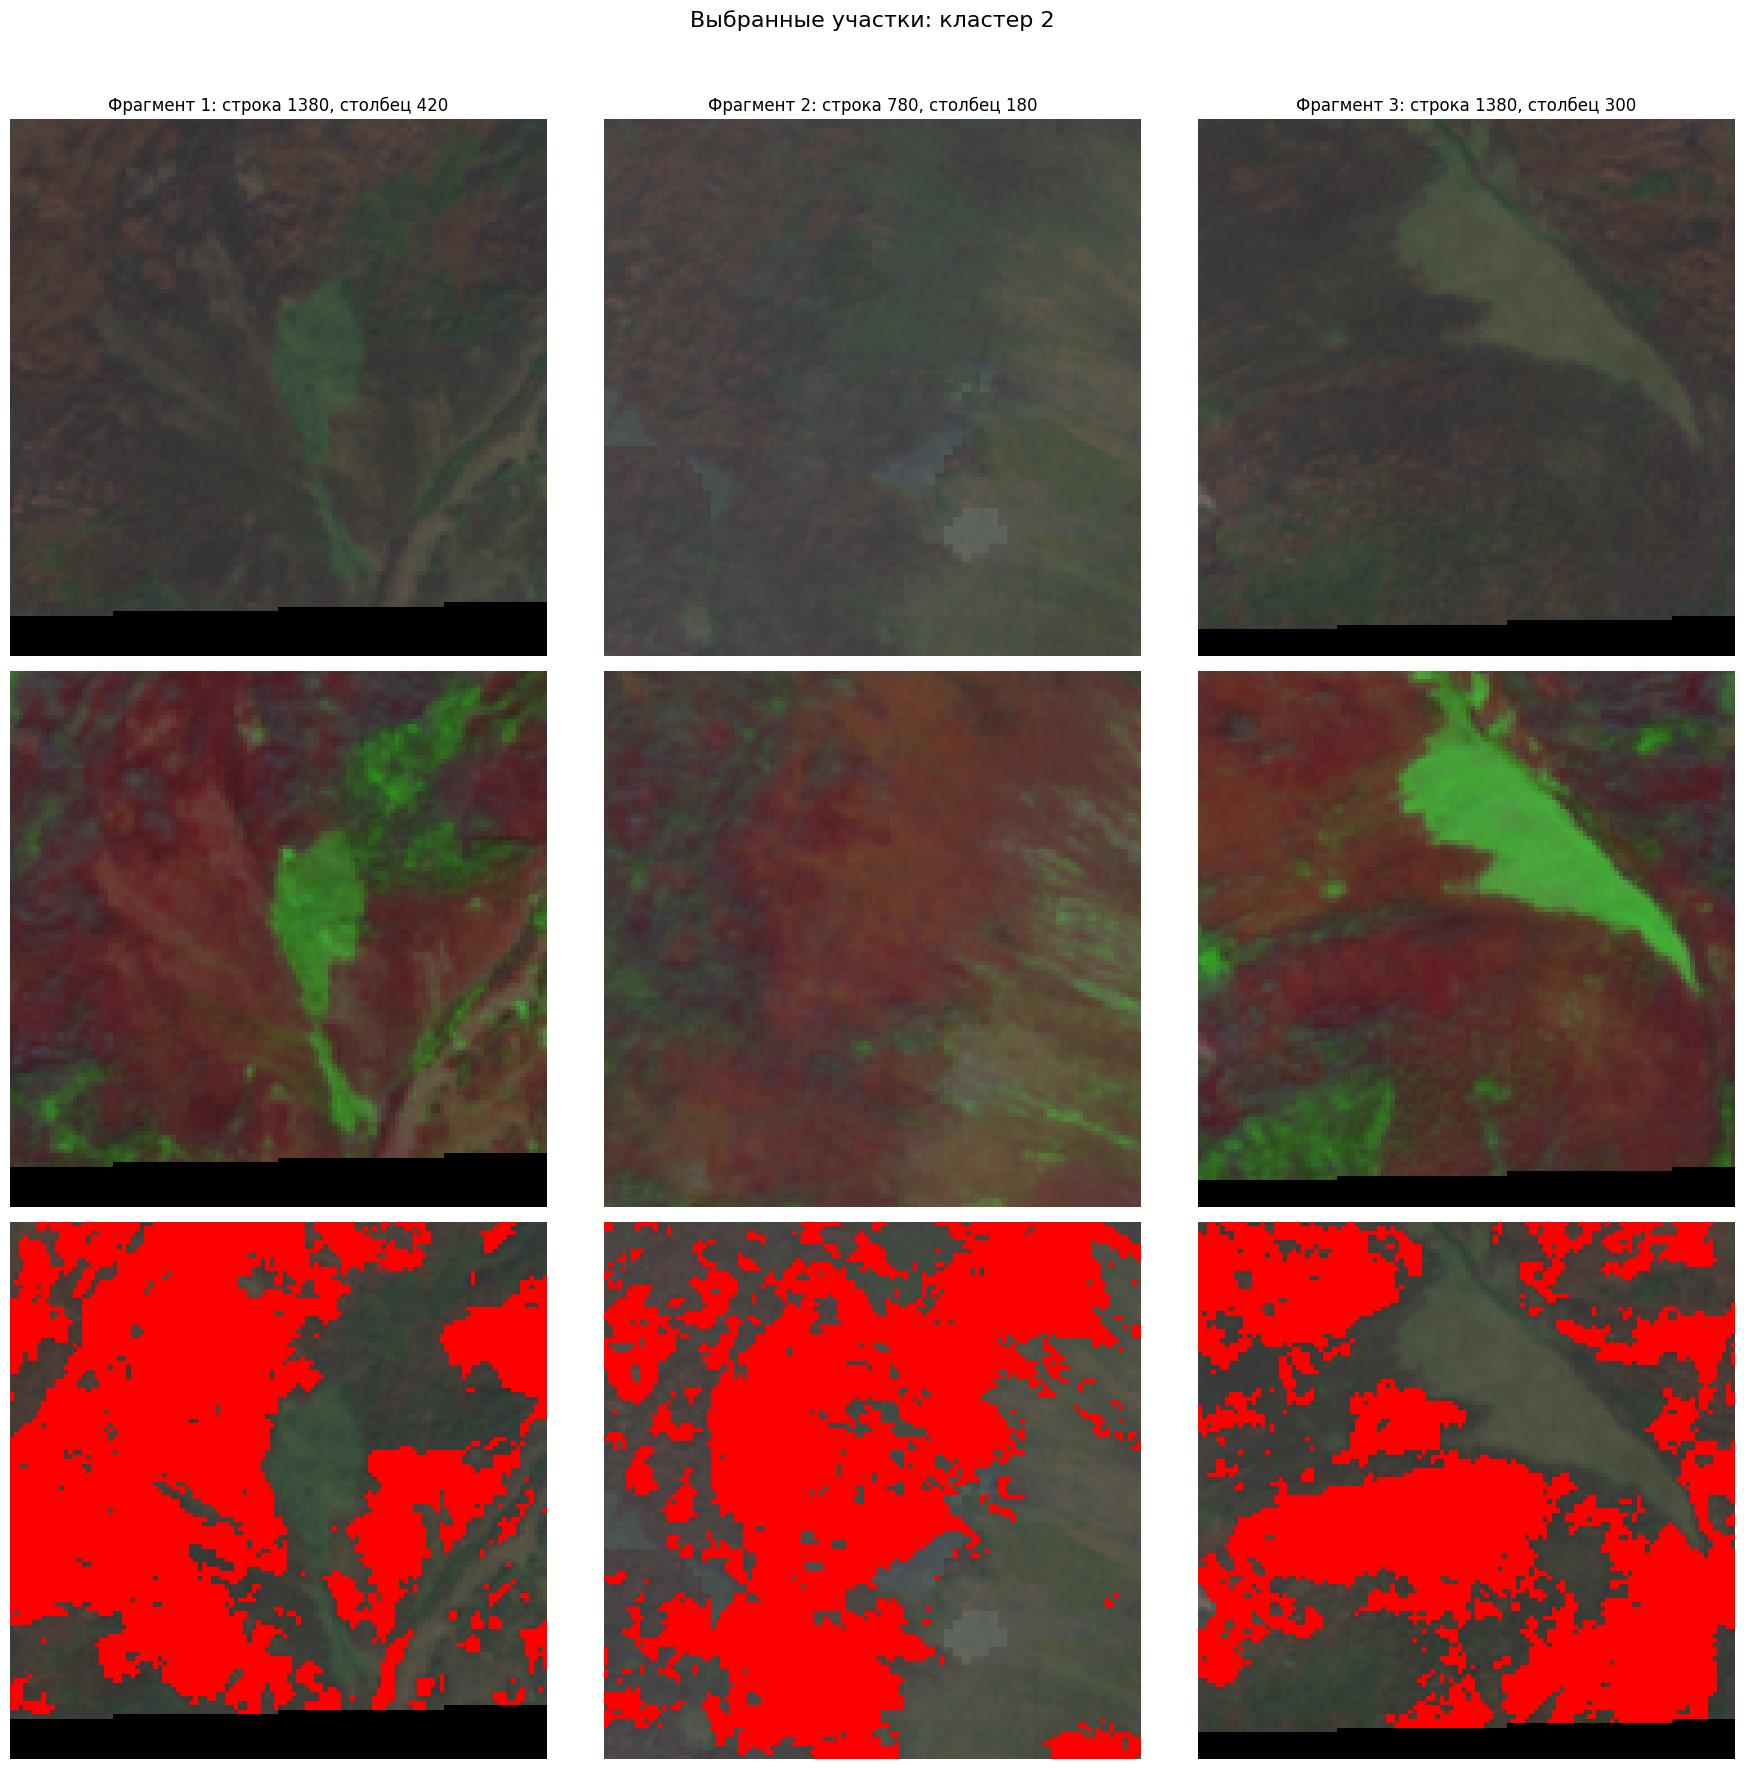

In [23]:
NEEDLES = [2]   # участки, похожие на гари
needle_mask = np.isin(labels, NEEDLES) & valid
needle_area = needle_mask.sum() * PIXEL_AREA_HA
needle_composition = pd.DataFrame({
    'Dynamic World, %': np.bincount(dw[needle_mask], minlength=9) / needle_mask.sum() * 100,
    'Своя карта, %': np.bincount(classification[needle_mask], minlength=9) / needle_mask.sum() * 100
}, index=DW_NAMES)
print('Площадь выбранных кластеров:', round(needle_area, 2), 'га')
display(needle_composition.round(2))

zoom_views(needle_mask, title="Выбранные участки: кластер 2")


**Вопрос:** Что представляют собой выбранные кластеры? Опишите, как они выглядят на снимке в естественных цветах и в комбинации B12–B8–B4, их спектральный профиль, площадь и расположение. К каким классам их отнесли Dynamic World и ваша модель, и почему ни одна из карт не выделяет их отдельно?

**Ответ:** Выбрал кластер 2 как участки, похожие на наиболее выраженные гари. Его площадь — 2385,61 га, или 12,19% площади с данными. На фрагментах это тёмно-бурые склоны, особенно на юге и в западной части; в B12–B8–B4 они красно-коричневые рядом с зелёными участками. Средний B8 равен 0,0866, B12 — 0,1357, NDVI — 0,3354: зелёной растительности здесь заметно меньше, чем в кластере 8 с NDVI 0,7928. Dynamic World относит 89,04% пикселей к кустарникам. Своя модель — 43,11% к голой земле и 41,47% к кустарникам. Ни у одной карты нет класса «гарь». Это площадь выбранной группы пикселей, а не доказанная площадь всех пожаров: похожий спектр бывает и у других открытых поверхностей.


### **5.6. Как число кластеров меняет найденное**

**Задание 5.6.** Для каждого $K$ из `K_LIST` выведите три самых необычных кластера: необычность, площадь, доля площади, доля пикселей кластера, входящих в ваши «иголки» при $K = 12$ (`needle_mask`), и доля всех «иголок», попавших в этот кластер. Так видно, при каком $K$ интересующие вас объекты выделяются в отдельные кластеры и как они дробятся при большом $K$.

In [24]:
rows = []
for number, k in enumerate(K_LIST):
    current = cluster_maps[number]
    lab = current[valid]
    size = np.bincount(lab, minlength=k)
    centers = np.array([z[lab == j].mean(axis=0) for j in range(k)])
    unusualness = np.linalg.norm(centers, axis=1)
    for j in np.argsort(unusualness)[::-1][:3]:
        mask = (current == j) & valid
        common = np.count_nonzero(mask & needle_mask)
        rows.append({'K': k, 'Кластер': j, 'Необычность': unusualness[j],
                     'Площадь, га': size[j] * PIXEL_AREA_HA,
                     'Доля площади, %': size[j] / valid.sum() * 100,
                     'Иголки внутри кластера, %': common / size[j] * 100,
                     'Все иголки в кластере, %': common / needle_mask.sum() * 100})
cluster_comparison = pd.DataFrame(rows)
display(cluster_comparison.round(3))

tracking_rows = []
for number, k in enumerate(K_LIST):
    current = cluster_maps[number]
    for j in range(k):
        mask = (current == j) & valid
        common = np.count_nonzero(mask & needle_mask)
        tracking_rows.append({'K': k, 'Кластер': j,
            'Площадь, га': mask.sum() * PIXEL_AREA_HA,
            'Иголки внутри кластера, %': common / mask.sum() * 100,
            'Все иголки в кластере, %': common / needle_mask.sum() * 100})
needle_tracking = pd.DataFrame(tracking_rows)
best_matches = needle_tracking.loc[needle_tracking.groupby('K')['Все иголки в кластере, %'].idxmax()]
display(best_matches.round(3))


,K,Кластер,Необычность,"Площадь, га","Доля площади, %","Иголки внутри кластера, %","Все иголки в кластере, %"
0,6,3,3.566,1462.10,7.471,0.001,0.001
1,6,1,3.525,1611.16,8.233,0.000,0.000
2,6,5,3.320,2465.65,12.599,0.000,0.000
3,12,3,9.108,116.44,0.595,0.000,0.000
4,12,8,4.457,832.19,4.252,0.000,0.000
5,12,1,3.815,1125.66,5.752,0.000,0.000
6,18,3,10.160,84.89,0.434,0.000,0.000
7,18,4,9.513,45.49,0.232,6.265,0.119
8,18,8,4.707,570.09,2.913,0.000,0.000


,K,Кластер,"Площадь, га","Иголки внутри кластера, %","Все иголки в кластере, %"
2,6,2,3941.10,60.531,99.999
8,12,2,2385.61,100.000,100.000
20,18,2,1294.76,93.064,50.509


**Вопрос:** При каком наименьшем $K$ ваши объекты выделяются в собственный кластер? Что происходит с ними при $K = 6$ и при $K = 18$? Какое $K$ вы бы выбрали для поиска объектов этого типа на соседних территориях?

**Ответ:** В отдельную достаточно чистую группу выбранные участки выделяются при K = 12. При K = 6 почти все они входят в кластер 2 площадью 3941,10 га, но составляют только 60,53% его пикселей: туда добавились и другие поверхности. При K = 18 они дробятся. Кластер 2 площадью 1294,76 га содержит 50,51% выбранных участков, а его чистота относительно них равна 93,06%. Для первого поиска я бы выбрал K = 12, а K = 18 использовал для рассмотрения отдельных типов повреждённых участков. Три самых необычных кластера не обязательно содержат гари: вверху рейтинга оказались облачные остатки и яркая растительность.


### **5.7. Необычные пиксели вне кластеров**

Отдельные необычные объекты не образуют своего кластера, но их пиксели находятся далеко от всех центроидов (см. лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 5.3**). Центроиды `centroids` уже рассчитаны в разделе 5.3.

**Задание 5.7.** Рассчитайте расстояние от каждого пикселя до ближайшего центроида и карту `distance_map`. Найдите 0,1% самых далёких пикселей среди пикселей, не входящих в `NEEDLES`, покажите их на снимке и крупным планом. Определите, что это за объекты.

Порог: 8.975
Необычных пикселей: 1719
Площадь: 17.19 га


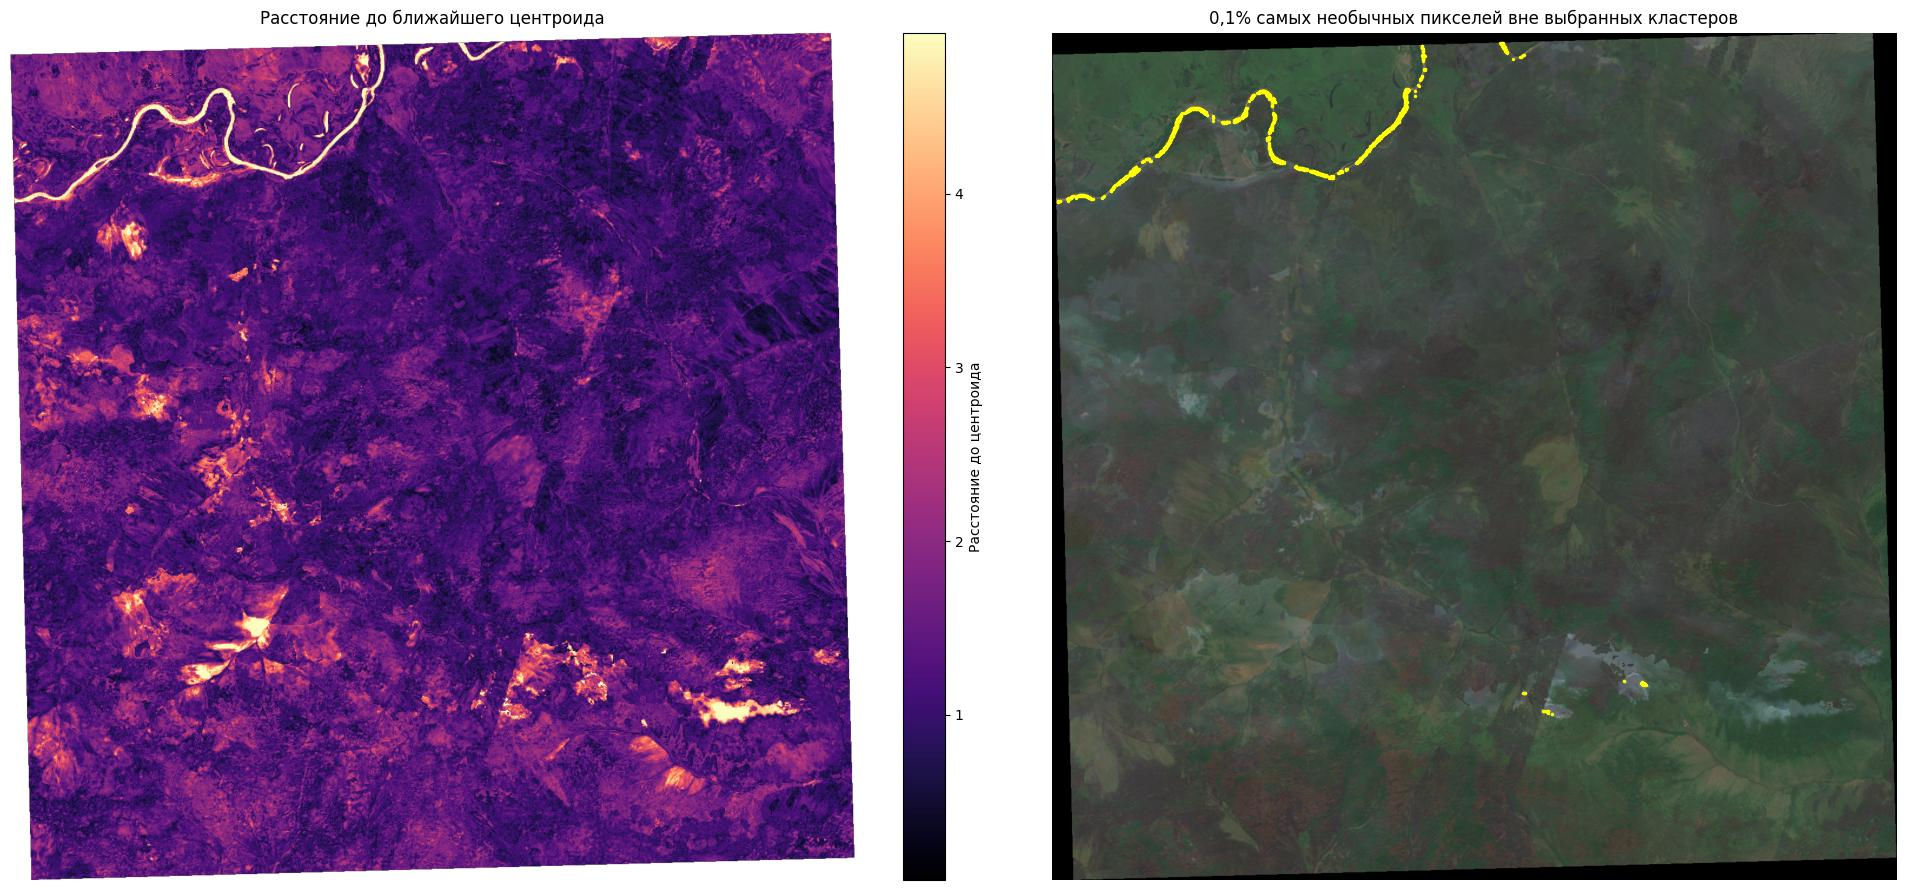

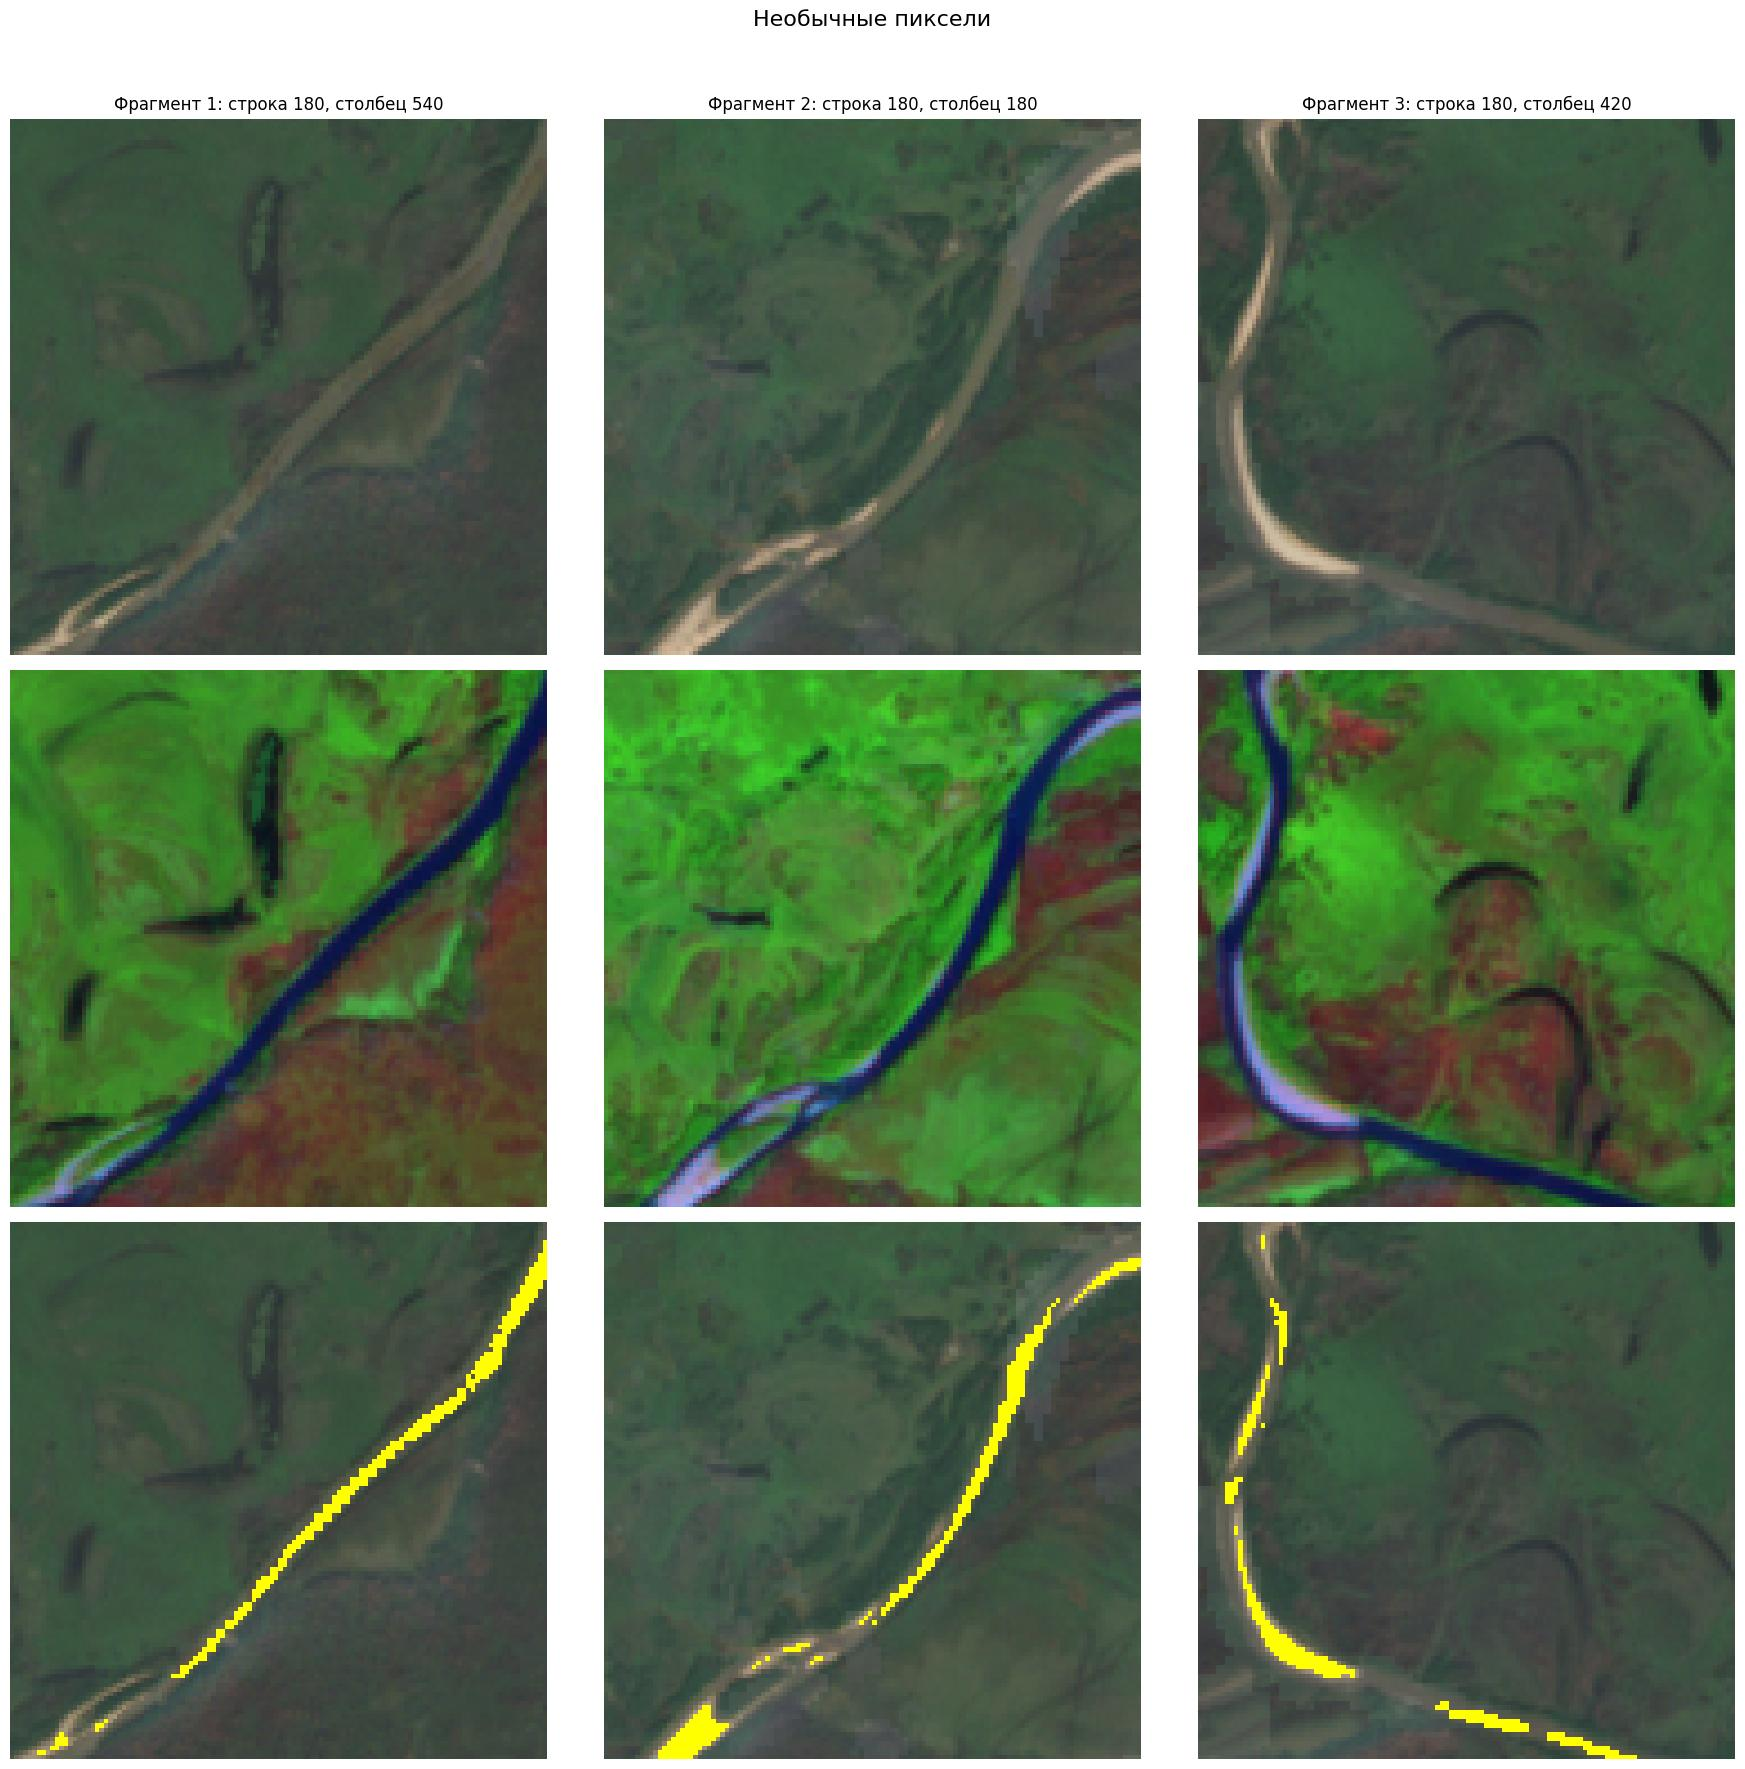

In [25]:
# Совет: квадраты расстояний всех пикселей до всех центроидов без больших промежуточных массивов:
# (z ** 2).sum(axis=1)[:, None] - 2 * z @ centroids.T + (centroids ** 2).sum(axis=1)[None]
distance = np.empty(len(z), dtype='float32')
for start in range(0, len(z), 100000):
    part = z[start:start+100000]
    d2 = ((part ** 2).sum(axis=1)[:, None] - 2 * part @ centroids.T
          + (centroids ** 2).sum(axis=1)[None])
    distance[start:start+len(part)] = np.sqrt(np.maximum(d2.min(axis=1), 0))
distance_map = np.full((H, W), np.nan, dtype='float32')
distance_map[valid] = distance
candidates = valid & ~needle_mask
threshold = np.percentile(distance_map[candidates], 99.9)
unusual_pixels = candidates & (distance_map > threshold)
print('Порог:', round(float(threshold), 3))
print('Необычных пикселей:', unusual_pixels.sum())
print('Площадь:', round(unusual_pixels.sum() * PIXEL_AREA_HA, 2), 'га')
fig, axes = plt.subplots(1, 2, figsize=(20, 9))
im = axes[0].imshow(distance_map, cmap='magma', vmax=np.nanpercentile(distance_map, 99.5))
plt.colorbar(im, ax=axes[0], fraction=0.046, label='Расстояние до центроида')
axes[0].set_title('Расстояние до ближайшего центроида')
axes[1].imshow(rgb)
r, c = np.nonzero(unusual_pixels)
axes[1].scatter(c, r, s=2, color='yellow')
axes[1].set_title('0,1% самых необычных пикселей вне выбранных кластеров')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()
zoom_views(unusual_pixels, color=(1, 1, 0), title='Необычные пиксели')


**Вопрос:** Что оказалось среди самых необычных пикселей? Это отдельные объекты, границы между разными поверхностями или артефакты композита (остатки облаков, теней)? Есть ли среди них объекты, которые вы пропустили бы при просмотре снимка?

**Ответ:** Порог расстояния получился 8,975. За ним осталось 1719 пикселей вне выбранного кластера, то есть 17,19 га. На трёх фрагментах они идут вдоль северной реки, особенно по светлым береговым полосам и границе воды с сушей. Это не отдельный большой объект: здесь смешиваются вода, песчаные берега и растительность. На обычном снимке такие полосы легко пропустить. Расстояние помогает их заметить, но само по себе не доказывает наличие пожара или другого нового объекта.


### **5.8. Проверка гипотез и выводы по разделу 5**

**Задание 5.8.** Вернитесь к таблице 2. Для каждой гипотезы укажите, подтвердилась ли она, каким кластером или каким способом найден объект, его площадь и класс Dynamic World.

**Ответ:**

| Гипотеза | Результат проверки | Кластер и площадь | Dynamic World |
|---|---|---|---|
| Тёмные красно-бурые участки могут быть гарями | По виду и профилю предположение поддерживается; дату и полную площадь пожара по одному композиту не установить | Кластер 2, 2385,61 га, NDVI 0,3354 | Кустарники — 89,04% |
| Зелёные участки среди бурых пятен — сохранившаяся растительность | Подтверждается высоким B8 и NDVI и видом на фрагментах | Кластер 8, 832,19 га, NDVI 0,7928 | Деревья — 99,92% |
| Светлые неровные пятна — остатки облаков или дымки | На увеличенных фрагментах похожи на облачные остатки; это не новая полезная категория земного покрова | Кластер 3, 116,44 га | Деревья — 37,7%, кустарники — 23,5%, снег и лёд — 23,2% |

Площади относятся к целым кластерам, поэтому могут включать похожие по спектру пиксели за пределами отдельного пятна.


Опишите, что нашла кластеризация из того, чего нет в легенде Dynamic World и что не выделил ваш классификатор; какие объекты плохо видны в естественных цветах, но выделяются по инфракрасным каналам; как выбор $K$ влияет на результат.

**Вывод:** Кластеризация выделила группу тёмных повреждённых участков, похожих на гари, хотя в Dynamic World для них нет отдельного класса. Выбранный кластер занимает 2385,61 га. В инфракрасной комбинации он различается с живой растительностью лучше, чем в обычных цветах. При K = 6 он смешивается с другими поверхностями, при K = 12 отделяется, при K = 18 дробится. Самый необычный кластер 3 площадью 116,44 га оказался похож на остатки облаков. Поэтому результат нужно смотреть на снимке: необычность не равна полезности и не заменяет проверку названий объектов.


---

## **6. Сжатие изображений кластеризацией цветов (для бакалавров)**

Кластеризация цветов заменяет все цвета изображения палитрой из $K$ цветов — центроидов кластеров (см. лекция «Кластеризация спутниковых снимков в среде Google Earth Engine», **раздел 6**). Выигрыш в размере получается, только если результат сохранён как **палитра + номера цветов пикселей**. В этом разделе вы проверите, для каких изображений и при каком числе цветов такое сжатие действительно выгодно по сравнению с обычными форматами.

### **6.1. Изображения для экспериментов**

**Задание 6.1.** Загрузите в папку `photos` (панель «Файлы» слева, папка создаётся следующей ячейкой) **две свои фотографии** в формате JPEG:
- фотографию с плавными переходами цвета — небо, портрет, пейзаж, животное на однородном фоне;
- фотографию с множеством мелких деталей и ярких цветов — рынок, цветник, городская улица.

Пропишите имена файлов в словаре `PHOTOS`. Кроме фотографий в эксперименты войдут два изображения вашей территории: фрагмент карты кластеров $K = 12$ из раздела 5 (тематическая карта с небольшим числом цветов) и тот же фрагмент снимка в естественных цветах. Все изображения уменьшаются так, чтобы большая сторона была не больше 1024 пикселей, — это ускоряет расчёты и делает изображения сопоставимыми.

In [2]:
os.makedirs('photos', exist_ok=True)

In [3]:
# Небо и Falcon 9 — SpaceX, https://www.flickr.com/photos/spacexphotos/16511594820/
# Цветник в Кёкенхофе — Yazle (CC0), https://commons.wikimedia.org/wiki/File:Tulipanes_en_Keukenhof,_Holanda.jpg
PHOTOS = {
    'Фото с плавными переходами': 'photos/smooth.jpg',
    'Фото с мелкими деталями': 'photos/tulips.jpg',
}
from urllib.request import urlretrieve
from urllib.parse import quote
for path in PHOTOS.values():
    if not os.path.isfile(path):
        url = 'https://raw.githubusercontent.com/German121/image_processing/main/' + quote('Задание 6/' + path, safe='/')
        urlretrieve(url, path)


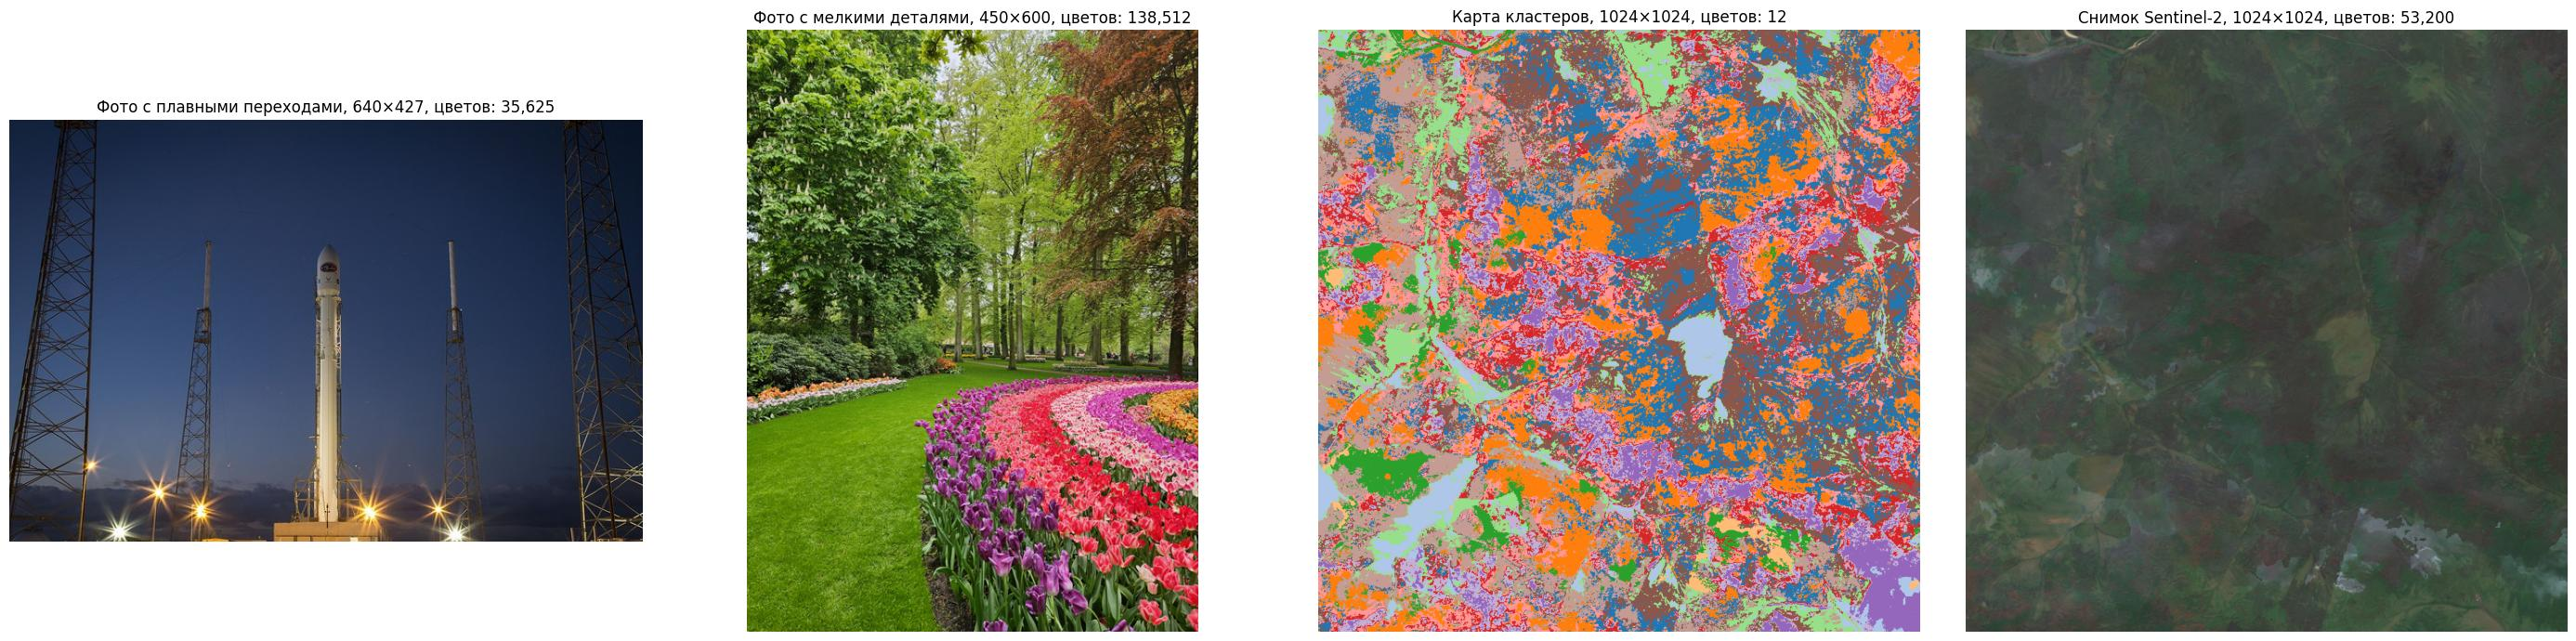

In [4]:
#@title Готовая функция: подготовка изображений
MAX_SIDE = 1024

def load_photo(path, max_side=MAX_SIDE):
    """RGB-массив фотографии, уменьшенной до max_side пикселей по большей стороне."""
    img = Image.open(path).convert('RGB')
    img.thumbnail((max_side, max_side))
    return np.array(img)

images = {name: load_photo(path) for name, path in PHOTOS.items()}

# Фрагмент территории: центральный квадрат растра не больше MAX_SIDE пикселей
side = min(H, W, MAX_SIDE)
r0, c0 = (H - side) // 2, (W - side) // 2
window = np.s_[r0:r0 + side, c0:c0 + side]
cluster_rgb = np.round(cluster_colors[:, :3] * 255).astype('uint8')   # цвета кластеров в RGB
images['Карта кластеров'] = cluster_rgb[np.clip(labels[window], 0, K - 1)]
images['Снимок Sentinel-2'] = (rgb[window] * 255).astype('uint8')

fig, axes = plt.subplots(1, len(images), figsize=(7 * len(images), 7))
for ax, (name, img) in zip(axes, images.items()):
    ax.imshow(img)
    ax.set_title(f'{name}, {img.shape[1]}×{img.shape[0]}, цветов: {len(np.unique(img.reshape(-1, 3), axis=0)):,}')
    ax.axis('off')
plt.tight_layout()
plt.show()

### **6.2. Как сохранять результат**

Размер файла — главный показатель эффективности сжатия, поэтому сохраняйте изображения **строго одним из способов из таблицы 4** и измеряйте размер **настоящего файла на диске** функцией `os.path.getsize`. Все файлы раздела сохраняйте в папку `compressed/<название изображения>/`.

#### **Таблица 4. Способы сохранения**

| **Способ** | **Код** | **Что записывается в файл** |
|---|---|---|
| PNG без потерь — эталон размера | `Image.fromarray(img).save(path, format='PNG', optimize=True)` | 3 байта цвета на пиксель, сжатие без потерь |
| JPEG, качество 90 — обычное сжатие фотографий | `Image.fromarray(img).save(path, format='JPEG', quality=90)` | Сжатие с потерями, рассчитанное на фотографии |
| **Палитровый PNG — результат кластеризации** | `p_img = Image.frombytes('P', (w, h), indices.astype('uint8').tobytes())`<br>`p_img.putpalette(palette.flatten().tolist())`<br>`p_img.save(path, format='PNG', optimize=True)` | Палитра из $K$ цветов и номер цвета для каждого пикселя: 1 бит на пиксель при 2 цветах, 4 бита при 16, 8 бит при 256 |

Обратите внимание:
- номера цветов `indices` должны иметь тип `uint8` (от 0 до 255), поэтому $K \le 256$;
- параметр `mode` функции `Image.fromarray` в новых версиях Pillow устарел, поэтому палитровое изображение создаётся через `Image.frombytes`;
- изображение `palette[indices]` (восстановленные цвета) нужно только для просмотра и расчёта качества — если сохранить его как RGB-PNG или JPEG, выигрыша от кластеризации не будет (это вы проверите в разделе 6.4).

**Задание 6.2.** Допишите две функции:
- `quantize_kmeans(image, k, sample_size=50000, seed=42)` — обучает `KMeans(n_clusters=k, n_init=1, random_state=seed)` на случайной подвыборке `sample_size` пикселей (все пиксели, если `sample_size=None` или пикселей меньше), относит все пиксели к ближайшим центроидам и возвращает палитру `palette` (`uint8`, форма $(k, 3)$), индексы `indices` (`uint8`, форма $(h, w)$) и время работы в секундах;
- `save_palette_png(palette, indices, path)` — сохраняет палитровый PNG по таблице 4 и возвращает размер файла в КБ.

In [5]:
import warnings
from sklearn.exceptions import ConvergenceWarning

def quantize_kmeans(image, k, sample_size=50000, seed=42):
    """Квантизация RGB-изображения до k цветов методом K-средних: палитра, индексы и время, с."""
    start = time.perf_counter()
    h_img, w_img, _ = image.shape
    colors = image.reshape(-1, 3).astype('float32')
    if sample_size is None or len(colors) <= sample_size:
        sample = colors
    else:
        rng = np.random.default_rng(seed)
        sample = colors[rng.choice(len(colors), sample_size, replace=False)]
    with warnings.catch_warnings():
        # На карте всего 12 разных цветов.
        warnings.filterwarnings('ignore', message='Number of distinct clusters.*', category=ConvergenceWarning)
        kmeans = KMeans(n_clusters=k, n_init=1, random_state=seed).fit(sample)
    palette = np.round(kmeans.cluster_centers_).clip(0, 255).astype('uint8')
    indices = kmeans.predict(colors).astype('uint8').reshape(h_img, w_img)
    return palette, indices, time.perf_counter() - start

def save_palette_png(palette, indices, path):
    """Палитровый PNG: таблица цветов и номер цвета каждого пикселя. Возвращает размер файла, КБ."""
    h_img, w_img = indices.shape
    p_img = Image.frombytes('P', (w_img, h_img), indices.astype('uint8').tobytes())
    p_img.putpalette(palette.flatten().tolist())
    p_img.save(path, format='PNG', optimize=True)
    return os.path.getsize(path) / 1024


In [6]:
#@title Готовые функции: сохранение без кластеризации и метрики качества
def save_rgb(img, path, **save_args):
    """Сохраняет RGB-массив в файл и возвращает размер, КБ."""
    Image.fromarray(img).save(path, **save_args)
    return os.path.getsize(path) / 1024

def quality(original, restored):
    """PSNR (дБ) и SSIM восстановленного изображения относительно исходного."""
    return (peak_signal_noise_ratio(original, restored, data_range=255),
            structural_similarity(original, restored, channel_axis=2, data_range=255))

for name in images:
    os.makedirs(f'compressed/{name}', exist_ok=True)

### **6.3. Размер, качество и время при разном числе цветов**

**Задание 6.3.** Для каждого изображения из `images`:
1. Сохраните эталоны без кластеризации: `compressed/<имя>/original.png` (PNG без потерь) и `compressed/<имя>/original_q90.jpg` (JPEG, качество 90). Для JPEG рассчитайте PSNR и SSIM относительно исходного изображения.
2. Для каждого `k` из `K_COLORS` выполните `quantize_kmeans`, сохраните палитровый PNG `compressed/<имя>/kmeans_<k>.png`, рассчитайте PSNR и SSIM восстановленного изображения `palette[indices]`.

Соберите две таблицы: `baselines` (столбцы `Изображение`, `PNG без потерь, КБ`, `JPEG 90, КБ`, `JPEG 90 PSNR`, `JPEG 90 SSIM`) и `results` (столбцы `Изображение`, `Цветов`, `Время, с`, `Палитровый PNG, КБ`, `PSNR`, `SSIM`). Сохраните палитры и индексы в словарь `quantized[(имя, k)]` — они понадобятся дальше. Если восстановленное изображение точно совпадает с исходным (так бывает, когда цветов в изображении не больше $K$), PSNR равен бесконечности.

In [7]:
K_COLORS = [2, 4, 8, 16, 32, 64, 128, 256]

In [8]:
baseline_rows, result_rows, quantized = [], [], {}
for name, img in images.items():
    folder = f'compressed/{name}'
    png_size = save_rgb(img, f'{folder}/original.png', format='PNG', optimize=True)
    jpg_size = save_rgb(img, f'{folder}/original_q90.jpg', format='JPEG', quality=90)
    restored_jpg = np.array(Image.open(f'{folder}/original_q90.jpg').convert('RGB'))
    psnr_jpg, ssim_jpg = quality(img, restored_jpg)
    baseline_rows.append({'Изображение': name, 'PNG без потерь, КБ': png_size,
                          'JPEG 90, КБ': jpg_size, 'JPEG 90 PSNR': psnr_jpg,
                          'JPEG 90 SSIM': ssim_jpg})
    for k in K_COLORS:
        palette, indices, seconds = quantize_kmeans(img, k)
        quantized[(name, k)] = (palette, indices)
        size = save_palette_png(palette, indices, f'{folder}/kmeans_{k}.png')
        with np.errstate(divide='ignore'):
            psnr, ssim = quality(img, palette[indices])
        result_rows.append({'Изображение': name, 'Цветов': k, 'Время, с': seconds,
                            'Палитровый PNG, КБ': size, 'PSNR': psnr, 'SSIM': ssim})
baselines = pd.DataFrame(baseline_rows).set_index('Изображение')
results = pd.DataFrame(result_rows)
display(baselines.round(4))
display(results.round(4))


,"PNG без потерь, КБ","JPEG 90, КБ",JPEG 90 PSNR,JPEG 90 SSIM
Изображение,,,,
Фото с плавными переходами,274.4707,49.4355,40.4192,0.9791
Фото с мелкими деталями,646.6914,155.9893,29.1784,0.9327
Карта кластеров,391.0645,666.9062,19.4395,0.7247
Снимок Sentinel-2,1301.0840,155.1875,41.0632,0.9423


,Изображение,Цветов,"Время, с","Палитровый PNG, КБ",PSNR,SSIM
0,Фото с плавными переходами,2,0.0415,6.7002,20.9254,0.7840
1,Фото с плавными переходами,4,0.0275,15.0488,24.8019,0.8393
2,Фото с плавными переходами,8,0.0571,27.6123,28.1309,0.8721
3,Фото с плавными переходами,16,0.0956,36.3066,31.0694,0.9002
4,Фото с плавными переходами,32,0.2094,46.1113,34.1114,0.9318
5,Фото с плавными переходами,64,0.3633,61.2734,36.9602,0.9559
6,Фото с плавными переходами,128,0.6163,79.9883,39.6477,0.9721
7,Фото с плавными переходами,256,1.2214,103.4502,41.9543,0.9825
8,Фото с мелкими деталями,2,0.0207,19.8369,16.9407,0.5081
9,Фото с мелкими деталями,4,0.0234,41.4941,19.9526,0.6599


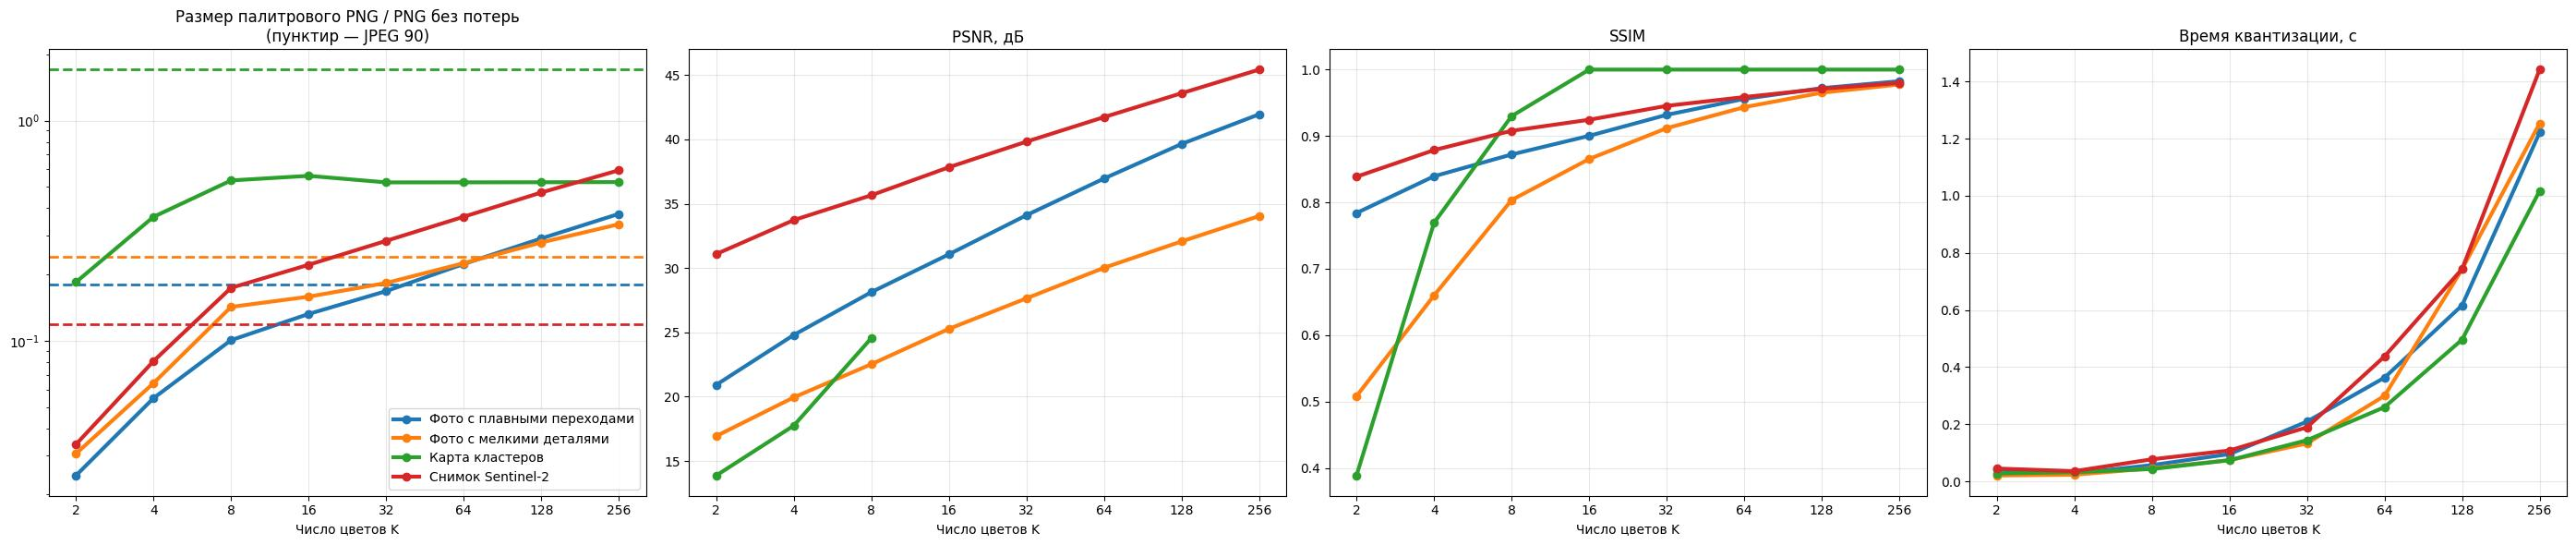

Изображение,Карта кластеров,Снимок Sentinel-2,Фото с мелкими деталями,Фото с плавными переходами
Цветов,,,,
2,0.03,0.05,0.02,0.04
4,0.03,0.04,0.02,0.03
8,0.04,0.08,0.05,0.06
16,0.07,0.11,0.07,0.10
32,0.14,0.19,0.13,0.21
64,0.26,0.44,0.30,0.36
128,0.50,0.74,0.74,0.62
256,1.02,1.44,1.25,1.22


Изображение,Карта кластеров,Снимок Sentinel-2,Фото с мелкими деталями,Фото с плавными переходами
Цветов,,,,
2,72.2,44.0,19.8,6.7
4,142.9,105.1,41.5,15.0
8,209.1,226.2,92.1,27.6
16,219.5,287.9,102.5,36.3
32,204.9,369.9,118.3,46.1
64,205.0,476.0,145.5,61.3
128,205.2,613.2,180.7,80.0
256,205.6,773.9,218.7,103.5


In [9]:
#@title Готовый код: графики размера, качества и времени
fig, axes = plt.subplots(1, 4, figsize=(28, 6))
for name, part in results.groupby('Изображение', sort=False):
    ratio = part['Палитровый PNG, КБ'] / baselines.loc[name, 'PNG без потерь, КБ']
    line, = axes[0].plot(part['Цветов'], ratio, 'o-', linewidth=3, label=name)
    axes[0].axhline(baselines.loc[name, 'JPEG 90, КБ'] / baselines.loc[name, 'PNG без потерь, КБ'],
                    color=line.get_color(), linestyle='--', linewidth=2)
    axes[1].plot(part['Цветов'], part['PSNR'], 'o-', linewidth=3, color=line.get_color())
    axes[2].plot(part['Цветов'], part['SSIM'], 'o-', linewidth=3, color=line.get_color())
    axes[3].plot(part['Цветов'], part['Время, с'], 'o-', linewidth=3, color=line.get_color())
titles = ['Размер палитрового PNG / PNG без потерь\n(пунктир — JPEG 90)', 'PSNR, дБ', 'SSIM', 'Время квантизации, с']
for ax, title in zip(axes, titles):
    ax.set_xscale('log', base=2)
    ax.set_xticks(K_COLORS, K_COLORS)
    ax.set_xlabel('Число цветов K')
    ax.set_title(title)
    ax.grid(alpha=0.3)
axes[0].set_yscale('log')
axes[0].legend()
plt.tight_layout()
plt.show()
display(results.pivot(index='Цветов', columns='Изображение', values='Время, с').round(2))
results.pivot(index='Цветов', columns='Изображение', values='Палитровый PNG, КБ').round(1)

**Вопрос:** Во сколько раз палитровый PNG при 16 цветах меньше PNG без потерь для каждого изображения? Для какого изображения выигрыш наибольший и почему? Как растёт время квантизации с ростом $K$?

**Ответ:**

| Изображение | PNG без потерь / палитровый PNG при K = 16 | Время при K = 2, с | Время при K = 256, с |
|---|---|---|---|
| Фото с небом | 7,56 | 0,042 | 1,221 |
| Фото с тюльпанами | 6,31 | 0,021 | 1,254 |
| Карта кластеров | 1,78 | 0,028 | 1,017 |
| Снимок Sentinel-2 | 4,52 | 0,045 | 1,442 |

Самая большая разница у фото с небом — в 7,56 раза. На небе много близких оттенков, а после замены их 16 цветами получаются большие участки одного цвета. На карте изначально всего 12 цветов. При K = 16 она сохранилась точно. С ростом K расчёт в целом занимал больше времени, потому что для каждого пикселя приходится сравнивать больше цветов.

### **6.4. Что будет, если сохранить результат неправильно**

**Задание 6.4.** Для каждого изображения при $K = 16$ сохраните восстановленное изображение `palette[indices]` как RGB-PNG (`kmeans_16_rgb.png`) и как JPEG качества 90 (`kmeans_16_q90.jpg`). Сравните размеры с палитровым PNG `kmeans_16.png` и с эталонами в таблице `wrong`.

In [10]:
rows = []
for name, img in images.items():
    palette, indices = quantized[(name, 16)]
    restored = palette[indices]
    folder = f'compressed/{name}'
    png_size = save_rgb(restored, f'{folder}/kmeans_16_rgb.png', format='PNG', optimize=True)
    jpg_size = save_rgb(restored, f'{folder}/kmeans_16_q90.jpg', format='JPEG', quality=90)
    palette_size = os.path.getsize(f'{folder}/kmeans_16.png') / 1024
    rows.append({'Изображение': name, 'Палитровый PNG, КБ': palette_size,
                 'RGB-PNG, КБ': png_size, 'JPEG 90, КБ': jpg_size,
                 'Исходный PNG, КБ': baselines.loc[name, 'PNG без потерь, КБ'],
                 'Исходный JPEG 90, КБ': baselines.loc[name, 'JPEG 90, КБ'],
                 'RGB / палитра': png_size / palette_size,
                 'JPEG / палитра': jpg_size / palette_size})
wrong = pd.DataFrame(rows).set_index('Изображение')
display(wrong.round(3))


,"Палитровый PNG, КБ","RGB-PNG, КБ","JPEG 90, КБ","Исходный PNG, КБ","Исходный JPEG 90, КБ",RGB / палитра,JPEG / палитра
Изображение,,,,,,,
Фото с плавными переходами,36.307,75.628,50.596,274.471,49.436,2.083,1.394
Фото с мелкими деталями,102.501,302.743,156.381,646.691,155.989,2.954,1.526
Карта кластеров,219.462,391.064,666.906,391.064,666.906,1.782,3.039
Снимок Sentinel-2,287.920,632.628,158.477,1301.084,155.188,2.197,0.550


**Вопрос:** Во сколько раз RGB-PNG и JPEG квантизованного изображения тяжелее палитрового PNG? Почему JPEG квантизованного изображения может оказаться не меньше JPEG исходного?

**Ответ:**

| Изображение | RGB-PNG / палитровый PNG | JPEG / палитровый PNG |
|---|---|---|
| Фото с небом | 2,08 | 1,39 |
| Фото с тюльпанами | 2,95 | 1,53 |
| Карта кластеров | 1,78 | 3,04 |
| Снимок Sentinel-2 | 2,20 | 0,55 |

При 16 цветах RGB-PNG у всех четырёх изображений занял больше места, чем палитровый. Для снимка Sentinel-2 самым маленьким оказался JPEG. На фото с небом исходный JPEG весил 49,44 КБ, а после замены цветов — 50,60 КБ. Вместо плавного перехода появились полосы с резкими границами. Такие границы JPEG хуже сжимает.

### **6.5. Подвыборка пикселей и время**

K-средних можно обучать не на всех пикселях, а на случайной подвыборке: центроиды получаются почти такими же, а время сокращается. Проверим, где граница.

**Задание 6.5.** Для первой фотографии и $K = 64$ выполните `quantize_kmeans` с `sample_size` из списка `[1000, 10000, 50000, None]` (`None` — все пиксели). Постройте таблицу `sampling`: размер подвыборки, время, PSNR, SSIM.

In [11]:
first_photo = next(iter(PHOTOS))
img = images[first_photo]
rows = []
for size in [1000, 10000, 50000, None]:
    palette, indices, seconds = quantize_kmeans(img, 64, sample_size=size)
    psnr, ssim = quality(img, palette[indices])
    rows.append({'Подвыборка': str(size) if size is not None else 'Все пиксели',
                 'Точек': min(size, img.shape[0]*img.shape[1]) if size is not None else img.shape[0]*img.shape[1],
                 'Время, с': seconds, 'PSNR': psnr, 'SSIM': ssim})
sampling = pd.DataFrame(rows).set_index('Подвыборка')
display(sampling.round(4))


,Точек,"Время, с",PSNR,SSIM
Подвыборка,,,,
1000,1000,0.0242,36.1833,0.9522
10000,10000,0.0773,36.8743,0.9552
50000,50000,0.4613,36.9602,0.9559
Все пиксели,273280,3.0676,37.0681,0.9569


**Вопрос:** Во сколько раз обучение на всех пикселях дольше, чем на 50 000? Насколько при этом меняется PSNR? Какой размер подвыборки вы бы рекомендовали и почему?

**Ответ:** На всех 273 280 пикселях получилось 3,068 с, на 50 000 — 0,461 с. Полный расчёт занял в 6,65 раза больше времени. PSNR вырос с 36,96 до 37,07 дБ, всего на 0,108 дБ. SSIM изменился с 0,9559 до 0,9569. Я бы взял 50 000 пикселей. Качество почти такое же, а расчёт быстрее. Во время замера функция и подбирала палитру, и назначала цвет всем пикселям.

### **6.6. K-средних против встроенной квантизации PIL**

В библиотеке PIL есть собственная быстрая квантизация методом **медианного сечения** (`Image.quantize`): цветовое пространство рекурсивно делится пополам по самой «длинной» оси, пока не получится $K$ ячеек. В отличие от K-средних, метод не итеративный и не минимизирует ошибку восстановления цветов явно.

**Задание 6.6.** Для всех изображений и $K \in \{4, 16, 64\}$ получите палитровое изображение `Image.fromarray(img).quantize(colors=k, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE)`, измерьте время, сохраните его как `mediancut_<k>.png` (`optimize=True`), восстановите цвета (`.convert('RGB')`) и рассчитайте PSNR и SSIM. Сравните с K-средних из таблицы `results` в таблице `versus`.

In [12]:
rows = []
for name, img in images.items():
    for k in [4, 16, 64]:
        start = time.perf_counter()
        p_img = Image.fromarray(img).quantize(colors=k, method=Image.Quantize.MEDIANCUT,
                                             dither=Image.Dither.NONE)
        seconds = time.perf_counter() - start
        path = f'compressed/{name}/mediancut_{k}.png'
        p_img.save(path, format='PNG', optimize=True)
        size = os.path.getsize(path) / 1024
        with np.errstate(divide='ignore'):
            psnr, ssim = quality(img, np.array(p_img.convert('RGB')))
        km = results[(results['Изображение'] == name) & (results['Цветов'] == k)].iloc[0]
        rows.append({'Изображение': name, 'Цветов': k,
                     'KMeans PSNR': km['PSNR'], 'PIL PSNR': psnr,
                     'KMeans SSIM': km['SSIM'], 'PIL SSIM': ssim,
                     'KMeans, с': km['Время, с'], 'PIL, с': seconds,
                     'KMeans, КБ': km['Палитровый PNG, КБ'], 'PIL, КБ': size})
versus = pd.DataFrame(rows)
display(versus.round(4))


,Изображение,Цветов,KMeans PSNR,PIL PSNR,KMeans SSIM,PIL SSIM,"KMeans, с","PIL, с","KMeans, КБ","PIL, КБ"
0,Фото с плавными переходами,4,24.8019,22.4454,0.8393,0.8398,0.0275,0.1106,15.0488,17.7188
1,Фото с плавными переходами,16,31.0694,26.7394,0.9002,0.9048,0.0956,0.1239,36.3066,38.5781
2,Фото с плавными переходами,64,36.9602,32.1251,0.9559,0.9507,0.3633,0.1138,61.2734,70.7637
3,Фото с мелкими деталями,4,19.9526,18.0383,0.6599,0.6662,0.0234,0.1672,41.4941,45.7734
4,Фото с мелкими деталями,16,25.2759,22.3315,0.8653,0.8276,0.0745,0.1753,102.5010,105.5332
5,Фото с мелкими деталями,64,30.0231,26.7443,0.9434,0.9237,0.2997,0.1816,145.5410,157.7100
6,Карта кластеров,4,17.7548,16.9007,0.7693,0.7198,0.0323,0.0614,142.9307,133.1436
7,Карта кластеров,16,inf,inf,1.0000,1.0000,0.0741,0.0721,219.4619,224.4600
8,Карта кластеров,64,inf,inf,1.0000,1.0000,0.2600,0.0678,205.0127,224.4600
9,Снимок Sentinel-2,4,33.7327,32.4799,0.8787,0.8924,0.0359,0.2769,105.0986,121.5391


**Вопрос:** Какой метод даёт более высокое качество при одинаковом числе цветов и на сколько децибел? Для каких изображений разница больше всего? Как различаются размер файлов и время работы методов?

**Ответ:** На фотографиях и на снимке Sentinel-2 метод K-средних дал PSNR выше, чем PIL, на 1,25–4,84 дБ. Самая большая разница у неба при 64 цветах — 36,96 против 32,13 дБ. По SSIM местами лучше PIL. Например, на спутниковом снимке при 16 цветах у PIL получилось 0,9313, а у K-средних — 0,9245. На карте при 16 и 64 цветах оба метода точно восстановили исходные пиксели.

При 64 цветах PIL быстрее на всех четырёх изображениях. Для тюльпанов он потратил 0,182 с, а K-средних — 0,300 с. Зато файл K-средних занял 145,54 КБ против 157,71 КБ у PIL. Бывает и наоборот. На карте при 4 цветах у PIL 133,14 КБ, а у K-средних 142,93 КБ.

### **6.7. Выбор числа цветов**

Выберем для каждого изображения наименьшее число цветов, при котором искажения малозаметны, и сравним размер файла с обычными форматами при этом качестве.

**Задание 6.7.** Для каждого изображения найдите наименьшее `k` из `K_COLORS`, при котором `SSIM` ≥ 0,95, и постройте таблицу `choice`: выбранное `k`, размер палитрового PNG, PSNR и SSIM при нём, размер PNG без потерь, размер, PSNR и SSIM JPEG 90, и отношение размера палитрового PNG к JPEG 90.

In [13]:
rows = []
for name in images:
    suitable = results[(results['Изображение'] == name) & (results['SSIM'] >= 0.95)]
    if suitable.empty:
        raise ValueError(f'{name}: SSIM 0,95 не достигнут при K до 256')
    selected = suitable.sort_values('Цветов').iloc[0]
    base = baselines.loc[name]
    rows.append({'Изображение': name, 'K': int(selected['Цветов']),
                 'Палитровый PNG, КБ': selected['Палитровый PNG, КБ'],
                 'PSNR': selected['PSNR'], 'SSIM': selected['SSIM'],
                 'PNG без потерь, КБ': base['PNG без потерь, КБ'],
                 'JPEG 90, КБ': base['JPEG 90, КБ'],
                 'JPEG 90 PSNR': base['JPEG 90 PSNR'],
                 'JPEG 90 SSIM': base['JPEG 90 SSIM'],
                 'Палитровый PNG / JPEG 90': selected['Палитровый PNG, КБ'] / base['JPEG 90, КБ']})
choice = pd.DataFrame(rows).set_index('Изображение')
display(choice.round(4))


,K,"Палитровый PNG, КБ",PSNR,SSIM,"PNG без потерь, КБ","JPEG 90, КБ",JPEG 90 PSNR,JPEG 90 SSIM,Палитровый PNG / JPEG 90
Изображение,,,,,,,,,
Фото с плавными переходами,64,61.2734,36.9602,0.9559,274.4707,49.4355,40.4192,0.9791,1.2395
Фото с мелкими деталями,128,180.6895,32.0739,0.9652,646.6914,155.9893,29.1784,0.9327,1.1583
Карта кластеров,16,219.4619,inf,1.0000,391.0645,666.9062,19.4395,0.7247,0.3291
Снимок Sentinel-2,64,476.0391,41.7353,0.9586,1301.0840,155.1875,41.0632,0.9423,3.0675


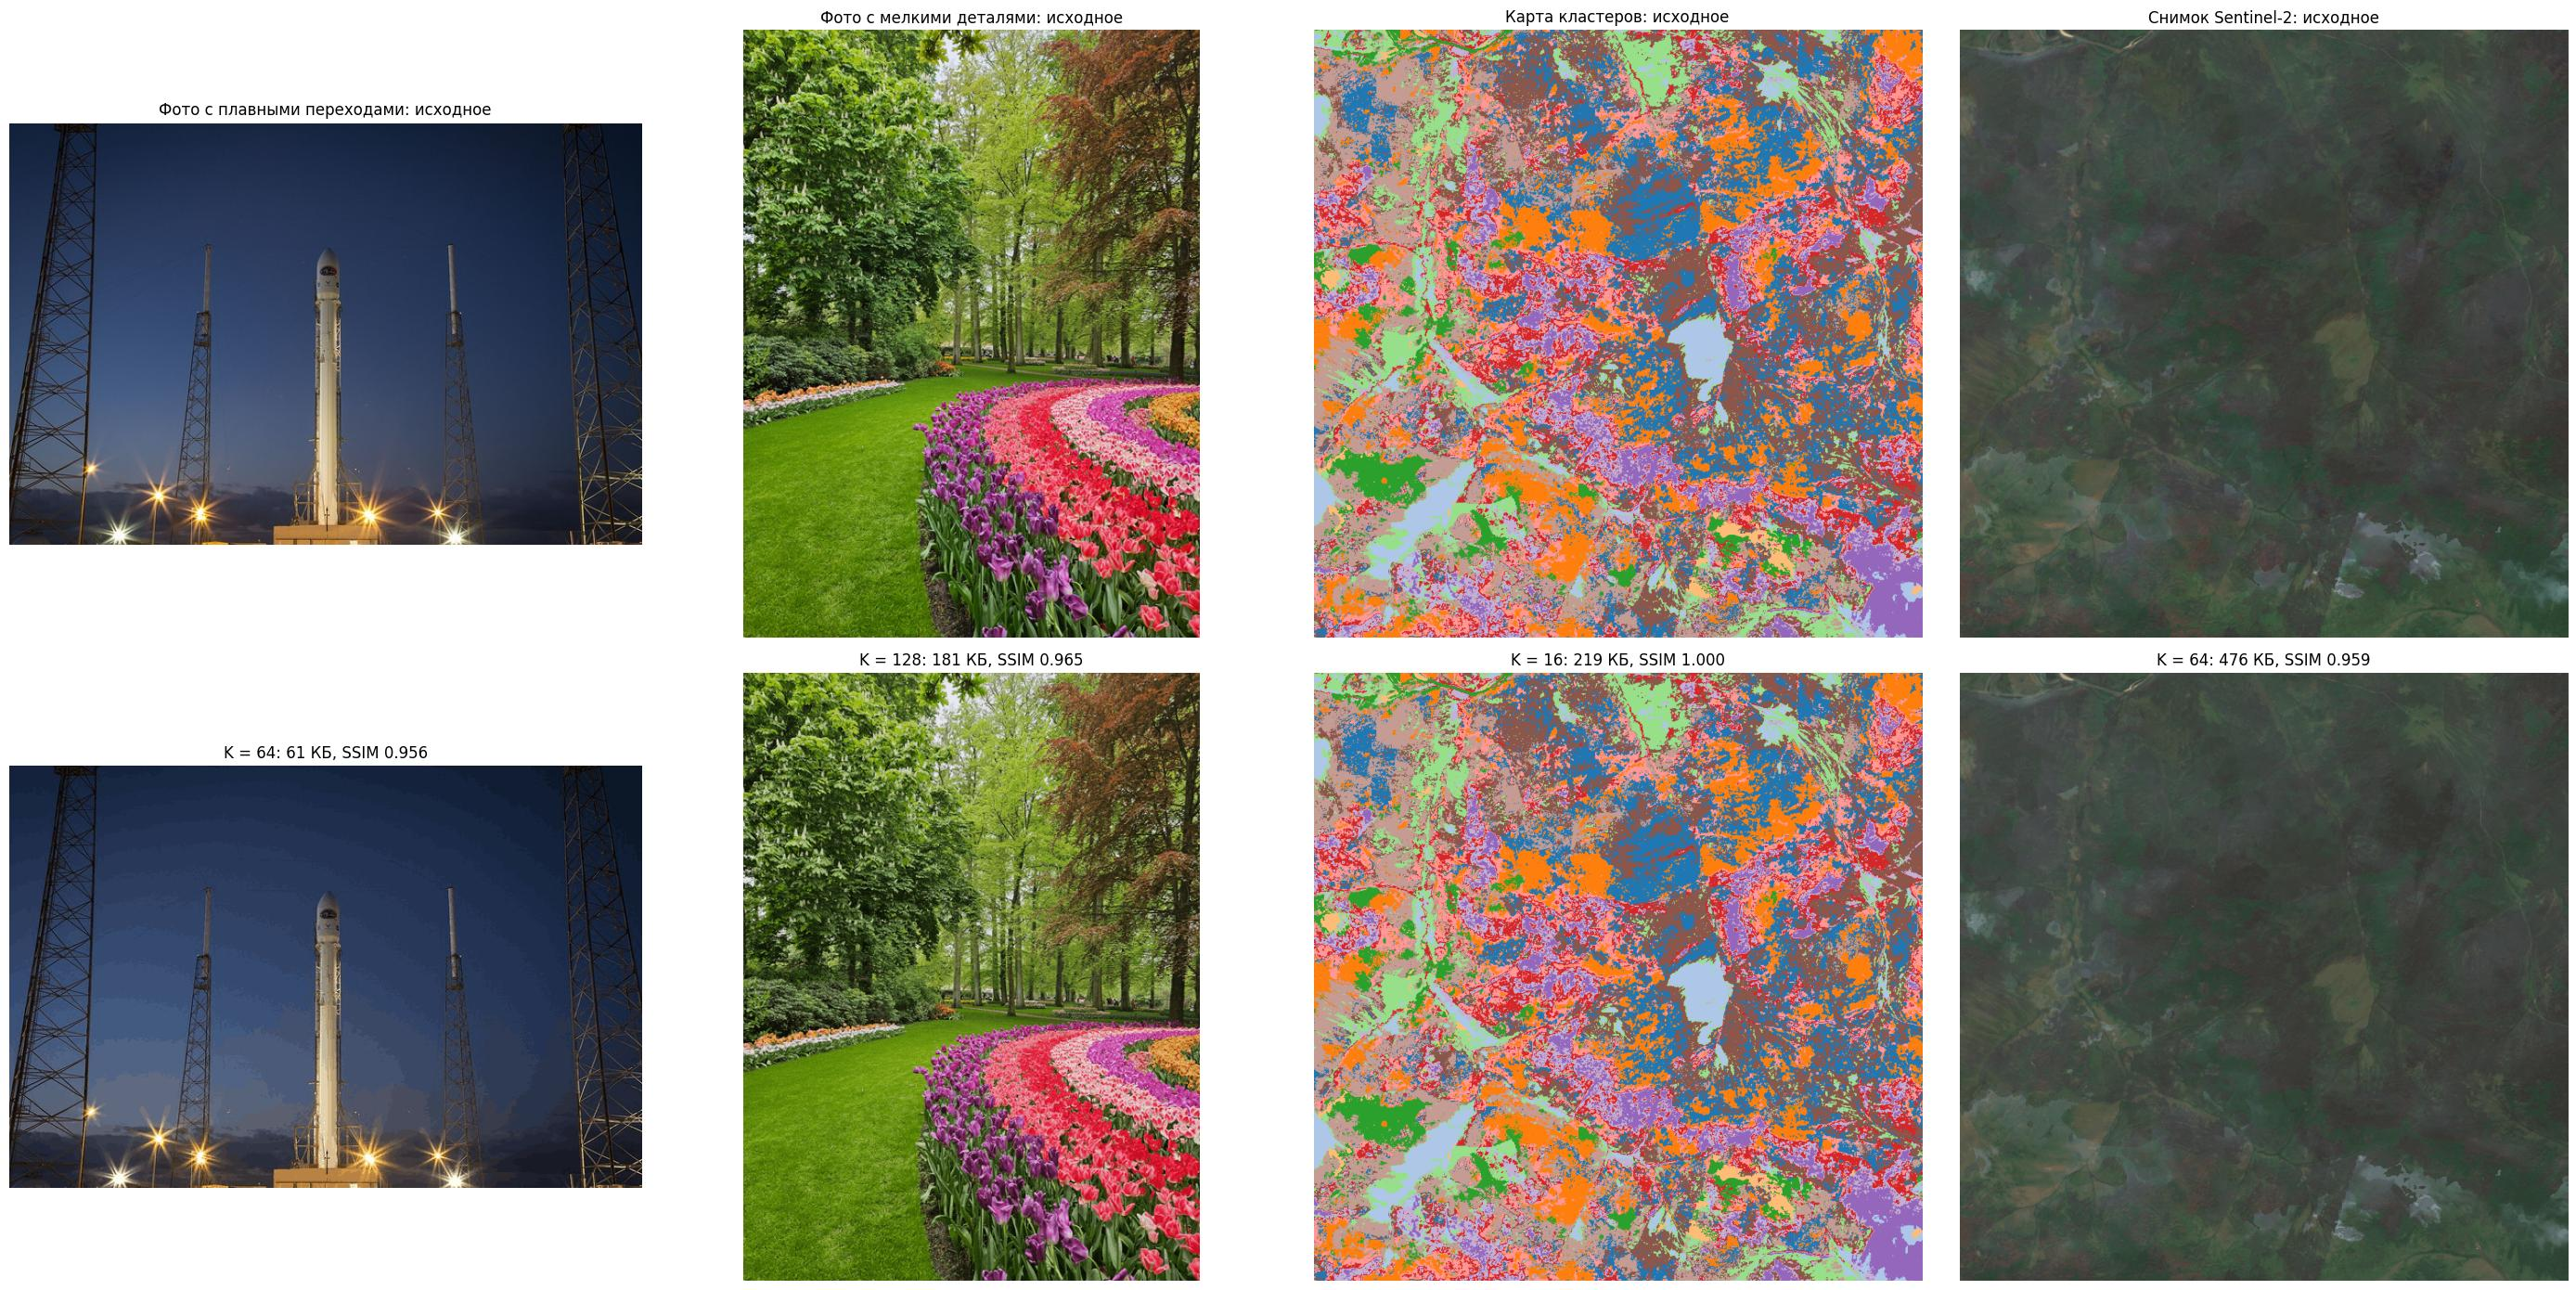

compressed.tar.xz


In [14]:
#@title Готовый код: исходные изображения и выбранное число цветов
fig, axes = plt.subplots(2, len(images), figsize=(7 * len(images), 14))
for j, (name, img) in enumerate(images.items()):
    k = int(choice.loc[name, 'K'])
    palette, indices = quantized[(name, k)]
    axes[0, j].imshow(img)
    axes[0, j].set_title(f'{name}: исходное')
    axes[1, j].imshow(palette[indices])
    axes[1, j].set_title(f'K = {k}: {choice.loc[name, "Палитровый PNG, КБ"]:.0f} КБ, SSIM {choice.loc[name, "SSIM"]:.3f}')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()
import shutil
shutil.make_archive("compressed", "xztar", root_dir=".", base_dir="compressed")
print("compressed.tar.xz")


**Вопрос:** Для каких изображений палитровый PNG при малозаметных искажениях меньше JPEG 90, а для каких — больше? Чем отличаются эти изображения? Какой способ хранения вы выберете для фотографий, для тематических карт и для снимков в естественных цветах?

**Ответ:**

| Изображение | Наименьшее K при SSIM ≥ 0,95 | SSIM | Палитровый PNG / JPEG 90 |
|---|---|---|---|
| Фото с небом | 64 | 0,9559 | 1,24 |
| Фото с тюльпанами | 128 | 0,9652 | 1,16 |
| Карта кластеров | 16 | 1,0000 | 0,33 |
| Снимок Sentinel-2 | 64 | 0,9586 | 3,07 |

У карты 12 разных цветов. Палитровый PNG сохранил их точно и занял 219,46 КБ. JPEG той же карты занял 666,91 КБ, в 3,04 раза больше. Для карты я бы взял палитровый PNG, чтобы сохранить цвета классов и их границы.

Для обычного просмотра фотографий и снимка в естественных цветах я бы взял JPEG. В этих трёх случаях он компактнее. Если важен порог SSIM 0,95, у цветника JPEG 90 дал только 0,9327, а у Sentinel-2 — 0,9423. Выбранные в таблице палитры этот порог прошли.

### **6.8. Выводы по разделу 6**

Опишите, при каких условиях кластеризация цветов уменьшает размер файла, как правильно сохранять результат, как связаны число цветов, размер и качество, и чем K-средних отличается от встроенной квантизации.

**Вывод:** После кластеризации нужно сохранить PNG с палитрой и номером цвета для каждого пикселя. На карте при 16 цветах размер уменьшился с 391,06 до 219,46 КБ. Цвета совпали с исходными. На фотографиях 16 цветов тоже экономят место, но на небе появляются полосы, а на цветах пропадают мелкие оттенки.

Чем больше цветов, тем обычно выше качество и больше файл. Для SSIM от 0,95 у неба хватило 64 цветов, а у тюльпанов понадобилось 128. На спутниковом снимке хватило 64. На карте увеличивать палитру дальше 16 цветов уже нет смысла для качества. K-средних лучше передал цвета фотографий по PSNR, а встроенный метод PIL при 64 цветах сработал быстрее.

---

## **7. Итоговые выводы**

В выводах обязательно отразить:
1. **Территория и найденные объекты**: что нашла кластеризация, их площадь, вид в естественных цветах и в инфракрасных каналах;
2. **Классификация по Dynamic World**: точность при случайной и пространственной проверке, лучший классификатор, проблемные классы, совпадение карты с Dynamic World;
3. **Классификация и кластеризация**: что может и чего не может каждый подход на вашей территории;
4. **Сжатие изображений**: для каких изображений и при каком числе цветов кластеризация выгодна, во сколько раз уменьшается размер;
5. **Возможное практическое применение** полученных результатов.

**Выводы:**

1. Мой номер в списке — 20, вариант — 6: тайга в Забайкальском крае. Исследован летний композит 2024 года из 12 снимков. Кластер 2 похож на гари: тёмно-бурые участки в обычных цветах и красно-коричневые в B12–B8–B4. Он занимает 2385,61 га, или 12,19% площади с данными. Это площадь выбранного кластера, а не подтверждённая площадь пожара.
2. Лучший классификатор — Random Forest. При случайной проверке точность 63,06%, каппа 0,5691; при пространственной — 58,99% и 0,5212. Лучше распознаётся вода, хуже — кустарники. Своя карта совпала с Dynamic World в 53,93% пикселей.
3. Классификация распределяет пиксели по готовым названиям, поэтому отдельную гарь она не выделяет. Кластеризация находит похожие по спектру поверхности без этих названий. Но кластеры нужно проверять по снимку: самым необычным оказался кластер, похожий на остатки облаков. При K = 6 выбранные гари смешиваются с другими участками, при K = 12 отделяются, при K = 18 дробятся.
4. При 16 цветах палитровый PNG меньше обычного PNG в 7,56 раза для неба, в 6,31 раза для тюльпанов, в 1,78 раза для карты и в 4,52 раза для снимка. Чтобы получить SSIM от 0,95, понадобилось 64, 128, 16 и 64 цветов соответственно. Меньше исходного JPEG 90 получилась только карта — в 3,04 раза. При этом её цвета сохранились точно.
5. Такой анализ можно использовать для поиска повреждённых лесных участков и выбора мест для дальнейшей проверки. Кластеризация сокращает область поиска, а снимки до и после пожара помогут проверить, действительно ли это гари. Сжатие палитрой полезно для хранения и передачи тематических карт.

---

## **Что сдавать**

1. Выполненный блокнот со всеми выводами ячеек и заполненными ответами (таблицы 2 и 3, ответы на вопросы, выводы по разделам 4–6 и итоговые выводы).
2. Папку `compressed` с файлами раздела 6 (в архиве).

## **Дополнительные задания (выполняются по желанию)**

1. **Перенос модели.** Примените классификатор, обученный на своей территории, к композиту другой территории из таблицы 1 и рассчитайте совпадение с Dynamic World. Сравните с точностью пространственной проверки и объясните разницу.
2. **Поиск по эталону.** Возьмите центроиды «иголок» своей территории и найдите на другой территории пиксели, ближе всего к ним расположенные в пространстве стандартизированных признаков. Нашлись ли объекты того же типа?
3. **Собственная реализация K-средних.** Напишите K-средних для цветов на NumPy (инициализация, назначение пикселей, пересчёт центроидов, остановка по сдвигу центроидов) и сравните с `KMeans` по времени, числу итераций и PSNR при $K = 16$.
4. **Другое цветовое пространство.** Выполните квантизацию фотографий в пространстве CIELAB (`skimage.color.rgb2lab`), где евклидово расстояние ближе к различию цветов, воспринимаемому глазом, и сравните SSIM с квантизацией в RGB при одинаковом $K$.